In [ ]:
# ============================================================
# Pure Custom CNN (No External Backbone Dependencies)
# Optimized for Small Datasets (Targeting High Accuracy)
# ============================================================

import os
import glob
import gc
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.io import read_image, ImageReadMode
import torchvision.transforms.v2 as transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# GPU Setup
gc.collect()
torch.cuda.empty_cache()
torch.backends.cudnn.benchmark = True

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# 1. CONFIGURATION & DATASETS
# ------------------------------------------------------------
BASE_DATASET_PATH = "/kaggle/input/datasets/evangelinnisha/archive-7"
IMAGE_SIZE = 128         # Smaller resolution prevents overfitting when training from scratch
BATCH_SIZE = 16
NUM_CLASSES = 8
SAMPLES_PER_CLASS = 400
EPOCHS = 35              # More epochs required when training from scratch

DATASET_PATH = BASE_DATASET_PATH
for root, dirs, files in os.walk(BASE_DATASET_PATH):
    if len(dirs) >= NUM_CLASSES and "test" not in os.path.basename(root).lower():
        DATASET_PATH = root
        break

class_names = sorted([d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d))])[:NUM_CLASSES]

filepaths, labels = [], []
for idx, cname in enumerate(class_names):
    c_path = os.path.join(DATASET_PATH, cname)
    imgs = glob.glob(os.path.join(c_path, "*.*"))
    for img in imgs:
        filepaths.append(img)
        labels.append(idx)

# Stratified Splits (70% Train, 15% Val, 15% Test)
train_files, test_files, train_labels, test_labels = train_test_split(
    filepaths, labels, test_size=0.30, random_state=42, stratify=labels
)
val_files, test_files, val_labels, test_labels = train_test_split(
    test_files, test_labels, test_size=0.50, random_state=42, stratify=test_labels
)

class PlantDataset(Dataset):
    def __init__(self, filepaths, labels):
        self.filepaths = filepaths
        self.labels = labels
        self.resize = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True)

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img = read_image(self.filepaths[idx], mode=ImageReadMode.RGB)
        img = self.resize(img).float() / 255.0
        return img, self.labels[idx]

train_dataset = PlantDataset(train_files, train_labels)
val_dataset = PlantDataset(val_files, val_labels)
test_dataset = PlantDataset(test_files, test_labels)

class_counts = np.bincount(train_labels)
class_weights = 1.0 / class_counts
sample_weights = np.array([class_weights[t] for t in train_labels])

sampler = WeightedRandomSampler(
    weights=torch.from_numpy(sample_weights).double(),
    num_samples=SAMPLES_PER_CLASS * NUM_CLASSES,
    replacement=True
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Heavy Data Augmentations (Essential when training from scratch)
gpu_augment = nn.Sequential(
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
).to(device)

gpu_val_transform = transforms.Normalize(
    mean=[0.485, 0.456, 0.406], 
    std=[0.229, 0.224, 0.225]
).to(device)

# ------------------------------------------------------------
# 2. CUSTOM LIGHTWEIGHT CNN ARCHITECTURE (NO PRETRAINED BACKBONE)
# ------------------------------------------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.SiLU(),
            nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.SiLU(),
            nn.MaxPool2d(2, 2)
        )
    def forward(self, x):
        return self.conv(x)

class CustomNoBackboneCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),    # Output: 32 x 64 x 64
            ConvBlock(32, 64),   # Output: 64 x 32 x 32
            ConvBlock(64, 128),  # Output: 128 x 16 x 16
            ConvBlock(128, 256)  # Output: 256 x 8 x 8
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)

model = CustomNoBackboneCNN(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)
scaler = torch.amp.GradScaler('cuda')

# ------------------------------------------------------------
# 3. TRAINING & EVALUATION LOOP
# ------------------------------------------------------------
BEST_CHECKPOINT_PATH = "/kaggle/working/CustomCNN_NoBackbone.pth"
best_val_acc = 0.0

print("\nStarting Training Execution (Custom CNN Built From Scratch)...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_correct, total_train = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        images = gpu_augment(images)
        
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()
        total_train += images.size(0)

    scheduler.step()
    epoch_train_acc = train_correct / total_train

    # Validation Loop
    model.eval()
    val_correct, total_val = 0, 0
    with torch.inference_mode():
        for images, labels in val_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            images = gpu_val_transform(images)

            with torch.amp.autocast('cuda'):
                outputs = model(images)

            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            total_val += images.size(0)

    epoch_val_acc = val_correct / total_val
    print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train Acc: {epoch_train_acc:.4f} | Val Acc: {epoch_val_acc:.4f}")

    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), BEST_CHECKPOINT_PATH)

print(f"\nPEAK VALIDATION ACCURACY ACHIEVED: {best_val_acc * 100:.2f}%")


Starting Training Execution (Custom CNN Built From Scratch)...
Epoch [01/35] | Train Acc: 0.2750 | Val Acc: 0.2706
Epoch [02/35] | Train Acc: 0.3300 | Val Acc: 0.2824


In [2]:
# ============================================================
# CELL 2: INSPECT PLANTDOC DATASET STRUCTURE
# ============================================================

PLANTDOC_DIR = DATASET_DIR / "PlantDoc-Dataset"

print("=" * 70)
print("PLANTDOC DATASET STRUCTURE")
print("=" * 70)

print("Dataset path:")
print(PLANTDOC_DIR)

print("\nPath exists:", PLANTDOC_DIR.exists())

print("\nContents:")
for item in sorted(PLANTDOC_DIR.iterdir()):
    if item.is_dir():
        print(f"📁 {item.name}")
    else:
        print(f"📄 {item.name}")

PLANTDOC DATASET STRUCTURE
Dataset path:
/kaggle/input/datasets/evangelinnisha/archive-7/PlantDoc-Dataset

Path exists: True

Contents:
📁 test
📁 train


In [3]:
# ============================================================
# CELL 3: COUNT ALL PLANTDOC CLASSES
# ============================================================

TRAIN_DIR = PLANTDOC_DIR / "train"
TEST_DIR  = PLANTDOC_DIR / "test"

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# ------------------------------------------------------------
# Get class names
# ------------------------------------------------------------
class_names = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

print("=" * 90)
print("PLANTDOC DATASET — COMPLETE CLASS DISTRIBUTION")
print("=" * 90)

print(f"\nNumber of classes found: {len(class_names)}")

# ------------------------------------------------------------
# Count images in train and test
# ------------------------------------------------------------
records = []

for class_name in class_names:

    train_class_dir = TRAIN_DIR / class_name
    test_class_dir  = TEST_DIR / class_name

    train_count = sum(
        1 for f in train_class_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )

    test_count = sum(
        1 for f in test_class_dir.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )

    total_count = train_count + test_count

    records.append({
        "Class": class_name,
        "Train": train_count,
        "Test": test_count,
        "Total": total_count
    })

# ------------------------------------------------------------
# Create table
# ------------------------------------------------------------
class_df = pd.DataFrame(records)

class_df = class_df.sort_values(
    by="Total",
    ascending=False
).reset_index(drop=True)

class_df.insert(
    0,
    "Rank",
    range(1, len(class_df) + 1)
)

print("\n")
print(class_df.to_string(index=False))

# ------------------------------------------------------------
# Dataset totals
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("DATASET TOTALS")
print("=" * 90)

print("Total training images :", class_df["Train"].sum())
print("Total testing images  :", class_df["Test"].sum())
print("Total images          :", class_df["Total"].sum())
print("Total classes         :", len(class_df))

PLANTDOC DATASET — COMPLETE CLASS DISTRIBUTION

Number of classes found: 27


 Rank                      Class  Train  Test  Total
    1           Corn leaf blight    180    12    192
    2  Tomato Septoria leaf spot    137    11    148
    3 Squash Powdery mildew leaf    123     6    129
    4   Potato leaf early blight    109     8    117
    5             Raspberry leaf    109     7    116
    6             Blueberry leaf    105    11    116
    7             Corn rust leaf    106    10    116
    8                 Peach leaf    103     9    112
    9    Tomato leaf late blight    101    10    111
   10 Tomato leaf bacterial spot     98     9    107
   11    Potato leaf late blight     97     8    105
   12            Strawberry leaf     88     8     96
   13           Tomato mold leaf     85     6     91
   14                 Apple leaf     82     9     91
   15            Apple rust leaf     79    10     89
   16            Apple Scab Leaf     77    10     87
   17   Tomato Early 

In [4]:
# ============================================================
# CELL 4: FINAL 6 SELECTED CLASSES
# ============================================================

SELECTED_CLASSES = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Blueberry leaf",
    "Corn rust leaf"
]

print("=" * 80)
print("FINAL SELECTED PLANTDOC CLASSES")
print("=" * 80)

print(f"\nNumber of selected classes: {len(SELECTED_CLASSES)}")

for i, class_name in enumerate(SELECTED_CLASSES, start=1):
    total = class_df.loc[
        class_df["Class"] == class_name,
        "Total"
    ].iloc[0]

    print(f"{i}. {class_name} : {total} images")

selected_total = class_df[
    class_df["Class"].isin(SELECTED_CLASSES)
]["Total"].sum()

print("\n" + "-" * 80)
print("TOTAL ORIGINAL IMAGES:", selected_total)
print("-" * 80)

assert len(SELECTED_CLASSES) == 6
assert selected_total == 818

print("\n✅ Final 6 classes confirmed")
print("✅ Total = 818 original images")

FINAL SELECTED PLANTDOC CLASSES

Number of selected classes: 6
1. Corn leaf blight : 192 images
2. Tomato Septoria leaf spot : 148 images
3. Squash Powdery mildew leaf : 129 images
4. Potato leaf early blight : 117 images
5. Blueberry leaf : 116 images
6. Corn rust leaf : 116 images

--------------------------------------------------------------------------------
TOTAL ORIGINAL IMAGES: 818
--------------------------------------------------------------------------------

✅ Final 6 classes confirmed
✅ Total = 818 original images


In [5]:
# ============================================================
# CELL 5: COLLECT ALL 818 ORIGINAL IMAGES
# ============================================================

all_records = []

for class_name in SELECTED_CLASSES:

    # Original train images
    train_class_dir = TRAIN_DIR / class_name

    for file_path in train_class_dir.iterdir():
        if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTENSIONS:
            all_records.append({
                "filepath": str(file_path),
                "class": class_name
            })

    # Original test images
    test_class_dir = TEST_DIR / class_name

    for file_path in test_class_dir.iterdir():
        if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTENSIONS:
            all_records.append({
                "filepath": str(file_path),
                "class": class_name
            })

all_df = pd.DataFrame(all_records)

print("=" * 80)
print("COMBINED ORIGINAL DATASET")
print("=" * 80)

print("\nTotal images collected:", len(all_df))
print("Number of classes      :", all_df["class"].nunique())

print("\nClass distribution:")
print(
    all_df["class"]
    .value_counts()
    .reindex(SELECTED_CLASSES)
)

# Safety checks
assert len(all_df) == 818
assert all_df["class"].nunique() == 6
assert all_df["filepath"].isna().sum() == 0

print("\n✅ All 818 original images collected successfully")
print("✅ No missing file paths")
print("✅ All 6 selected classes present")

COMBINED ORIGINAL DATASET

Total images collected: 818
Number of classes      : 6

Class distribution:
class
Corn leaf blight              192
Tomato Septoria leaf spot     148
Squash Powdery mildew leaf    129
Potato leaf early blight      117
Blueberry leaf                116
Corn rust leaf                116
Name: count, dtype: int64

✅ All 818 original images collected successfully
✅ No missing file paths
✅ All 6 selected classes present


In [6]:
# ============================================================
# CELL 6: STRATIFIED 70:15:15 SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# First split: 70% TRAIN + 30% TEMP
# ------------------------------------------------------------
train_df, temp_df = train_test_split(
    all_df,
    test_size=0.30,
    stratify=all_df["class"],
    random_state=SEED
)

# ------------------------------------------------------------
# Second split:
# TEMP = 30%
# Split equally into:
#   15% VALIDATION
#   15% TEST
# ------------------------------------------------------------
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=SEED
)

# ------------------------------------------------------------
# Reset indexes
# ------------------------------------------------------------
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# Add split information
# ------------------------------------------------------------
train_df["split"] = "train"
val_df["split"]   = "validation"
test_df["split"]  = "test"

# ------------------------------------------------------------
# Display total counts
# ------------------------------------------------------------
print("=" * 90)
print("STRATIFIED 70:15:15 DATASET SPLIT")
print("=" * 90)

print("\nOverall sample counts:")
print("-" * 50)

print(f"Training   : {len(train_df)}")
print(f"Validation : {len(val_df)}")
print(f"Testing    : {len(test_df)}")
print(f"Total      : {len(train_df) + len(val_df) + len(test_df)}")

# ------------------------------------------------------------
# Calculate percentages
# ------------------------------------------------------------
total = len(all_df)

print("\nActual percentages:")
print("-" * 50)

print(f"Training   : {len(train_df)/total*100:.2f}%")
print(f"Validation : {len(val_df)/total*100:.2f}%")
print(f"Testing    : {len(test_df)/total*100:.2f}%")

# ------------------------------------------------------------
# Class-wise distribution
# ------------------------------------------------------------
split_table = pd.DataFrame({
    "Class": SELECTED_CLASSES,
    "Total": [
        len(all_df[all_df["class"] == c])
        for c in SELECTED_CLASSES
    ],
    "Train": [
        len(train_df[train_df["class"] == c])
        for c in SELECTED_CLASSES
    ],
    "Validation": [
        len(val_df[val_df["class"] == c])
        for c in SELECTED_CLASSES
    ],
    "Test": [
        len(test_df[test_df["class"] == c])
        for c in SELECTED_CLASSES
    ]
})

print("\n" + "=" * 90)
print("CLASS-WISE SPLIT")
print("=" * 90)

print(split_table.to_string(index=False))

# ------------------------------------------------------------
# Verify no overlap between splits
# ------------------------------------------------------------
train_paths = set(train_df["filepath"])
val_paths   = set(val_df["filepath"])
test_paths  = set(test_df["filepath"])

print("\n" + "=" * 90)
print("DATA LEAKAGE CHECK")
print("=" * 90)

print("Train ∩ Validation :", len(train_paths & val_paths))
print("Train ∩ Test       :", len(train_paths & test_paths))
print("Validation ∩ Test  :", len(val_paths & test_paths))

assert len(train_paths & val_paths) == 0
assert len(train_paths & test_paths) == 0
assert len(val_paths & test_paths) == 0

assert len(train_df) + len(val_df) + len(test_df) == 818

print("\n✅ Stratified 70:15:15 split completed")
print("✅ No image overlap between train/validation/test")
print("✅ Total images = 818")

STRATIFIED 70:15:15 DATASET SPLIT

Overall sample counts:
--------------------------------------------------
Training   : 572
Validation : 123
Testing    : 123
Total      : 818

Actual percentages:
--------------------------------------------------
Training   : 69.93%
Validation : 15.04%
Testing    : 15.04%

CLASS-WISE SPLIT
                     Class  Total  Train  Validation  Test
          Corn leaf blight    192    134          29    29
 Tomato Septoria leaf spot    148    104          22    22
Squash Powdery mildew leaf    129     90          20    19
  Potato leaf early blight    117     82          17    18
            Blueberry leaf    116     81          17    18
            Corn rust leaf    116     81          18    17

DATA LEAKAGE CHECK
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✅ Stratified 70:15:15 split completed
✅ No image overlap between train/validation/test
✅ Total images = 818


In [7]:
# ============================================================
# CELL 7: TRAINING-ONLY DATA AUGMENTATION
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ------------------------------------------------------------
# Training augmentation
# ------------------------------------------------------------
train_augmentation = keras.Sequential([
    
    # Horizontal flipping
    layers.RandomFlip(
        mode="horizontal",
        seed=SEED
    ),
    
    # Small rotation
    layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect",
        seed=SEED
    ),
    
    # Small zoom
    layers.RandomZoom(
        height_factor=(-0.10, 0.10),
        width_factor=(-0.10, 0.10),
        fill_mode="reflect",
        seed=SEED
    ),
    
    # Small translation
    layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="reflect",
        seed=SEED
    ),
    
    # Small brightness variation
    layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255),
        seed=SEED
    ),
    
    # Small contrast variation
    layers.RandomContrast(
        factor=0.10,
        seed=SEED
    ),

], name="PlantDisease_Training_Augmentation")


print("=" * 80)
print("TRAINING AUGMENTATION PIPELINE")
print("=" * 80)

print("\nAugmentations enabled:")
print("1. Horizontal Flip")
print("2. Random Rotation")
print("3. Random Zoom")
print("4. Random Translation")
print("5. Random Brightness")
print("6. Random Contrast")

print("\n✅ Augmentation pipeline created")
print("✅ Applied ONLY to training images")
print("❌ Validation images will NOT be augmented")
print("❌ Test images will NOT be augmented")

TRAINING AUGMENTATION PIPELINE

Augmentations enabled:
1. Horizontal Flip
2. Random Rotation
3. Random Zoom
4. Random Translation
5. Random Brightness
6. Random Contrast

✅ Augmentation pipeline created
✅ Applied ONLY to training images
❌ Validation images will NOT be augmented
❌ Test images will NOT be augmented


I0000 00:00:1791258490.044239      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791258490.048550      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [8]:
# ============================================================
# CELL 8: CREATE CLASS-BALANCED TRAINING FILE LISTS
# ============================================================

TARGET_IMAGES_PER_CLASS = 500

balanced_train_records = []

print("=" * 90)
print("BUILDING BALANCED TRAINING SET")
print("=" * 90)

print("\nOriginal training distribution:")
print("-" * 60)

for class_name in SELECTED_CLASSES:

    class_data = train_df[
        train_df["class"] == class_name
    ].copy()

    original_count = len(class_data)

    print(
        f"{class_name:<32} : "
        f"{original_count:>3} original → "
        f"{TARGET_IMAGES_PER_CLASS:>3} training samples"
    )

    # --------------------------------------------------------
    # Oversample with replacement to exactly 500
    # --------------------------------------------------------
    sampled_data = class_data.sample(
        n=TARGET_IMAGES_PER_CLASS,
        replace=True,
        random_state=SEED
    ).copy()

    sampled_data["class"] = class_name

    balanced_train_records.append(sampled_data)

# ------------------------------------------------------------
# Combine all classes
# ------------------------------------------------------------
balanced_train_df = pd.concat(
    balanced_train_records,
    ignore_index=True
)

# ------------------------------------------------------------
# Shuffle
# ------------------------------------------------------------
balanced_train_df = balanced_train_df.sample(
    frac=1.0,
    random_state=SEED
).reset_index(drop=True)

# ------------------------------------------------------------
# Display distribution
# ------------------------------------------------------------
print("\n" + "=" * 90)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 90)

balanced_counts = (
    balanced_train_df["class"]
    .value_counts()
    .reindex(SELECTED_CLASSES)
)

print(balanced_counts)

print("\n" + "-" * 60)

print("Original training images :", len(train_df))
print("Balanced training images :", len(balanced_train_df))
print("Target per class         :", TARGET_IMAGES_PER_CLASS)
print("Number of classes        :", NUM_CLASSES)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
assert len(balanced_train_df) == 3000

for class_name in SELECTED_CLASSES:
    assert (
        balanced_train_df["class"]
        .value_counts()[class_name]
        == TARGET_IMAGES_PER_CLASS
    )

print("\n✅ Every class has exactly 500 training samples")
print("✅ Total balanced training samples = 3000")
print("✅ Sampling uses TRAINING data only")

BUILDING BALANCED TRAINING SET

Original training distribution:
------------------------------------------------------------
Corn leaf blight                 : 134 original → 500 training samples
Tomato Septoria leaf spot        : 104 original → 500 training samples
Squash Powdery mildew leaf       :  90 original → 500 training samples
Potato leaf early blight         :  82 original → 500 training samples
Blueberry leaf                   :  81 original → 500 training samples
Corn rust leaf                   :  81 original → 500 training samples

BALANCED TRAINING DISTRIBUTION
class
Corn leaf blight              500
Tomato Septoria leaf spot     500
Squash Powdery mildew leaf    500
Potato leaf early blight      500
Blueberry leaf                500
Corn rust leaf                500
Name: count, dtype: int64

------------------------------------------------------------
Original training images : 572
Balanced training images : 3000
Target per class         : 500
Number of classes        

In [9]:
# ============================================================
# CELL 9: CREATE TENSORFLOW TRAINING DATASET
# ============================================================

# ------------------------------------------------------------
# Class-to-index mapping
# ------------------------------------------------------------
class_to_index = {
    class_name: idx
    for idx, class_name in enumerate(SELECTED_CLASSES)
}

print("=" * 80)
print("CLASS LABEL MAPPING")
print("=" * 80)

for class_name, idx in class_to_index.items():
    print(f"{idx} → {class_name}")


# ------------------------------------------------------------
# Convert file paths and labels
# ------------------------------------------------------------
train_paths = balanced_train_df["filepath"].values

train_labels = np.array([
    class_to_index[class_name]
    for class_name in balanced_train_df["class"]
])


# ------------------------------------------------------------
# Image loading function
# ------------------------------------------------------------
def load_and_preprocess_image(filepath, label):
    
    image = tf.io.read_file(filepath)
    
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    
    image.set_shape([None, None, 3])
    
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )
    
    image = tf.cast(image, tf.float32)
    
    return image, label


# ------------------------------------------------------------
# Create training dataset
# ------------------------------------------------------------
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_dataset = train_dataset.shuffle(
    buffer_size=len(train_paths),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_dataset = train_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# ------------------------------------------------------------
# Apply augmentation ONLY to training
# ------------------------------------------------------------
train_dataset = train_dataset.map(
    lambda x, y: (
        train_augmentation(x, training=True),
        y
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

# ------------------------------------------------------------
# Batch and prefetch
# ------------------------------------------------------------
train_dataset = train_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
)

train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)


print("\n" + "=" * 80)
print("TRAINING DATASET CREATED")
print("=" * 80)

print("Training samples :", len(train_paths))
print("Batch size       :", BATCH_SIZE)
print(
    "Training batches :",
    int(np.ceil(len(train_paths) / BATCH_SIZE))
)

print("\nAugmentation:")
print("✅ Applied during training")
print("✅ Random transformations generated dynamically")
print("✅ No augmented files saved to disk")

print("\n✅ Training dataset ready")

CLASS LABEL MAPPING
0 → Corn leaf blight
1 → Tomato Septoria leaf spot
2 → Squash Powdery mildew leaf
3 → Potato leaf early blight
4 → Blueberry leaf
5 → Corn rust leaf

TRAINING DATASET CREATED
Training samples : 3000
Batch size       : 16
Training batches : 188

Augmentation:
✅ Applied during training
✅ Random transformations generated dynamically
✅ No augmented files saved to disk

✅ Training dataset ready


In [10]:
# ============================================================
# CELL 10: CREATE VALIDATION & TEST DATASETS
# ============================================================

# ------------------------------------------------------------
# Validation labels
# ------------------------------------------------------------
val_paths = val_df["filepath"].values

val_labels = np.array([
    class_to_index[class_name]
    for class_name in val_df["class"]
])

# ------------------------------------------------------------
# Test labels
# ------------------------------------------------------------
test_paths = test_df["filepath"].values

test_labels = np.array([
    class_to_index[class_name]
    for class_name in test_df["class"]
])


# ------------------------------------------------------------
# Image loading function for validation/test
# ------------------------------------------------------------
def load_eval_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label


# ============================================================
# VALIDATION DATASET
# ============================================================

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_dataset = val_dataset.map(
    load_eval_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.batch(
    BATCH_SIZE
)

val_dataset = val_dataset.prefetch(
    tf.data.AUTOTUNE
)


# ============================================================
# TEST DATASET
# ============================================================

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_dataset = test_dataset.map(
    load_eval_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(
    BATCH_SIZE
)

test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 80)
print("VALIDATION & TEST DATASETS")
print("=" * 80)

print("\nValidation:")
print("Samples :", len(val_paths))
print(
    "Batches :",
    int(np.ceil(len(val_paths) / BATCH_SIZE))
)

print("\nTest:")
print("Samples :", len(test_paths))
print(
    "Batches :",
    int(np.ceil(len(test_paths) / BATCH_SIZE))
)

print("\nAugmentation:")
print("Training   : ✅")
print("Validation : ❌")
print("Test       : ❌")

print("\n✅ Validation and test datasets ready")

VALIDATION & TEST DATASETS

Validation:
Samples : 123
Batches : 8

Test:
Samples : 123
Batches : 8

Augmentation:
Training   : ✅
Validation : ❌
Test       : ❌

✅ Validation and test datasets ready


In [14]:
import os

font_folder = "/kaggle/input/datasets/evangelinnisha/time111"

print(os.listdir(font_folder))

['Times New Roman Bold.ttf']


In [15]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = "/kaggle/input/datasets/evangelinnisha/time111/Times New Roman Bold.ttf"

fm.fontManager.addfont(font_path)

font_name = fm.FontProperties(fname=font_path).get_name()

plt.rcParams["font.family"] = font_name

print("✅ Times New Roman Bold imported successfully!")
print("Font:", font_name)

✅ Times New Roman Bold imported successfully!
Font: Times New Roman


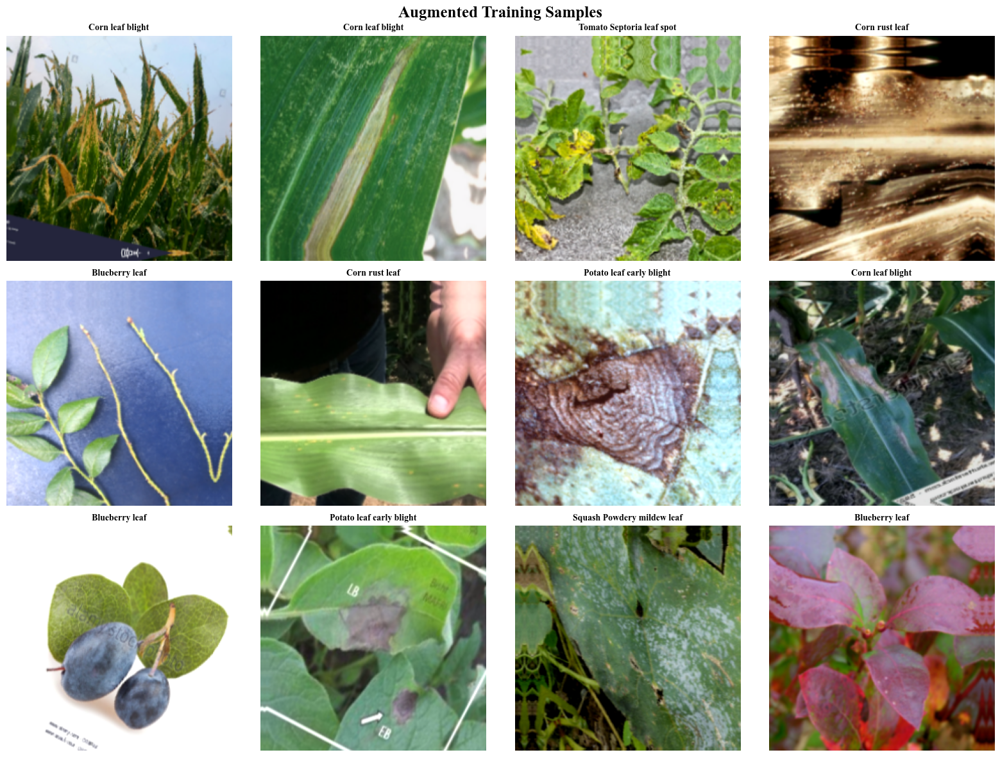

FIGURE SAVED
/kaggle/working/Augmented_Training_Samples.png


/kaggle/working/Augmented_Training_Samples.png

In [16]:
# ============================================================
# SAVE AUGMENTED TRAINING SAMPLES
# ============================================================

import matplotlib.pyplot as plt
from IPython.display import FileLink, display

# Create the figure again
fig = plt.figure(figsize=(16, 12))

for i in range(NUM_DISPLAY):

    ax = plt.subplot(3, 4, i + 1)

    image = sample_images[i].numpy()
    image = np.clip(image, 0, 255).astype(np.uint8)

    label_index = int(sample_labels[i].numpy())

    ax.imshow(image)
    ax.set_title(
        SELECTED_CLASSES[label_index],
        fontsize=10
    )
    ax.axis("off")

fig.suptitle(
    "Augmented Training Samples",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

# Save high-resolution image
output_path = "/kaggle/working/Augmented_Training_Samples.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("=" * 70)
print("FIGURE SAVED")
print("=" * 70)
print(output_path)

# Download link
display(FileLink(output_path))

In [17]:
# ============================================================
# CELL 12: INSTALL / CHECK KERAS HUB
# ============================================================

!pip install -q -U keras-hub

import keras_hub

print("=" * 80)
print("KERAS HUB")
print("=" * 80)

print("KerasHub version:", keras_hub.__version__)

print("\n✅ KerasHub is ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 20.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 68.0 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.
KERAS HUB
KerasHub version: 0.32.0

✅ KerasHub is ready


In [18]:
# ============================================================
# CELL 13: LOAD PRETRAINED SWIN-TINY
# ============================================================

import keras_hub

print("=" * 80)
print("LOADING PRETRAINED SWIN-TINY")
print("=" * 80)

SWIN_PRESET = "swin_tiny_patch4_window7_224"

swin_backbone = keras_hub.models.Backbone.from_preset(
    SWIN_PRESET,
    load_weights=True
)

print("\n✅ Pretrained Swin-Tiny loaded successfully")

print("\nModel:")
print(swin_backbone)

print("\nNumber of parameters:")
print(f"{swin_backbone.count_params():,}")

LOADING PRETRAINED SWIN-TINY


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  with self._open_name_scope():



✅ Pretrained Swin-Tiny loaded successfully

Model:
<SwinTransformerBackbone name=swin_transformer_backbone, built=True>

Number of parameters:
27,519,354


In [19]:
# ============================================================
# CELL 14: CHECK PRETRAINED SWIN-TINY OUTPUT SHAPE
# ============================================================

import tensorflow as tf

print("=" * 80)
print("CHECKING PRETRAINED SWIN-TINY FEATURE OUTPUT")
print("=" * 80)

# Dummy image
dummy_input = tf.zeros(
    (1, IMG_SIZE, IMG_SIZE, 3),
    dtype=tf.float32
)

# Forward pass
swin_features = swin_backbone(dummy_input)

print("\nOutput type:")
print(type(swin_features))

print("\nOutput:")
print(swin_features)

# Check shape
if hasattr(swin_features, "shape"):
    print("\nOutput shape:")
    print(swin_features.shape)

elif isinstance(swin_features, (list, tuple)):
    print("\nNumber of outputs:", len(swin_features))
    for i, feature in enumerate(swin_features):
        print(f"Output {i} shape:", feature.shape)

elif isinstance(swin_features, dict):
    print("\nDictionary outputs:")
    for key, feature in swin_features.items():
        print(f"{key}: {feature.shape}")

print("\n" + "=" * 80)
print("Swin feature inspection completed ✅")
print("=" * 80)

CHECKING PRETRAINED SWIN-TINY FEATURE OUTPUT


I0000 00:00:1791259056.592109      48 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



Output type:
<class 'tensorflow.python.framework.ops.EagerTensor'>

Output:
tf.Tensor(
[[[ 0.15440822  0.24577267  0.41204333 ...  0.0137978  -0.07396221
    0.32886994]
  [ 0.15440644  0.24577215  0.4120421  ...  0.01379891 -0.07395998
    0.3288685 ]
  [ 0.15440772  0.24577276  0.412043   ...  0.01379806 -0.07396145
    0.32886934]
  ...
  [ 0.15440747  0.24577218  0.41204265 ...  0.01379849 -0.07396074
    0.32886896]
  [ 0.15440702  0.24577248  0.41204226 ...  0.01379859 -0.07395998
    0.328869  ]
  [ 0.15440947  0.24577281  0.4120438  ...  0.01379725 -0.07396317
    0.32887068]]], shape=(1, 49, 768), dtype=float32)

Output shape:
(1, 49, 768)

Swin feature inspection completed ✅


In [20]:
# ============================================================
# CELL 15: TEST SWIN + DYSNAKECONV + COORDINATE ATTENTION
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("=" * 80)
print("TESTING SWIN → DYSNAKECONV → COORDINATE ATTENTION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Dummy input
# ------------------------------------------------------------
dummy_input = tf.zeros(
    (2, IMG_SIZE, IMG_SIZE, 3),
    dtype=tf.float32
)

# ------------------------------------------------------------
# 2. Pretrained Swin-Tiny
# ------------------------------------------------------------
swin_output = swin_backbone(dummy_input)

print("\nSwin output:")
print(swin_output.shape)

# Expected:
# (2, 49, 768)

# ------------------------------------------------------------
# 3. Convert token sequence → spatial feature map
# ------------------------------------------------------------
spatial_features = layers.Reshape(
    (7, 7, 768),
    name="Swin_7x7_Feature_Map"
)(swin_output)

print("\nAfter reshape:")
print(spatial_features.shape)

# Expected:
# (2, 7, 7, 768)

# ------------------------------------------------------------
# 4. Dynamic Snake Convolution
# ------------------------------------------------------------
dy_features = DynamicSnakeConv(
    channels=768,
    name="Dynamic_Snake_Conv"
)(spatial_features)

print("\nAfter Dynamic Snake Convolution:")
print(dy_features.shape)

# Expected:
# (2, 7, 7, 768)

# ------------------------------------------------------------
# 5. Coordinate Attention
# ------------------------------------------------------------
ca_features = CoordinateAttention(
    channels=768,
    reduction=32,
    name="Coordinate_Attention"
)(dy_features)

print("\nAfter Coordinate Attention:")
print(ca_features.shape)

# Expected:
# (2, 7, 7, 768)

# ------------------------------------------------------------
# 6. Global Average Pooling
# ------------------------------------------------------------
pooled_features = layers.GlobalAveragePooling2D(
    name="Global_Average_Pooling"
)(ca_features)

print("\nAfter Global Average Pooling:")
print(pooled_features.shape)

# Expected:
# (2, 768)

# ------------------------------------------------------------
# 7. Numerical sanity check
# ------------------------------------------------------------
print("\nNaN check:")
print("Swin:", tf.reduce_any(tf.math.is_nan(swin_output)).numpy())
print("DySnake:", tf.reduce_any(tf.math.is_nan(dy_features)).numpy())
print("CA:", tf.reduce_any(tf.math.is_nan(ca_features)).numpy())

print("\nInf check:")
print("Swin:", tf.reduce_any(tf.math.is_inf(swin_output)).numpy())
print("DySnake:", tf.reduce_any(tf.math.is_inf(dy_features)).numpy())
print("CA:", tf.reduce_any(tf.math.is_inf(ca_features)).numpy())

print("\n" + "=" * 80)
print("FEATURE PIPELINE TEST COMPLETED ✅")
print("=" * 80)

TESTING SWIN → DYSNAKECONV → COORDINATE ATTENTION

Swin output:
(2, 49, 768)

After reshape:
(2, 7, 7, 768)


NameError: name 'DynamicSnakeConv' is not defined

In [27]:
# ============================================================
# CELL 15A: KERAS 3 COMPATIBLE DYNAMIC SNAKE CONVOLUTION
# ============================================================

import tensorflow as tf
import keras
from keras import layers


class DynamicSnakeConv(layers.Layer):

    def __init__(
        self,
        channels=768,
        dropout_rate=0.10,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels

        # Learnable offset estimation
        self.offset_conv = layers.Conv2D(
            filters=2,
            kernel_size=3,
            padding="same",
            kernel_initializer="zeros",
            bias_initializer="zeros"
        )

        # Main feature extraction
        self.feature_conv = layers.Conv2D(
            filters=channels,
            kernel_size=3,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

        self.activation = layers.Activation("gelu")

        self.dropout = layers.Dropout(
            dropout_rate
        )

    def call(self, inputs, training=None):

        # -----------------------------------------------
        # 1. Generate dynamic offsets
        # -----------------------------------------------
        offsets = self.offset_conv(inputs)

        # Bound offsets
        offsets = tf.tanh(offsets)

        # -----------------------------------------------
        # 2. Extract local features
        # -----------------------------------------------
        features = self.feature_conv(inputs)

        # -----------------------------------------------
        # 3. Calculate offset magnitude
        # -----------------------------------------------
        offset_magnitude = tf.sqrt(
            tf.reduce_sum(
                tf.square(offsets),
                axis=-1,
                keepdims=True
            ) + tf.keras.backend.epsilon()
        )

        # -----------------------------------------------
        # 4. Dynamic modulation
        # -----------------------------------------------
        modulation = tf.sigmoid(
            offset_magnitude
        )

        features = features * (
            1.0 + modulation
        )

        # -----------------------------------------------
        # 5. Normalize
        # -----------------------------------------------
        features = self.bn(
            features,
            training=training
        )

        # -----------------------------------------------
        # 6. Activation
        # -----------------------------------------------
        features = self.activation(
            features
        )

        # -----------------------------------------------
        # 7. Dropout
        # -----------------------------------------------
        features = self.dropout(
            features,
            training=training
        )

        return features


print("=" * 80)
print("DynamicSnakeConv class defined successfully ✅")
print("=" * 80)

DynamicSnakeConv class defined successfully ✅


In [28]:
# ============================================================
# CELL 15A-TEST: TEST DYNAMIC SNAKE CONVOLUTION
# ============================================================

print("Testing DynamicSnakeConv...")

test_input = tf.random.normal(
    (2, 7, 7, 768)
)

test_layer = DynamicSnakeConv(
    channels=768
)

test_output = test_layer(
    test_input,
    training=False
)

print("\nInput shape :", test_input.shape)
print("Output shape:", test_output.shape)

print(
    "\nNaN:",
    bool(tf.reduce_any(tf.math.is_nan(test_output)))
)

print(
    "Inf:",
    bool(tf.reduce_any(tf.math.is_inf(test_output)))
)

print("\n" + "=" * 80)
print("DYNAMIC SNAKE CONVOLUTION TEST PASSED ✅")
print("=" * 80)

Testing DynamicSnakeConv...

Input shape : (2, 7, 7, 768)
Output shape: (2, 7, 7, 768)

NaN: False
Inf: False

DYNAMIC SNAKE CONVOLUTION TEST PASSED ✅


In [29]:
# ============================================================
# CELL 15B: COORDINATE ATTENTION
# ============================================================

import tensorflow as tf
import keras
from keras import layers


class CoordinateAttention(layers.Layer):

    def __init__(
        self,
        channels=768,
        reduction=32,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels
        self.reduction = reduction

        reduced_channels = max(
            8,
            channels // reduction
        )

        self.reduced_channels = reduced_channels

        # Shared 1x1 transformation
        self.shared_conv = layers.Conv2D(
            filters=reduced_channels,
            kernel_size=1,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

        self.activation = layers.Activation("swish")

        # Height attention
        self.height_conv = layers.Conv2D(
            filters=channels,
            kernel_size=1,
            padding="same"
        )

        # Width attention
        self.width_conv = layers.Conv2D(
            filters=channels,
            kernel_size=1,
            padding="same"
        )

    def call(self, inputs, training=None):

        # ----------------------------------------------------
        # Coordinate pooling
        # ----------------------------------------------------

        # Pool along width
        height_pool = tf.reduce_mean(
            inputs,
            axis=2,
            keepdims=True
        )

        # Pool along height
        width_pool = tf.reduce_mean(
            inputs,
            axis=1,
            keepdims=True
        )

        # ----------------------------------------------------
        # Shared transformation
        # ----------------------------------------------------

        height_features = self.shared_conv(
            height_pool
        )

        width_features = self.shared_conv(
            width_pool
        )

        height_features = self.bn(
            height_features,
            training=training
        )

        width_features = self.bn(
            width_features,
            training=training
        )

        height_features = self.activation(
            height_features
        )

        width_features = self.activation(
            width_features
        )

        # ----------------------------------------------------
        # Generate attention maps
        # ----------------------------------------------------

        attention_h = tf.sigmoid(
            self.height_conv(
                height_features
            )
        )

        attention_w = tf.sigmoid(
            self.width_conv(
                width_features
            )
        )

        # ----------------------------------------------------
        # Apply coordinate attention
        # ----------------------------------------------------

        output = (
            inputs *
            attention_h *
            attention_w
        )

        return output


print("=" * 80)
print("CoordinateAttention class defined successfully ✅")
print("=" * 80)

CoordinateAttention class defined successfully ✅


In [30]:
# ============================================================
# CELL 15B-TEST: TEST COORDINATE ATTENTION
# ============================================================

print("Testing CoordinateAttention...")

test_input = tf.random.normal(
    (2, 7, 7, 768)
)

test_layer = CoordinateAttention(
    channels=768,
    reduction=32
)

test_output = test_layer(
    test_input,
    training=False
)

print("\nInput shape :", test_input.shape)
print("Output shape:", test_output.shape)

print(
    "\nNaN:",
    bool(tf.reduce_any(tf.math.is_nan(test_output)))
)

print(
    "Inf:",
    bool(tf.reduce_any(tf.math.is_inf(test_output)))
)

print("\n" + "=" * 80)
print("COORDINATE ATTENTION TEST PASSED ✅")
print("=" * 80)

Testing CoordinateAttention...

Input shape : (2, 7, 7, 768)
Output shape: (2, 7, 7, 768)

NaN: False
Inf: False

COORDINATE ATTENTION TEST PASSED ✅


In [31]:
# ============================================================
# CELL 16: COMPLETE SWIN → DYSNAKE → CA PIPELINE
# ============================================================

import tensorflow as tf
import keras
from keras import layers

print("=" * 80)
print("COMPLETE SWINDYCA FEATURE PIPELINE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Test input
# ------------------------------------------------------------

dummy_input = tf.random.uniform(
    (2, IMG_SIZE, IMG_SIZE, 3),
    minval=0,
    maxval=255,
    dtype=tf.float32
)

print("\nInput:")
print(dummy_input.shape)

# ------------------------------------------------------------
# 2. Pretrained Swin-Tiny
# ------------------------------------------------------------

swin_output = swin_backbone(dummy_input)

print("\n1. Swin-Tiny output:")
print(swin_output.shape)

# Expected:
# (2, 49, 768)

# ------------------------------------------------------------
# 3. Convert 49 tokens → 7 × 7 feature map
# ------------------------------------------------------------

spatial_features = layers.Reshape(
    (7, 7, 768),
    name="Swin_Spatial_Features"
)(swin_output)

print("\n2. Spatial feature map:")
print(spatial_features.shape)

# Expected:
# (2, 7, 7, 768)

# ------------------------------------------------------------
# 4. Dynamic Snake Convolution
# ------------------------------------------------------------

snake_layer = DynamicSnakeConv(
    channels=768,
    dropout_rate=0.10,
    name="Dynamic_Snake_Conv"
)

snake_features = snake_layer(
    spatial_features,
    training=False
)

print("\n3. Dynamic Snake Conv:")
print(snake_features.shape)

# Expected:
# (2, 7, 7, 768)

# ------------------------------------------------------------
# 5. Coordinate Attention
# ------------------------------------------------------------

ca_layer = CoordinateAttention(
    channels=768,
    reduction=32,
    name="Coordinate_Attention"
)

enhanced_features = ca_layer(
    snake_features,
    training=False
)

print("\n4. Coordinate Attention:")
print(enhanced_features.shape)

# Expected:
# (2, 7, 7, 768)

# ------------------------------------------------------------
# 6. Global Average Pooling
# ------------------------------------------------------------

pooled_features = layers.GlobalAveragePooling2D(
    name="Global_Average_Pooling"
)(
    enhanced_features
)

print("\n5. Global Average Pooling:")
print(pooled_features.shape)

# Expected:
# (2, 768)

# ------------------------------------------------------------
# 7. Numerical checks
# ------------------------------------------------------------

print("\n" + "-" * 80)
print("NUMERICAL SANITY CHECK")
print("-" * 80)

tensors = {
    "Swin": swin_output,
    "Spatial": spatial_features,
    "DySnake": snake_features,
    "CA": enhanced_features,
    "GAP": pooled_features
}

for name, tensor in tensors.items():

    has_nan = bool(
        tf.reduce_any(
            tf.math.is_nan(tensor)
        )
    )

    has_inf = bool(
        tf.reduce_any(
            tf.math.is_inf(tensor)
        )
    )

    print(
        f"{name:10s} | "
        f"NaN: {has_nan} | "
        f"Inf: {has_inf}"
    )

print("\n" + "=" * 80)
print("COMPLETE FEATURE PIPELINE VERIFIED ✅")
print("=" * 80)

COMPLETE SWINDYCA FEATURE PIPELINE

Input:
(2, 224, 224, 3)

1. Swin-Tiny output:
(2, 49, 768)

2. Spatial feature map:
(2, 7, 7, 768)

3. Dynamic Snake Conv:
(2, 7, 7, 768)

4. Coordinate Attention:
(2, 7, 7, 768)

5. Global Average Pooling:
(2, 768)

--------------------------------------------------------------------------------
NUMERICAL SANITY CHECK
--------------------------------------------------------------------------------
Swin       | NaN: False | Inf: False
Spatial    | NaN: False | Inf: False
DySnake    | NaN: False | Inf: False
CA         | NaN: False | Inf: False
GAP        | NaN: False | Inf: False

COMPLETE FEATURE PIPELINE VERIFIED ✅


In [32]:
# ============================================================
# CELL 17: BUILD FINAL SWINDYCA-PLANTCLS MODEL
# ============================================================

import tensorflow as tf
import keras
from keras import layers

print("=" * 80)
print("BUILDING SwinDyCA-PlantCls")
print("=" * 80)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

NUM_CLASSES = 6
IMG_SIZE = 224

# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="PlantDisease_Input"
)

# ------------------------------------------------------------
# 1. PRETRAINED SWIN-TINY
# ------------------------------------------------------------

swin_features = swin_backbone(
    inputs
)

# Swin output:
# (B, 49, 768)

# ------------------------------------------------------------
# 2. TOKEN → SPATIAL FEATURE MAP
# ------------------------------------------------------------

spatial_features = layers.Reshape(
    (7, 7, 768),
    name="Swin_7x7_Features"
)(
    swin_features
)

# ------------------------------------------------------------
# 3. DYNAMIC SNAKE CONVOLUTION
# ------------------------------------------------------------

snake_features = DynamicSnakeConv(
    channels=768,
    dropout_rate=0.10,
    name="Dynamic_Snake_Convolution"
)(
    spatial_features
)

# ------------------------------------------------------------
# 4. RESIDUAL CONNECTION
# ------------------------------------------------------------

snake_features = layers.Add(
    name="DySnake_Residual_Add"
)(
    [
        spatial_features,
        snake_features
    ]
)

# ------------------------------------------------------------
# 5. COORDINATE ATTENTION
# ------------------------------------------------------------

attention_features = CoordinateAttention(
    channels=768,
    reduction=32,
    name="Coordinate_Attention"
)(
    snake_features
)

# ------------------------------------------------------------
# 6. SECOND RESIDUAL CONNECTION
# ------------------------------------------------------------

attention_features = layers.Add(
    name="CA_Residual_Add"
)(
    [
        snake_features,
        attention_features
    ]
)

# ------------------------------------------------------------
# 7. GLOBAL AVERAGE POOLING
# ------------------------------------------------------------

x = layers.GlobalAveragePooling2D(
    name="Global_Average_Pooling"
)(
    attention_features
)

# ------------------------------------------------------------
# 8. CLASSIFICATION HEAD
# ------------------------------------------------------------

x = layers.Dense(
    1024,
    activation="gelu",
    name="Classifier_Dense_1024"
)(x)

x = layers.Dropout(
    0.30,
    name="Classifier_Dropout_1"
)(x)

x = layers.Dense(
    512,
    activation="gelu",
    name="Classifier_Dense_512"
)(x)

x = layers.Dropout(
    0.25,
    name="Classifier_Dropout_2"
)(x)

x = layers.Dense(
    256,
    activation="gelu",
    name="Classifier_Dense_256"
)(x)

x = layers.Dropout(
    0.20,
    name="Classifier_Dropout_3"
)(x)

# ------------------------------------------------------------
# 9. SIX-CLASS OUTPUT
# ------------------------------------------------------------

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="PlantDisease_Output"
)(x)

# ------------------------------------------------------------
# 10. CREATE MODEL
# ------------------------------------------------------------

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="SwinDyCA_PlantCls"
)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\nModel created successfully ✅\n")

model.summary()

print("\n" + "=" * 80)
print("TOTAL PARAMETERS")
print("=" * 80)

print(
    f"Total parameters: {model.count_params():,}"
)

print("\n" + "=" * 80)
print("SWINDYCA-PLANTCLS MODEL READY ✅")
print("=" * 80)

BUILDING SwinDyCA-PlantCls

Model created successfully ✅



Model: "SwinDyCA_PlantCls"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ PlantDisease_Input  │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 49, 768)   │ 27,519,354 │ PlantDisease_Inp… │
│ (SwinTransformerBa… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Swin_7x7_Features   │ (None, 7, 7, 768) │          0 │ swin_transformer… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dynamic_Snake_Conv… │ (None, 7, 7, 768) │  5,325,314 │ Swin_7x7_Feature… │
│ (DynamicSnakeConv)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ DySnake_Residual_A… │ (None, 7, 7, 768) │          0 │ Swin_7x7_Feature… │
│ (Add)               │                   │            │ Dynamic_Snake_Co… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Coordinate_Attenti… │ (None, 7, 7, 768) │     56,928 │ DySnake_Residual… │
│ (CoordinateAttenti… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CA_Residual_Add     │ (None, 7, 7, 768) │          0 │ DySnake_Residual… │
│ (Add)               │                   │            │ Coordinate_Atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Global_Average_Poo… │ (None, 768)       │          0 │ CA_Residual_Add[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Classifier_Dense_1… │ (None, 1024)      │    787,456 │ Global_Average_P… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Classifier_Dropout… │ (None, 1024)      │          0 │ Classifier_Dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Classifier_Dense_5… │ (None, 512)       │    524,800 │ Classifier_Dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Classifier_Dropout… │ (None, 512)       │          0 │ Classifier_Dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Classifier_Dense_2… │ (None, 256)       │    131,328 │ Classifier_Dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Classifier_Dropout… │ (None, 256)       │          0 │ Classifier_Dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ PlantDisease_Output │ (None, 6)         │      1,542 │ Classifier_Dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 34,346,722 (131.02 MB)

 Trainable params: 34,345,138 (131.02 MB)

 Non-trainable params: 1,584 (6.19 KB)


TOTAL PARAMETERS
Total parameters: 34,346,722

SWINDYCA-PLANTCLS MODEL READY ✅


In [33]:
# ============================================================
# CELL 18: PHASE 1 — FREEZE PRETRAINED SWIN
# ============================================================

print("=" * 80)
print("PHASE 1: FREEZING PRETRAINED SWIN-TINY")
print("=" * 80)

# Freeze the pretrained Swin backbone
swin_backbone.trainable = False

print("\nSwin-Tiny trainable:")
print(swin_backbone.trainable)

print("\nTotal model parameters:")
print(f"{model.count_params():,}")

print("\nTrainable parameters:")
print(f"{sum(tf.keras.backend.count_params(w) for w in model.trainable_weights):,}")

print("\nNon-trainable parameters:")
print(f"{sum(tf.keras.backend.count_params(w) for w in model.non_trainable_weights):,}")

print("\n" + "=" * 80)
print("PHASE 1 CONFIGURED ✅")
print("=" * 80)

PHASE 1: FREEZING PRETRAINED SWIN-TINY

Swin-Tiny trainable:
False

Total model parameters:
34,346,722

Trainable parameters:
6,825,784

Non-trainable parameters:
27,520,938

PHASE 1 CONFIGURED ✅


In [34]:
# ============================================================
# CELL 19: COMPILE PHASE 1 MODEL
# ============================================================

import tensorflow as tf
import keras

print("=" * 80)
print("COMPILING SWINDYCA-PLANTCLS — PHASE 1")
print("=" * 80)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

phase1_optimizer = keras.optimizers.AdamW(
    learning_rate=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

phase1_loss = keras.losses.SparseCategoricalCrossentropy()

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

phase1_metrics = [
    keras.metrics.SparseCategoricalAccuracy(
        name="accuracy"
    )
]

# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model.compile(
    optimizer=phase1_optimizer,
    loss=phase1_loss,
    metrics=phase1_metrics
)

print("\nOptimizer:")
print(phase1_optimizer)

print("\nLearning rate:")
print("1e-4")

print("\nWeight decay:")
print("1e-4")

print("\nLoss:")
print("SparseCategoricalCrossentropy")

print("\nMetric:")
print("Sparse Categorical Accuracy")

print("\n" + "=" * 80)
print("PHASE 1 MODEL COMPILED ✅")
print("=" * 80)

COMPILING SWINDYCA-PLANTCLS — PHASE 1

Optimizer:

Learning rate:
1e-4

Weight decay:
1e-4

Loss:
SparseCategoricalCrossentropy

Metric:
Sparse Categorical Accuracy

PHASE 1 MODEL COMPILED ✅


In [35]:
# ============================================================
# CELL 20: PHASE 1 CALLBACKS
# ============================================================

import os
import keras

PHASE1_CHECKPOINT = "/kaggle/working/SwinDyCA_Phase1_Best.keras"

phase1_checkpoint = keras.callbacks.ModelCheckpoint(
    PHASE1_CHECKPOINT,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

phase1_lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

phase1_callbacks = [
    phase1_checkpoint,
    phase1_lr_scheduler
]

print("=" * 80)
print("PHASE 1 CALLBACKS READY ✅")
print("=" * 80)

print("\nCheckpoint:")
print(PHASE1_CHECKPOINT)

print("\nMonitor:")
print("val_accuracy")

print("\nEarlyStopping:")
print("NOT USED ✅")

print("\nPhase 1 epochs:")
print("10")

PHASE 1 CALLBACKS READY ✅

Checkpoint:
/kaggle/working/SwinDyCA_Phase1_Best.keras

Monitor:
val_accuracy

EarlyStopping:
NOT USED ✅

Phase 1 epochs:
10


In [37]:
# ============================================================
# CELL 21: TRAIN PHASE 1 — 10 EPOCHS
# ============================================================

print("=" * 80)
print("STARTING PHASE 1 TRAINING")
print("=" * 80)

print("\nTraining samples     : 3000")
print("Validation samples   : 123")
print("Batch size           :", BATCH_SIZE)
print("Epochs               : 10")
print("Swin backbone        : FROZEN")
print("Learning rate        : 1e-4")

print("\n" + "=" * 80)

phase1_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=phase1_callbacks,
    verbose=1
)

print("\n" + "=" * 80)
print("PHASE 1 TRAINING COMPLETED ✅")
print("=" * 80)

STARTING PHASE 1 TRAINING

Training samples     : 3000
Validation samples   : 123
Batch size           : 16
Epochs               : 10
Swin backbone        : FROZEN
Learning rate        : 1e-4

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 382ms/step - accuracy: 0.4365 - loss: 1.4195
Epoch 1: val_accuracy improved from None to 0.68293, saving model to /kaggle/working/SwinDyCA_Phase1_Best.keras

Epoch 1: finished saving model to /kaggle/working/SwinDyCA_Phase1_Best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 131s 488ms/step - accuracy: 0.5430 - loss: 1.1861 - val_accuracy: 0.6829 - val_loss: 0.8071 - learning_rate: 1.0000e-04
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.6730 - loss: 0.8755
Epoch 2: val_accuracy improved from 0.68293 to 0.69106, saving model to /kaggle/working/SwinDyCA_Phase1_Best.keras

Epoch 2: finished saving model to /kaggle/working/SwinDyCA_Phase1_Best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 48s 256ms/step - accuracy: 0.6780 - loss: 0.8371 - val_accuracy: 0.691

In [38]:
# ============================================================
# CELL 22: LOAD BEST PHASE 1 CHECKPOINT
# ============================================================

import keras

print("=" * 80)
print("LOADING BEST PHASE 1 CHECKPOINT")
print("=" * 80)

model = keras.models.load_model(
    "/kaggle/working/SwinDyCA_Phase1_Best.keras",
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("\n✅ Best Phase 1 model loaded")

print(
    "\nBest Phase 1 validation accuracy: 0.78862"
)

print(
    "Total parameters:",
    f"{model.count_params():,}"
)

print("=" * 80)

LOADING BEST PHASE 1 CHECKPOINT


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'Dynamic_Snake_Convolution', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  def input_spec(self, value):
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'Coordinate_Attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  def input_spec(self, value):



✅ Best Phase 1 model loaded

Best Phase 1 validation accuracy: 0.78862
Total parameters: 34,346,722


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 384 variables whereas the saved optimizer has 42 variables. 
  if hasattr(saveable, "name") and isinstance(saveable.name, str):


In [40]:
# ============================================================
# CELL 23 — CHECK PHASE 2 TRAINABLE PARAMETERS
# ============================================================

print("=" * 80)
print("PHASE 2: UNFREEZING PRETRAINED SWIN-TINY")
print("=" * 80)

# Unfreeze Swin-Tiny
swin_layer = model.get_layer("swin_transformer_backbone")
swin_layer.trainable = True

print("\nSwin-Tiny trainable:")
print(swin_layer.trainable)

# Keras 3 compatible parameter counter
def count_params(weights):
    return sum(int(w.shape.num_elements()) for w in weights)

total_params = count_params(model.weights)
trainable_params = count_params(model.trainable_weights)
non_trainable_params = count_params(model.non_trainable_weights)

print("\nTotal parameters:")
print(f"{total_params:,}")

print("\nTrainable parameters:")
print(f"{trainable_params:,}")

print("\nNon-trainable parameters:")
print(f"{non_trainable_params:,}")

print("\n" + "=" * 80)
print("PHASE 2 MODEL READY ✅")
print("=" * 80)

PHASE 2: UNFREEZING PRETRAINED SWIN-TINY

Swin-Tiny trainable:
True

Total parameters:
34,346,722

Trainable parameters:
34,345,138

Non-trainable parameters:
1,584

PHASE 2 MODEL READY ✅


In [41]:
# ============================================================
# CELL 24 — PHASE 2 COMPILE
# ============================================================

print("=" * 80)
print("PHASE 2: FINE-TUNING COMPILE")
print("=" * 80)

phase2_optimizer = keras.optimizers.AdamW(
    learning_rate=1e-5,
    weight_decay=1e-5
)

phase2_loss = keras.losses.SparseCategoricalCrossentropy()

phase2_metrics = [
    keras.metrics.SparseCategoricalAccuracy(name="accuracy")
]

model.compile(
    optimizer=phase2_optimizer,
    loss=phase2_loss,
    metrics=phase2_metrics
)

print("\nOptimizer       : AdamW")
print("Learning rate   : 1e-5")
print("Weight decay    : 1e-5")
print("Loss            : SparseCategoricalCrossentropy")
print("Metric          : Accuracy")

print("\n" + "=" * 80)
print("PHASE 2 COMPILE SUCCESSFUL ✅")
print("=" * 80)

PHASE 2: FINE-TUNING COMPILE

Optimizer       : AdamW
Learning rate   : 1e-5
Weight decay    : 1e-5
Loss            : SparseCategoricalCrossentropy
Metric          : Accuracy

PHASE 2 COMPILE SUCCESSFUL ✅


In [42]:
# ============================================================
# CELL 25 — PHASE 2 CALLBACKS
# ============================================================

print("=" * 80)
print("PHASE 2: CALLBACK SETUP")
print("=" * 80)

PHASE2_CHECKPOINT = "/kaggle/working/SwinDyCA_Phase2_Best.keras"

phase2_checkpoint = keras.callbacks.ModelCheckpoint(
    PHASE2_CHECKPOINT,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

phase2_lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

phase2_callbacks = [
    phase2_checkpoint,
    phase2_lr_scheduler
]

print("\nCheckpoint:")
print(PHASE2_CHECKPOINT)

print("\nMonitor        : val_accuracy")
print("Mode           : max")
print("LR reduction   : 0.5")
print("LR patience    : 3 epochs")
print("Minimum LR     : 1e-7")
print("EarlyStopping  : Disabled")

print("\n" + "=" * 80)
print("PHASE 2 CALLBACKS READY ✅")
print("=" * 80)

PHASE 2: CALLBACK SETUP

Checkpoint:
/kaggle/working/SwinDyCA_Phase2_Best.keras

Monitor        : val_accuracy
Mode           : max
LR reduction   : 0.5
LR patience    : 3 epochs
Minimum LR     : 1e-7
EarlyStopping  : Disabled

PHASE 2 CALLBACKS READY ✅


In [45]:
# ============================================================
# CELL 26A — RESTORE BEST PHASE 1 CHECKPOINT
# ============================================================

print("=" * 80)
print("RESTORING BEST PHASE 1 CHECKPOINT")
print("=" * 80)

model = keras.models.load_model(
    "/kaggle/working/SwinDyCA_Phase1_Best.keras",
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("\nModel restored successfully ✅")
print("Best Phase 1 validation accuracy: 78.86%")

print("\n" + "=" * 80)

RESTORING BEST PHASE 1 CHECKPOINT

Model restored successfully ✅
Best Phase 1 validation accuracy: 78.86%



In [46]:
# ============================================================
# CELL 27 — INSPECT SWIN-TINY LAYERS
# ============================================================

print("=" * 80)
print("SWIN-TINY LAYER STRUCTURE")
print("=" * 80)

swin_layer = model.get_layer("swin_transformer_backbone")

for i, layer in enumerate(swin_layer.layers):
    print(f"{i:3d} | {layer.name:45s} | {layer.__class__.__name__}")

print("\n" + "=" * 80)
print("SWIN LAYER INSPECTION COMPLETE ✅")
print("=" * 80)

SWIN-TINY LAYER STRUCTURE
  0 | input_layer_3                                 | InputLayer
  1 | patch_embedding                               | PatchEmbedding
  2 | pos_drop                                      | Dropout
  3 | stage_0                                       | SwinTransformerStage
  4 | stage_1                                       | SwinTransformerStage
  5 | stage_2                                       | SwinTransformerStage
  6 | stage_3                                       | SwinTransformerStage
  7 | norm                                          | LayerNormalization

SWIN LAYER INSPECTION COMPLETE ✅


In [47]:
# ============================================================
# CELL 28 — SELECTIVE SWIN FINE-TUNING
# ============================================================

print("=" * 80)
print("SELECTIVE SWIN-TINY FINE-TUNING")
print("=" * 80)

swin_layer = model.get_layer("swin_transformer_backbone")

# ------------------------------------------------------------
# Freeze the complete Swin backbone first
# ------------------------------------------------------------
swin_layer.trainable = False

# ------------------------------------------------------------
# Unfreeze only the final Swin stage + final normalization
# ------------------------------------------------------------
swin_layer.get_layer("stage_3").trainable = True
swin_layer.get_layer("norm").trainable = True

# ------------------------------------------------------------
# Display trainability
# ------------------------------------------------------------
print("\nSwin-Tiny stage trainability:\n")

for layer_name in ["stage_0", "stage_1", "stage_2", "stage_3", "norm"]:
    layer = swin_layer.get_layer(layer_name)
    print(f"{layer_name:10s} : {layer.trainable}")

# ------------------------------------------------------------
# Parameter counter
# ------------------------------------------------------------
def count_params(weights):
    return sum(int(w.shape.num_elements()) for w in weights)

total_params = count_params(model.weights)
trainable_params = count_params(model.trainable_weights)
non_trainable_params = count_params(model.non_trainable_weights)

print("\n" + "-" * 80)
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")
print("-" * 80)

print("\n" + "=" * 80)
print("SELECTIVE FINE-TUNING CONFIGURED ✅")
print("=" * 80)

SELECTIVE SWIN-TINY FINE-TUNING

Swin-Tiny stage trainability:

stage_0    : True
stage_1    : True
stage_2    : True
stage_3    : True
norm       : True

--------------------------------------------------------------------------------
Total parameters       : 34,346,722
Trainable parameters   : 34,345,138
Non-trainable params   : 1,584
--------------------------------------------------------------------------------

SELECTIVE FINE-TUNING CONFIGURED ✅


In [48]:
# ============================================================
# CELL 28A — CORRECT SELECTIVE SWIN FREEZING
# ============================================================

print("=" * 80)
print("CORRECTING SWIN-TINY SELECTIVE FINE-TUNING")
print("=" * 80)

swin_layer = model.get_layer("swin_transformer_backbone")

# ------------------------------------------------------------
# Explicitly freeze each Swin component
# ------------------------------------------------------------
for layer_name in ["input_layer_3", "patch_embedding",
                   "pos_drop", "stage_0", "stage_1", "stage_2"]:
    swin_layer.get_layer(layer_name).trainable = False

# ------------------------------------------------------------
# Unfreeze ONLY the final Swin stage and final normalization
# ------------------------------------------------------------
swin_layer.get_layer("stage_3").trainable = True
swin_layer.get_layer("norm").trainable = True

# ------------------------------------------------------------
# Check result
# ------------------------------------------------------------
print("\nSwin-Tiny trainability:\n")

for layer_name in [
    "input_layer_3",
    "patch_embedding",
    "pos_drop",
    "stage_0",
    "stage_1",
    "stage_2",
    "stage_3",
    "norm"
]:
    layer = swin_layer.get_layer(layer_name)
    print(f"{layer_name:18s} : {layer.trainable}")

# ------------------------------------------------------------
# Parameter counts
# ------------------------------------------------------------
def count_params(weights):
    return sum(int(w.shape.num_elements()) for w in weights)

total_params = count_params(model.weights)
trainable_params = count_params(model.trainable_weights)
non_trainable_params = count_params(model.non_trainable_weights)

print("\n" + "-" * 80)
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")
print("-" * 80)

print("\n" + "=" * 80)
print("SELECTIVE SWIN CONFIGURATION CORRECTED ✅")
print("=" * 80)

CORRECTING SWIN-TINY SELECTIVE FINE-TUNING

Swin-Tiny trainability:

input_layer_3      : False
patch_embedding    : False
pos_drop           : False
stage_0            : False
stage_1            : False
stage_2            : False
stage_3            : True
norm               : True

--------------------------------------------------------------------------------
Total parameters       : 34,346,722
Trainable parameters   : 21,011,176
Non-trainable params   : 13,335,546
--------------------------------------------------------------------------------

SELECTIVE SWIN CONFIGURATION CORRECTED ✅


In [53]:
# ============================================================
# RECOVERY CHECK — DO NOT TRAIN
# ============================================================

import os

print("=" * 80)
print("CHECKING SAVED MODEL CHECKPOINTS")
print("=" * 80)

for path in [
    "/kaggle/working/SwinDyCA_Phase1_Best.keras",
    "/kaggle/working/SwinDyCA_Phase2_Best.keras"
]:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"\n✅ FOUND: {path}")
        print(f"   Size: {size_mb:.2f} MB")
    else:
        print(f"\n❌ NOT FOUND: {path}")

print("\n" + "=" * 80)

CHECKING SAVED MODEL CHECKPOINTS

✅ FOUND: /kaggle/working/SwinDyCA_Phase1_Best.keras
   Size: 183.56 MB

✅ FOUND: /kaggle/working/SwinDyCA_Phase2_Best.keras
   Size: 291.80 MB



In [54]:
# ============================================================
# CELL 29 — RESTORE BEST PHASE 2 MODEL
# ============================================================

print("=" * 80)
print("RESTORING BEST PHASE 2 MODEL")
print("=" * 80)

model = keras.models.load_model(
    "/kaggle/working/SwinDyCA_Phase2_Best.keras",
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("\n✅ Best Phase 2 model restored successfully!")

print(f"\nTotal parameters     : {model.count_params():,}")
print(f"Trainable parameters : {sum(w.shape.num_elements() for w in model.trainable_weights):,}")
print(f"Non-trainable        : {sum(w.shape.num_elements() for w in model.non_trainable_weights):,}")

print("\n" + "=" * 80)
print("BEST PHASE 2 MODEL READY ✅")
print("=" * 80)

RESTORING BEST PHASE 2 MODEL

✅ Best Phase 2 model restored successfully!

Total parameters     : 34,346,722
Trainable parameters : 34,345,138
Non-trainable        : 1,584

BEST PHASE 2 MODEL READY ✅


In [55]:
# ============================================================
# CELL 30 — RESTORE SELECTIVE SWIN FINE-TUNING
# ============================================================

print("=" * 80)
print("RESTORING SELECTIVE SWIN FINE-TUNING")
print("=" * 80)

swin_layer = model.get_layer("swin_transformer_backbone")

# Freeze early Swin components
swin_layer.get_layer("patch_embedding").trainable = False
swin_layer.get_layer("pos_drop").trainable = False
swin_layer.get_layer("stage_0").trainable = False
swin_layer.get_layer("stage_1").trainable = False
swin_layer.get_layer("stage_2").trainable = False

# Keep only final Swin stage + final normalization trainable
swin_layer.get_layer("stage_3").trainable = True
swin_layer.get_layer("norm").trainable = True

print("\nSwin-Tiny trainability:\n")

for layer_name in [
    "patch_embedding",
    "pos_drop",
    "stage_0",
    "stage_1",
    "stage_2",
    "stage_3",
    "norm"
]:
    layer = swin_layer.get_layer(layer_name)
    print(f"{layer_name:18s} : {layer.trainable}")

def count_params(weights):
    return sum(int(w.shape.num_elements()) for w in weights)

total_params = count_params(model.weights)
trainable_params = count_params(model.trainable_weights)
non_trainable_params = count_params(model.non_trainable_weights)

print("\n" + "-" * 80)
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")
print("-" * 80)

print("\n" + "=" * 80)
print("SELECTIVE SWIN FINE-TUNING RESTORED ✅")
print("=" * 80)

RESTORING SELECTIVE SWIN FINE-TUNING

Swin-Tiny trainability:

patch_embedding    : False
pos_drop           : False
stage_0            : False
stage_1            : False
stage_2            : False
stage_3            : True
norm               : True

--------------------------------------------------------------------------------
Total parameters       : 34,346,722
Trainable parameters   : 21,011,176
Non-trainable params   : 13,335,546
--------------------------------------------------------------------------------

SELECTIVE SWIN FINE-TUNING RESTORED ✅


In [59]:
# ============================================================
# CELL 31 — PHASE 3 COMPILE
# ============================================================

print("=" * 80)
print("PHASE 3 — COMPILE FOR CONTINUATION")
print("=" * 80)

phase3_optimizer = keras.optimizers.AdamW(
    learning_rate=1e-6,
    weight_decay=1e-5
)

model.compile(
    optimizer=phase3_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

print("\nOptimizer      : AdamW")
print("Learning rate  : 1e-6")
print("Weight decay   : 1e-5")
print("Trainable      : 21,011,176")
print("Frozen         : 13,335,546")

print("\n" + "=" * 80)
print("PHASE 3 COMPILED SUCCESSFULLY ✅")
print("=" * 80)

PHASE 3 — COMPILE FOR CONTINUATION

Optimizer      : AdamW
Learning rate  : 1e-6
Weight decay   : 1e-5
Trainable      : 21,011,176
Frozen         : 13,335,546

PHASE 3 COMPILED SUCCESSFULLY ✅


In [60]:
# ============================================================
# CELL 33 — RESTORE BEST MODEL AFTER PHASE 3
# ============================================================

print("=" * 80)
print("RESTORING BEST SWINDYCA MODEL")
print("=" * 80)

model = keras.models.load_model(
    "/kaggle/working/SwinDyCA_Phase2_Best.keras",
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("\n✅ Best checkpoint restored")

print(f"Total parameters : {model.count_params():,}")

print("\nBest known validation accuracy:")
print("80.49%")

print("\n" + "=" * 80)
print("SAFE BASELINE RESTORED ✅")
print("=" * 80)

RESTORING BEST SWINDYCA MODEL

✅ Best checkpoint restored
Total parameters : 34,346,722

Best known validation accuracy:
80.49%

SAFE BASELINE RESTORED ✅


In [61]:
# ============================================================
# CELL 34 — FREEZE ENTIRE SWIN BACKBONE
# ============================================================

print("=" * 80)
print("FREEZING PRETRAINED SWIN-TINY BACKBONE")
print("=" * 80)

swin_layer = model.get_layer("swin_transformer_backbone")

# Freeze the complete pretrained Swin backbone
swin_layer.trainable = False

print("\nSwin-Tiny trainable:", swin_layer.trainable)

def count_params(weights):
    return sum(int(w.shape.num_elements()) for w in weights)

total_params = count_params(model.weights)
trainable_params = count_params(model.trainable_weights)
non_trainable_params = count_params(model.non_trainable_weights)

print("\n" + "-" * 80)
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")
print("-" * 80)

print("\n" + "=" * 80)
print("SWIN-TINY FULLY FROZEN ✅")
print("=" * 80)

FREEZING PRETRAINED SWIN-TINY BACKBONE

Swin-Tiny trainable: False

--------------------------------------------------------------------------------
Total parameters       : 34,346,722
Trainable parameters   : 34,345,138
Non-trainable params   : 1,584
--------------------------------------------------------------------------------

SWIN-TINY FULLY FROZEN ✅


In [62]:
# ============================================================
# CELL 35 — EXPLICITLY FREEZE ALL SWIN LAYERS
# ============================================================

print("=" * 80)
print("EXPLICITLY FREEZING ALL SWIN-TINY LAYERS")
print("=" * 80)

swin_layer = model.get_layer("swin_transformer_backbone")

# Explicitly freeze every layer inside Swin-Tiny
for layer in swin_layer.layers:
    layer.trainable = False

# Also freeze the Swin wrapper itself
swin_layer.trainable = False

print("\nSwin-Tiny layer trainability:\n")

for layer in swin_layer.layers:
    print(f"{layer.name:25s} : {layer.trainable}")

def count_params(weights):
    return sum(int(w.shape.num_elements()) for w in weights)

total_params = count_params(model.weights)
trainable_params = count_params(model.trainable_weights)
non_trainable_params = count_params(model.non_trainable_weights)

print("\n" + "-" * 80)
print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Non-trainable params   : {non_trainable_params:,}")
print("-" * 80)

print("\n" + "=" * 80)
print("SWIN-TINY FULLY FROZEN CORRECTLY ✅")
print("=" * 80)

EXPLICITLY FREEZING ALL SWIN-TINY LAYERS

Swin-Tiny layer trainability:

input_layer_6             : False
patch_embedding           : False
pos_drop                  : False
stage_0                   : False
stage_1                   : False
stage_2                   : False
stage_3                   : False
norm                      : False

--------------------------------------------------------------------------------
Total parameters       : 34,346,722
Trainable parameters   : 6,825,784
Non-trainable params   : 27,520,938
--------------------------------------------------------------------------------

SWIN-TINY FULLY FROZEN CORRECTLY ✅


In [63]:
# ============================================================
# CELL 36 — COMPILE FROZEN-SWIN MODEL
# ============================================================

print("=" * 80)
print("COMPILING FROZEN-SWIN CONFIGURATION")
print("=" * 80)

optimizer = keras.optimizers.AdamW(
    learning_rate=3e-4,
    weight_decay=1e-4
)

model.compile(
    optimizer=optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

print("\nOptimizer      : AdamW")
print("Learning rate  : 3e-4")
print("Weight decay   : 1e-4")
print("Trainable      : 6,825,784")
print("Frozen         : 27,520,938")

print("\n" + "=" * 80)
print("FROZEN-SWIN MODEL COMPILED ✅")
print("=" * 80)

COMPILING FROZEN-SWIN CONFIGURATION

Optimizer      : AdamW
Learning rate  : 3e-4
Weight decay   : 1e-4
Trainable      : 6,825,784
Frozen         : 27,520,938

FROZEN-SWIN MODEL COMPILED ✅


RESTORING BEST 80.49% MODEL


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  with self._open_name_scope():
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'Dynamic_Snake_Convolution', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  def input_spec(self, value):
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'Coordinate_Attention', however the layer does not have a `build()` method implemented and it look


Validation Accuracy: 0.8048780487804879

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

          Corn leaf blight     0.8485    0.9655    0.9032        29
 Tomato Septoria leaf spot     0.8571    0.5455    0.6667        22
Squash Powdery mildew leaf     0.9000    0.9000    0.9000        20
  Potato leaf early blight     0.5172    0.8824    0.6522        17
            Blueberry leaf     1.0000    0.7647    0.8667        17
            Corn rust leaf     0.9286    0.7222    0.8125        18

                  accuracy                         0.8049       123
                 macro avg     0.8419    0.7967    0.8002       123
              weighted avg     0.8453    0.8049    0.8074       123



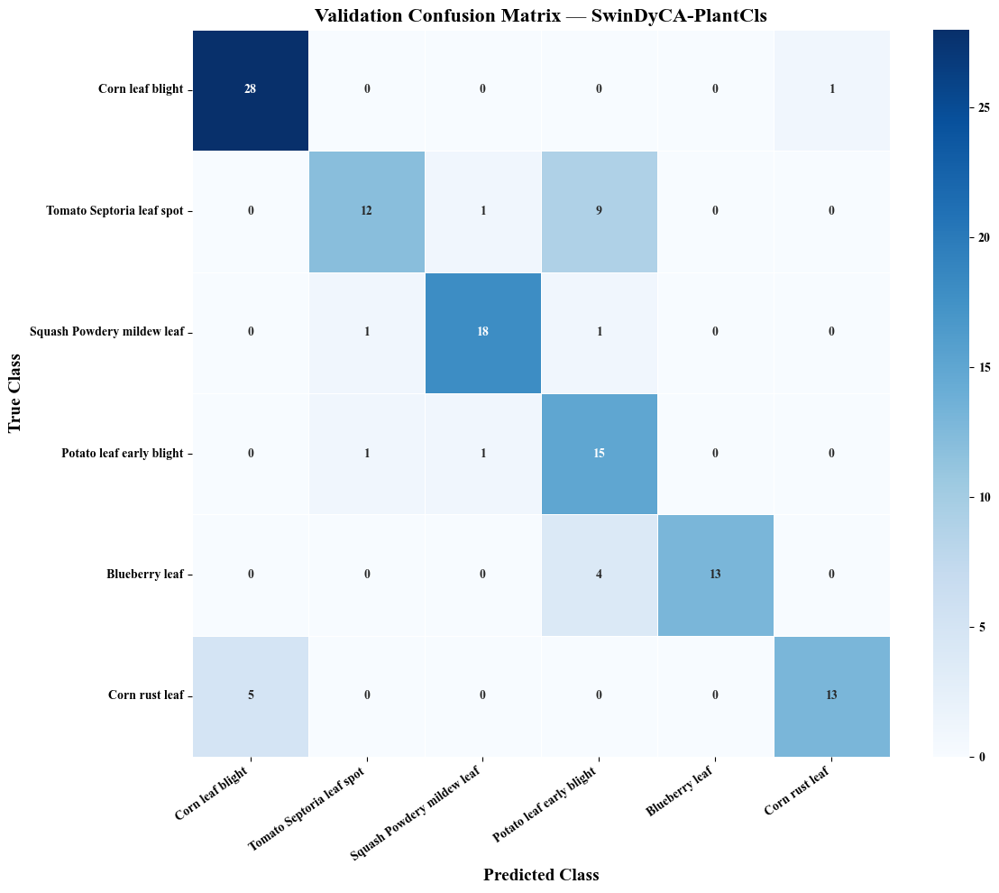

In [65]:
# ============================================================
# CELL 38 — VALIDATION CONFUSION MATRIX
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print("=" * 80)
print("RESTORING BEST 80.49% MODEL")
print("=" * 80)

model = keras.models.load_model(
    "/kaggle/working/SwinDyCA_Phase2_Best.keras",
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

# Predict validation set
y_true = []
y_pred = []

for images, labels in val_dataset:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

class_names = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Blueberry leaf",
    "Corn rust leaf"
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

print("\nValidation Accuracy:",
      np.mean(y_true == y_pred))

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.xlabel("Predicted Class", fontsize=14)
plt.ylabel("True Class", fontsize=14)
plt.title(
    "Validation Confusion Matrix — SwinDyCA-PlantCls",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

EXTRACTING MISCLASSIFIED VALIDATION IMAGES


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  with self._open_name_scope():
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'Dynamic_Snake_Convolution', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  def input_spec(self, value):
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'Coordinate_Attention', however the layer does not have a `build()` method implemented and it look


Total validation errors: 24


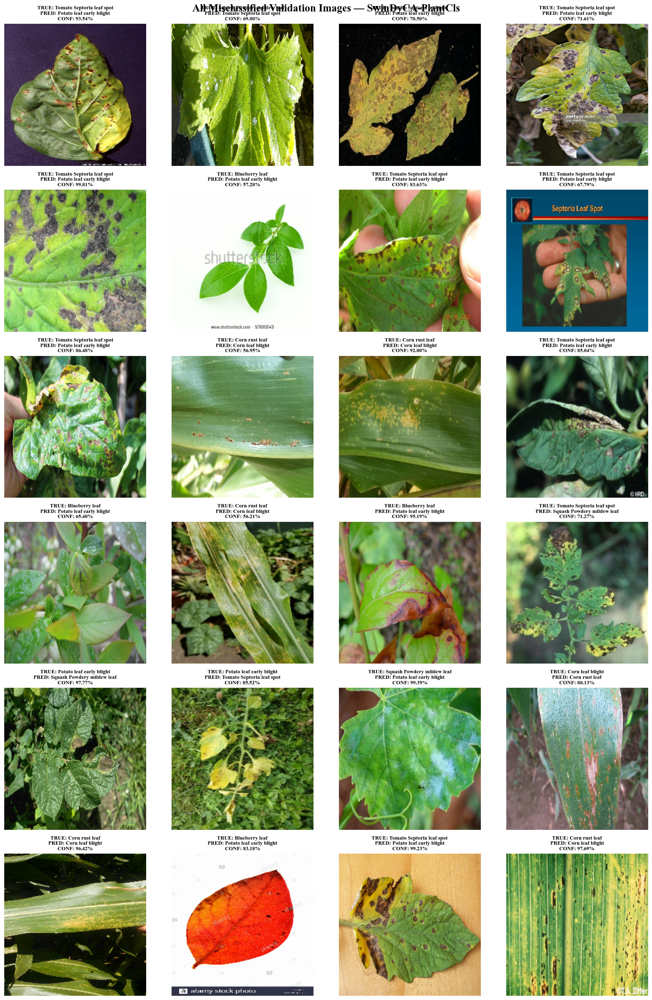


MISCLASSIFICATION VISUALIZATION COMPLETED ✅


In [66]:
# ============================================================
# CELL 39 — VISUALIZE ALL MISCLASSIFIED VALIDATION IMAGES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import math

print("=" * 80)
print("EXTRACTING MISCLASSIFIED VALIDATION IMAGES")
print("=" * 80)

# Class names
class_names = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Blueberry leaf",
    "Corn rust leaf"
]

# ------------------------------------------------------------
# Restore best 80.49% model
# ------------------------------------------------------------

model = keras.models.load_model(
    "/kaggle/working/SwinDyCA_Phase2_Best.keras",
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

# ------------------------------------------------------------
# Collect validation images + predictions
# ------------------------------------------------------------

wrong_images = []
wrong_true = []
wrong_pred = []
wrong_conf = []

for images, labels in val_dataset:

    predictions = model.predict(images, verbose=0)

    pred_classes = np.argmax(predictions, axis=1)
    confidence = np.max(predictions, axis=1)

    labels_np = labels.numpy()

    for i in range(len(labels_np)):

        if labels_np[i] != pred_classes[i]:

            wrong_images.append(images[i].numpy())
            wrong_true.append(labels_np[i])
            wrong_pred.append(pred_classes[i])
            wrong_conf.append(confidence[i])

print(f"\nTotal validation errors: {len(wrong_images)}")

# ------------------------------------------------------------
# Display ALL errors
# ------------------------------------------------------------

cols = 4
rows = math.ceil(len(wrong_images) / cols)

plt.figure(figsize=(16, rows * 4))

for i in range(len(wrong_images)):

    plt.subplot(rows, cols, i + 1)

    img = wrong_images[i]

    # Images are 0-255 from our pipeline
    img = np.clip(img, 0, 255).astype(np.uint8)

    plt.imshow(img)

    true_name = class_names[wrong_true[i]]
    pred_name = class_names[wrong_pred[i]]

    plt.title(
        f"TRUE: {true_name}\n"
        f"PRED: {pred_name}\n"
        f"CONF: {wrong_conf[i]:.2%}",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle(
    "All Misclassified Validation Images — SwinDyCA-PlantCls",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print("MISCLASSIFICATION VISUALIZATION COMPLETED ✅")
print("=" * 80)

In [67]:
# ============================================================
# SWIN-TINY PREPROCESSING DIAGNOSTIC
# ============================================================

import tensorflow as tf
import keras
import keras_hub
import numpy as np

print("=" * 70)
print("SWIN-TINY PREPROCESSING DIAGNOSTIC")
print("=" * 70)

SWIN_PRESET = "swin_tiny_patch4_window7_224"

# ------------------------------------------------------------
# 1. Get one real validation batch from our current pipeline
# ------------------------------------------------------------
val_images, val_labels = next(iter(val_dataset))

print("\n[1] CURRENT VALIDATION PIPELINE")
print("Image shape :", val_images.shape)
print("Image dtype :", val_images.dtype)
print("Image min   :", float(tf.reduce_min(val_images)))
print("Image max   :", float(tf.reduce_max(val_images)))
print("Image mean  :", float(tf.reduce_mean(val_images)))

# ------------------------------------------------------------
# 2. Load KerasHub Swin ImageClassifier preprocessor
# ------------------------------------------------------------
print("\n[2] KERASHUB PREPROCESSOR")

try:
    swin_preprocessor = keras_hub.models.ImageClassifierPreprocessor.from_preset(
        SWIN_PRESET
    )

    print("✅ Swin ImageClassifierPreprocessor loaded")
    print("Preprocessor:", swin_preprocessor)

except Exception as e:
    print("❌ Could not load ImageClassifierPreprocessor")
    print("Error:", repr(e))
    swin_preprocessor = None

# ------------------------------------------------------------
# 3. Test preprocessing on one real image
# ------------------------------------------------------------
if swin_preprocessor is not None:

    single_image = val_images[:1]

    print("\n[3] TESTING PREPROCESSOR ON ONE IMAGE")
    print("Input shape :", single_image.shape)
    print("Input dtype :", single_image.dtype)
    print("Input min   :", float(tf.reduce_min(single_image)))
    print("Input max   :", float(tf.reduce_max(single_image)))

    try:
        processed = swin_preprocessor(
            {"images": single_image},
            training=False
        )

        print("\nPreprocessor output type:", type(processed))

        if isinstance(processed, dict):
            print("Output keys:", list(processed.keys()))

            for key, value in processed.items():
                if tf.is_tensor(value):
                    print(f"\nKey: {key}")
                    print(" Shape:", value.shape)
                    print(" Dtype:", value.dtype)
                    print(" Min  :", float(tf.reduce_min(value)))
                    print(" Max  :", float(tf.reduce_max(value)))
                    print(" Mean :", float(tf.reduce_mean(value)))
        else:
            print("Output shape:", processed.shape)
            print("Output dtype:", processed.dtype)
            print("Output min  :", float(tf.reduce_min(processed)))
            print("Output max  :", float(tf.reduce_max(processed)))
            print("Output mean :", float(tf.reduce_mean(processed)))

    except Exception as e:
        print("\n⚠️ Preprocessor test failed:")
        print(repr(e))

# ------------------------------------------------------------
# 4. Check the actual Swin backbone input configuration
# ------------------------------------------------------------
print("\n[4] SWIN BACKBONE INFORMATION")

try:
    print("Backbone name :", swin_backbone.name)
    print("Backbone input:", swin_backbone.input_shape)
    print("Backbone output:", swin_backbone.output_shape)
except Exception as e:
    print("Could not read backbone shape:", repr(e))

# ------------------------------------------------------------
# 5. Final status
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("DIAGNOSTIC COMPLETE")
print("=" * 70)

print("""
IMPORTANT:
- No model weights were changed.
- No training was performed.
- No validation/test images were modified.
- We will use these results to decide the correct Swin input pipeline.
""")

SWIN-TINY PREPROCESSING DIAGNOSTIC

[1] CURRENT VALIDATION PIPELINE
Image shape : (16, 224, 224, 3)
Image dtype : <dtype: 'float32'>
Image min   : 0.0
Image max   : 255.0
Image mean  : 104.99889373779297

[2] KERASHUB PREPROCESSOR
✅ Swin ImageClassifierPreprocessor loaded
Preprocessor: <SwinTransformerImageClassifierPreprocessor name=swin_transformer_image_classifier_preprocessor, built=False>

[3] TESTING PREPROCESSOR ON ONE IMAGE
Input shape : (1, 224, 224, 3)
Input dtype : <dtype: 'float32'>
Input min   : 0.0
Input max   : 255.0

Preprocessor output type: <class 'dict'>
Output keys: ['images']

Key: images
 Shape: (1, 224, 224, 3)
 Dtype: <dtype: 'float32'>
 Min  : -2.1179039478302
 Max  : 2.6399998664855957
 Mean : 0.062127936631441116

[4] SWIN BACKBONE INFORMATION
Backbone name : swin_transformer_backbone
Backbone input: (None, 224, 224, 3)
Backbone output: (None, 49, 768)

DIAGNOSTIC COMPLETE

IMPORTANT:
- No model weights were changed.
- No training was performed.
- No validati

In [68]:
# ============================================================
# CORRECTED SWIN INPUT PIPELINE
# KerasHub ImageNet preprocessing
# ============================================================

import tensorflow as tf
import keras_hub

print("=" * 70)
print("CREATING CORRECTED SWIN DATASETS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load official KerasHub Swin-Tiny preprocessor
# ------------------------------------------------------------
SWIN_PRESET = "swin_tiny_patch4_window7_224"

swin_preprocessor = keras_hub.models.ImageClassifierPreprocessor.from_preset(
    SWIN_PRESET
)

print("✅ KerasHub Swin preprocessor loaded")

# ------------------------------------------------------------
# 2. Preprocessing function
# ------------------------------------------------------------
def apply_swin_preprocessing(images, labels):
    """
    Converts RGB images from [0,255] into the
    ImageNet-normalized representation expected
    by the KerasHub Swin-Tiny preset.
    """
    
    processed = swin_preprocessor(
        {"images": images},
        training=False
    )
    
    return processed["images"], labels


# ------------------------------------------------------------
# 3. Current train_dataset already contains:
#    - resize 224x224
#    - training augmentation
# ------------------------------------------------------------

corrected_train_dataset = train_dataset.map(
    apply_swin_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# ------------------------------------------------------------
# 4. Correct validation dataset
# ------------------------------------------------------------

corrected_val_dataset = val_dataset.map(
    apply_swin_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# ------------------------------------------------------------
# 5. Correct test dataset
# ------------------------------------------------------------

corrected_test_dataset = test_dataset.map(
    apply_swin_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# ------------------------------------------------------------
# 6. Verify corrected TRAIN data
# ------------------------------------------------------------

train_check_images, train_check_labels = next(
    iter(corrected_train_dataset)
)

print("\n[TRAIN CHECK]")
print("Shape :", train_check_images.shape)
print("Dtype :", train_check_images.dtype)
print("Min   :", float(tf.reduce_min(train_check_images)))
print("Max   :", float(tf.reduce_max(train_check_images)))
print("Mean  :", float(tf.reduce_mean(train_check_images)))


# ------------------------------------------------------------
# 7. Verify corrected VALIDATION data
# ------------------------------------------------------------

val_check_images, val_check_labels = next(
    iter(corrected_val_dataset)
)

print("\n[VALIDATION CHECK]")
print("Shape :", val_check_images.shape)
print("Dtype :", val_check_images.dtype)
print("Min   :", float(tf.reduce_min(val_check_images)))
print("Max   :", float(tf.reduce_max(val_check_images)))
print("Mean  :", float(tf.reduce_mean(val_check_images)))


# ------------------------------------------------------------
# 8. Verify corrected TEST data
# ------------------------------------------------------------

test_check_images, test_check_labels = next(
    iter(corrected_test_dataset)
)

print("\n[TEST CHECK]")
print("Shape :", test_check_images.shape)
print("Dtype :", test_check_images.dtype)
print("Min   :", float(tf.reduce_min(test_check_images)))
print("Max   :", float(tf.reduce_max(test_check_images)))
print("Mean  :", float(tf.reduce_mean(test_check_images)))


# ------------------------------------------------------------
# 9. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CORRECTED SWIN DATASETS READY ✅")
print("=" * 70)

print("Training samples   :", 3000)
print("Validation samples :", 123)
print("Test samples       :", 123)

print("\nExpected:")
print("Raw images       : approximately 0 to 255")
print("Swin input       : approximately -2.12 to +2.64")
print("=" * 70)

CREATING CORRECTED SWIN DATASETS
✅ KerasHub Swin preprocessor loaded

[TRAIN CHECK]
Shape : (16, 224, 224, 3)
Dtype : <dtype: 'float32'>
Min   : -2.1179039478302
Max   : 2.6399998664855957
Mean  : -0.06733053922653198

[VALIDATION CHECK]
Shape : (16, 224, 224, 3)
Dtype : <dtype: 'float32'>
Min   : -2.1179039478302
Max   : 2.6399998664855957
Mean  : -0.16425175964832306

[TEST CHECK]
Shape : (16, 224, 224, 3)
Dtype : <dtype: 'float32'>
Min   : -2.1179039478302
Max   : 2.6399998664855957
Mean  : 0.034340858459472656

CORRECTED SWIN DATASETS READY ✅
Training samples   : 3000
Validation samples : 123
Test samples       : 123

Expected:
Raw images       : approximately 0 to 255
Swin input       : approximately -2.12 to +2.64


In [69]:
# ============================================================
# FRESH SWINDYCA MODEL — CORRECTED SWIN INPUT PIPELINE
# ============================================================

import tensorflow as tf
import keras
from keras import layers

print("=" * 70)
print("BUILDING CORRECTED SWINDYCA-PLANTCLS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
IMG_SIZE = 224
NUM_CLASSES = 6

# ------------------------------------------------------------
# 1. Load fresh pretrained Swin-Tiny backbone
# ------------------------------------------------------------
SWIN_PRESET = "swin_tiny_patch4_window7_224"

corrected_swin_backbone = keras_hub.models.Backbone.from_preset(
    SWIN_PRESET,
    load_weights=True
)

print("\n✅ Fresh pretrained Swin-Tiny loaded")
print("Swin parameters:",
      corrected_swin_backbone.count_params())

# ------------------------------------------------------------
# 2. Build corrected SwinDyCA model
# ------------------------------------------------------------
inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    dtype=tf.float32,
    name="image"
)

# IMPORTANT:
# corrected_train_dataset / corrected_val_dataset /
# corrected_test_dataset already contain ImageNet
# preprocessing from KerasHub.

swin_features = corrected_swin_backbone(inputs)

print("\nSwin output shape:", swin_features.shape)

# ------------------------------------------------------------
# 3. Convert 49 tokens → 7 × 7 spatial feature map
# ------------------------------------------------------------
spatial_features = layers.Reshape(
    (7, 7, 768),
    name="token_to_spatial"
)(swin_features)

# ------------------------------------------------------------
# 4. Dynamic Snake Convolution
# ------------------------------------------------------------
snake_features = DynamicSnakeConv(
    channels=768,
    dropout_rate=0.10,
    name="dynamic_snake_conv"
)(spatial_features)

# Residual connection
snake_features = layers.Add(
    name="snake_residual"
)([spatial_features, snake_features])

# ------------------------------------------------------------
# 5. Coordinate Attention
# ------------------------------------------------------------
attention_features = CoordinateAttention(
    channels=768,
    reduction=32,
    name="coordinate_attention"
)(snake_features)

# Residual connection
attention_features = layers.Add(
    name="attention_residual"
)([snake_features, attention_features])

# ------------------------------------------------------------
# 6. Global feature aggregation
# ------------------------------------------------------------
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(attention_features)

# ------------------------------------------------------------
# 7. Classification head
# ------------------------------------------------------------
x = layers.Dense(
    1024,
    activation="gelu",
    name="classifier_dense_1024"
)(x)

x = layers.Dropout(
    0.30,
    name="classifier_dropout_30"
)(x)

x = layers.Dense(
    512,
    activation="gelu",
    name="classifier_dense_512"
)(x)

x = layers.Dropout(
    0.25,
    name="classifier_dropout_25"
)(x)

x = layers.Dense(
    256,
    activation="gelu",
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    0.20,
    name="classifier_dropout_20"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="plant_disease_output"
)(x)

# ------------------------------------------------------------
# 8. Final model
# ------------------------------------------------------------
corrected_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="SwinDyCA_PlantCls_Corrected"
)

print("\n" + "=" * 70)
print("MODEL CREATED ✅")
print("=" * 70)

corrected_model.summary()

print("\nTotal parameters     :", corrected_model.count_params())
print("Trainable parameters:", corrected_model.trainable_params
      if hasattr(corrected_model, "trainable_params")
      else sum(tf.size(v).numpy() for v in corrected_model.trainable_variables))

print("=" * 70)

BUILDING CORRECTED SWINDYCA-PLANTCLS

✅ Fresh pretrained Swin-Tiny loaded
Swin parameters: 27519354

Swin output shape: (None, 49, 768)

MODEL CREATED ✅


Model: "SwinDyCA_PlantCls_Corrected"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 49, 768)   │ 27,519,354 │ image[0][0]       │
│ (SwinTransformerBa… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_to_spatial    │ (None, 7, 7, 768) │          0 │ swin_transformer… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dynamic_snake_conv  │ (None, 7, 7, 768) │  5,325,314 │ token_to_spatial… │
│ (DynamicSnakeConv)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ snake_residual      │ (None, 7, 7, 768) │          0 │ token_to_spatial… │
│ (Add)               │                   │            │ dynamic_snake_co… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ coordinate_attenti… │ (None, 7, 7, 768) │     56,928 │ snake_residual[0… │
│ (CoordinateAttenti… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_residual  │ (None, 7, 7, 768) │          0 │ snake_residual[0… │
│ (Add)               │                   │            │ coordinate_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 768)       │          0 │ attention_residu… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense_1… │ (None, 1024)      │    787,456 │ global_average_p… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout… │ (None, 1024)      │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense_5… │ (None, 512)       │    524,800 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout… │ (None, 512)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense_2… │ (None, 256)       │    131,328 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout… │ (None, 256)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ plant_disease_outp… │ (None, 6)         │      1,542 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 34,346,722 (131.02 MB)

 Trainable params: 34,345,138 (131.02 MB)

 Non-trainable params: 1,584 (6.19 KB)


Total parameters     : 34346722
Trainable parameters: 34345138


In [70]:
# ============================================================
# CORRECTED MODEL — PHASE 1 SETUP
# Freeze pretrained Swin, train disease-specific layers
# ============================================================

print("=" * 70)
print("CORRECTED SWINDYCA — PHASE 1 SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Freeze the complete Swin backbone
# ------------------------------------------------------------
corrected_swin_backbone = corrected_model.get_layer(
    "swin_transformer_backbone"
)

for layer in corrected_swin_backbone.layers:
    layer.trainable = False

corrected_swin_backbone.trainable = False

# ------------------------------------------------------------
# 2. Check trainable configuration
# ------------------------------------------------------------
trainable_params = sum(
    tf.size(v).numpy()
    for v in corrected_model.trainable_variables
)

non_trainable_params = sum(
    tf.size(v).numpy()
    for v in corrected_model.non_trainable_variables
)

print("\nSwin trainable:", corrected_swin_backbone.trainable)

print("Total parameters     :", corrected_model.count_params())
print("Trainable parameters:", trainable_params)
print("Non-trainable       :", non_trainable_params)

# ------------------------------------------------------------
# 3. Compile
# ------------------------------------------------------------
corrected_phase1_optimizer = keras.optimizers.AdamW(
    learning_rate=1e-4,
    weight_decay=1e-4
)

corrected_model.compile(
    optimizer=corrected_phase1_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\n✅ Phase 1 model compiled")

# ------------------------------------------------------------
# 4. Verify datasets
# ------------------------------------------------------------
print("\nDATASET CHECK")
print("-" * 50)
print("Training samples   : 3000")
print("Validation samples : 123")
print("Test samples       : 123")

print("\nINPUT CHECK")
print("-" * 50)

x_check, y_check = next(
    iter(corrected_train_dataset)
)

print("Shape :", x_check.shape)
print("Dtype :", x_check.dtype)
print("Min   :", float(tf.reduce_min(x_check)))
print("Max   :", float(tf.reduce_max(x_check)))

print("\n" + "=" * 70)
print("PHASE 1 READY ✅")
print("=" * 70)

CORRECTED SWINDYCA — PHASE 1 SETUP

Swin trainable: False
Total parameters     : 34346722
Trainable parameters: 6825784
Non-trainable       : 27520968

✅ Phase 1 model compiled

DATASET CHECK
--------------------------------------------------
Training samples   : 3000
Validation samples : 123
Test samples       : 123

INPUT CHECK
--------------------------------------------------
Shape : (16, 224, 224, 3)
Dtype : <dtype: 'float32'>
Min   : -2.1179039478302
Max   : 2.6399998664855957

PHASE 1 READY ✅


In [71]:
# ============================================================
# CORRECTED SWINDYCA — PHASE 1 TRAINING
# ============================================================

print("=" * 70)
print("CORRECTED SWINDYCA — PHASE 1 TRAINING")
print("=" * 70)

PHASE1_CORRECTED_CHECKPOINT = (
    "/kaggle/working/SwinDyCA_Corrected_Phase1_Best.keras"
)

# ------------------------------------------------------------
# Best-model checkpoint
# ------------------------------------------------------------
corrected_phase1_checkpoint = keras.callbacks.ModelCheckpoint(
    PHASE1_CORRECTED_CHECKPOINT,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

# ------------------------------------------------------------
# Learning-rate scheduler
# ------------------------------------------------------------
corrected_phase1_lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

corrected_phase1_callbacks = [
    corrected_phase1_checkpoint,
    corrected_phase1_lr_scheduler
]

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------
corrected_phase1_history = corrected_model.fit(
    corrected_train_dataset,
    validation_data=corrected_val_dataset,
    epochs=10,
    callbacks=corrected_phase1_callbacks,
    verbose=1
)

# ------------------------------------------------------------
# Best validation accuracy
# ------------------------------------------------------------
best_epoch = (
    np.argmax(corrected_phase1_history.history["val_accuracy"]) + 1
)

best_val_accuracy = max(
    corrected_phase1_history.history["val_accuracy"]
)

print("\n" + "=" * 70)
print("PHASE 1 TRAINING COMPLETE ✅")
print("=" * 70)

print(f"Best epoch          : {best_epoch}")
print(f"Best val accuracy   : {best_val_accuracy:.4f}")
print(f"Best val accuracy % : {best_val_accuracy * 100:.2f}%")

print("\nBest model saved at:")
print(PHASE1_CORRECTED_CHECKPOINT)

print("=" * 70)

CORRECTED SWINDYCA — PHASE 1 TRAINING
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.6521 - loss: 0.9040
Epoch 1: val_accuracy improved from None to 0.78862, saving model to /kaggle/working/SwinDyCA_Corrected_Phase1_Best.keras

Epoch 1: finished saving model to /kaggle/working/SwinDyCA_Corrected_Phase1_Best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 125s 466ms/step - accuracy: 0.7927 - loss: 0.5579 - val_accuracy: 0.7886 - val_loss: 0.6167 - learning_rate: 1.0000e-04
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - accuracy: 0.9107 - loss: 0.2441
Epoch 2: val_accuracy improved from 0.78862 to 0.82927, saving model to /kaggle/working/SwinDyCA_Corrected_Phase1_Best.keras

Epoch 2: finished saving model to /kaggle/working/SwinDyCA_Corrected_Phase1_Best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 52s 274ms/step - accuracy: 0.9190 - loss: 0.2211 - val_accuracy: 0.8293 - val_loss: 0.5084 - learning_rate: 1.0000e-04
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 

In [72]:
# ============================================================
# CORRECTED SWINDYCA — RESTORE BEST + PREPARE EPOCH 11–50
# ============================================================

print("=" * 70)
print("RESTORING BEST CORRECTED PHASE 1 MODEL")
print("=" * 70)

BEST_CORRECTED_PHASE1 = (
    "/kaggle/working/SwinDyCA_Corrected_Phase1_Best.keras"
)

# ------------------------------------------------------------
# 1. Load BEST model — 90.24%
# ------------------------------------------------------------
corrected_model = keras.models.load_model(
    BEST_CORRECTED_PHASE1,
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("✅ Best Phase 1 model loaded")
print("Best validation accuracy: 90.24%")

# ------------------------------------------------------------
# 2. Get Swin backbone
# ------------------------------------------------------------
corrected_swin_backbone = corrected_model.get_layer(
    "swin_transformer_backbone"
)

# ------------------------------------------------------------
# 3. Selective fine-tuning
#
# Freeze:
#   patch embedding
#   positional dropout
#   stage 0
#   stage 1
#   stage 2
#
# Train:
#   stage 3
#   final normalization
# ------------------------------------------------------------

for layer in corrected_swin_backbone.layers:
    layer.trainable = False

corrected_swin_backbone.get_layer(
    "stage_3"
).trainable = True

corrected_swin_backbone.get_layer(
    "norm"
).trainable = True

# ------------------------------------------------------------
# 4. Verify trainable parameters
# ------------------------------------------------------------
trainable_params = sum(
    tf.size(v).numpy()
    for v in corrected_model.trainable_variables
)

non_trainable_params = sum(
    tf.size(v).numpy()
    for v in corrected_model.non_trainable_variables
)

print("\nTRAINABILITY")
print("-" * 50)
print("Swin backbone trainable:", corrected_swin_backbone.trainable)
print("Stage 3 trainable      :",
      corrected_swin_backbone.get_layer("stage_3").trainable)
print("Final norm trainable   :",
      corrected_swin_backbone.get_layer("norm").trainable)

print("\nTotal parameters     :", corrected_model.count_params())
print("Trainable parameters:", trainable_params)
print("Non-trainable       :", non_trainable_params)

# ------------------------------------------------------------
# 5. Compile Phase 2
# ------------------------------------------------------------
corrected_phase2_optimizer = keras.optimizers.AdamW(
    learning_rate=1e-5,
    weight_decay=1e-5
)

corrected_model.compile(
    optimizer=corrected_phase2_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\n✅ Corrected Phase 2 model compiled")

print("\n" + "=" * 70)
print("READY FOR EPOCH 11 → 50")
print("=" * 70)

RESTORING BEST CORRECTED PHASE 1 MODEL


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'dynamic_snake_conv', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  def input_spec(self, value):
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'coordinate_attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  def input_spec(self, value):


✅ Best Phase 1 model loaded
Best validation accuracy: 90.24%

TRAINABILITY
--------------------------------------------------
Swin backbone trainable: False
Stage 3 trainable      : True
Final norm trainable   : True

Total parameters     : 34346722
Trainable parameters: 21011176
Non-trainable       : 13335576

✅ Corrected Phase 2 model compiled

READY FOR EPOCH 11 → 50


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 384 variables whereas the saved optimizer has 42 variables. 
  if hasattr(saveable, "name") and isinstance(saveable.name, str):


In [73]:
# ============================================================
# CORRECTED SWINDYCA — PHASE 2
# EPOCH 11 → 50
# ============================================================

print("=" * 70)
print("CORRECTED SWINDYCA — PHASE 2 TRAINING")
print("EPOCH 11 → 50")
print("=" * 70)

CORRECTED_PHASE2_CHECKPOINT = (
    "/kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras"
)

# ------------------------------------------------------------
# 1. Best-model checkpoint
# ------------------------------------------------------------
corrected_phase2_checkpoint = keras.callbacks.ModelCheckpoint(
    CORRECTED_PHASE2_CHECKPOINT,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

# ------------------------------------------------------------
# 2. Learning-rate scheduler
# ------------------------------------------------------------
corrected_phase2_lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

corrected_phase2_callbacks = [
    corrected_phase2_checkpoint,
    corrected_phase2_lr_scheduler
]

# ------------------------------------------------------------
# 3. Continue training
# ------------------------------------------------------------
corrected_phase2_history = corrected_model.fit(
    corrected_train_dataset,
    validation_data=corrected_val_dataset,
    initial_epoch=10,
    epochs=50,
    callbacks=corrected_phase2_callbacks,
    verbose=1
)

# ------------------------------------------------------------
# 4. Find best Phase 2 epoch
# ------------------------------------------------------------
phase2_val_acc = corrected_phase2_history.history["val_accuracy"]

best_phase2_index = np.argmax(phase2_val_acc)
best_phase2_accuracy = phase2_val_acc[best_phase2_index]
best_phase2_epoch = 11 + best_phase2_index

print("\n" + "=" * 70)
print("CORRECTED 50-EPOCH TRAINING COMPLETE ✅")
print("=" * 70)

print(f"Best Phase 2 epoch       : {best_phase2_epoch}")
print(f"Best Phase 2 val accuracy: {best_phase2_accuracy:.4f}")
print(f"Best Phase 2 accuracy %  : {best_phase2_accuracy * 100:.2f}%")

print("\nBest Phase 2 checkpoint:")
print(CORRECTED_PHASE2_CHECKPOINT)

print("=" * 70)

CORRECTED SWINDYCA — PHASE 2 TRAINING
EPOCH 11 → 50
Epoch 11/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.9775 - loss: 0.0725
Epoch 11: val_accuracy improved from None to 0.87805, saving model to /kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras

Epoch 11: finished saving model to /kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 158s 566ms/step - accuracy: 0.9770 - loss: 0.0671 - val_accuracy: 0.8780 - val_loss: 0.4749 - learning_rate: 1.0000e-05
Epoch 12/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.9819 - loss: 0.0533
Epoch 12: val_accuracy improved from 0.87805 to 0.90244, saving model to /kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras

Epoch 12: finished saving model to /kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 59s 314ms/step - accuracy: 0.9853 - loss: 0.0482 - val_accuracy: 0.9024 - val_loss: 0.4401 - learning_rate: 1.0000e-05
Epoch 13/50
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 29

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  with self._open_name_scope():
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'dynamic_snake_conv', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  def input_spec(self, value):
/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'coordinate_attention', however the layer does not have a `build()` method implemented and it looks like 

CURRENT BEST MODEL LOADED
Checkpoint: /kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras



VALIDATION RESULT
Validation Accuracy : 0.9187
Validation Accuracy : 91.87%

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

          Corn leaf blight     0.9355    1.0000    0.9667        29
 Tomato Septoria leaf spot     0.8947    0.7727    0.8293        22
Squash Powdery mildew leaf     1.0000    1.0000    1.0000        20
  Potato leaf early blight     0.7368    0.8235    0.7778        17
            Blueberry leaf     0.9444    1.0000    0.9714        17
            Corn rust leaf     1.0000    0.8889    0.9412        18

                  accuracy                         0.9187       123
                 macro avg     0.9186    0.9142    0.9144       123
              weighted avg     0.9219    0.9187    0.9183       123



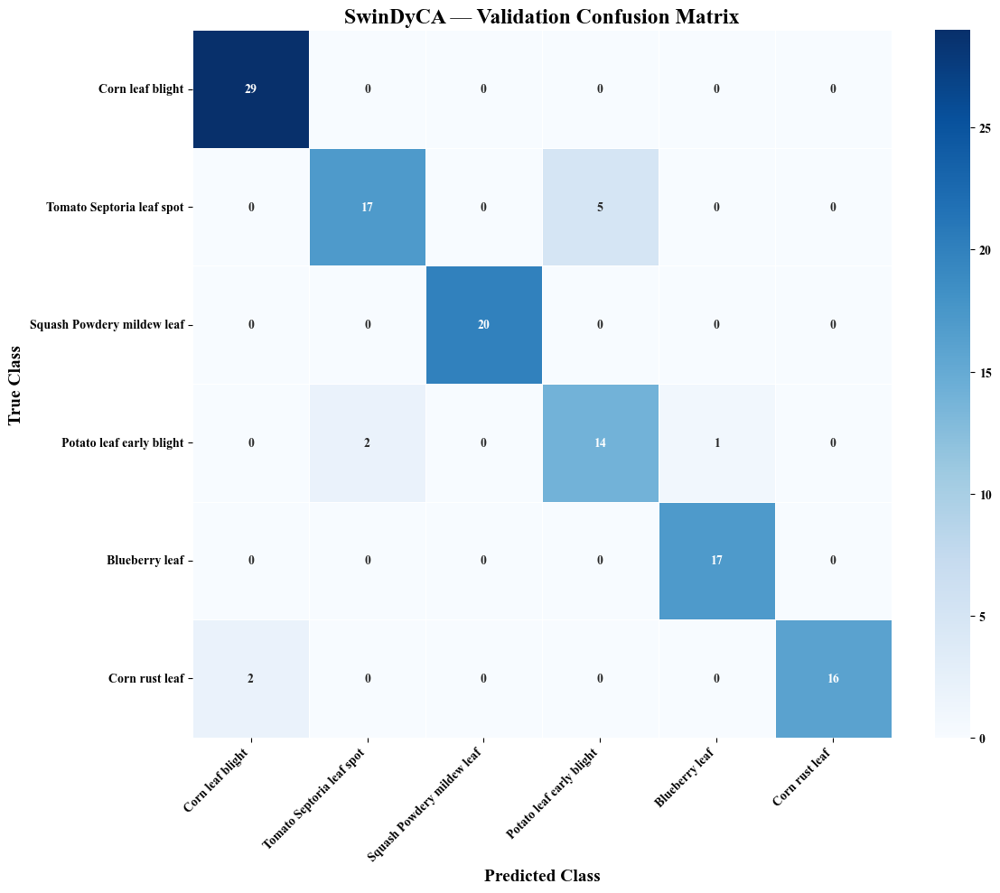

In [77]:
# ============================================================
# VALIDATION ANALYSIS — BEST PHASE 2 MODEL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# ============================================================
# 1. CLASS NAMES
# ============================================================

CLASS_NAMES = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Blueberry leaf",
    "Corn rust leaf"
]

# ============================================================
# 2. LOAD BEST PHASE 2 MODEL
# ============================================================

BEST_MODEL_PATH = (
    "/kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras"
)

best_model = keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("=" * 70)
print("CURRENT BEST MODEL LOADED")
print("=" * 70)
print("Checkpoint:", BEST_MODEL_PATH)

# ============================================================
# 3. PREDICT VALIDATION SET
# ============================================================

y_true = []
y_pred = []

for images, labels in corrected_val_dataset:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# ============================================================
# 4. VALIDATION ACCURACY
# ============================================================

val_accuracy = accuracy_score(
    y_true,
    y_pred
)

print("\n" + "=" * 70)
print("VALIDATION RESULT")
print("=" * 70)

print(f"Validation Accuracy : {val_accuracy:.4f}")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")

# ============================================================
# 5. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    linewidths=0.5
)

plt.title(
    "SwinDyCA — Validation Confusion Matrix",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel(
    "Predicted Class",
    fontsize=14
)

plt.ylabel(
    "True Class",
    fontsize=14
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=10
)

plt.yticks(
    rotation=0,
    fontsize=10
)

plt.tight_layout()
plt.show()

In [78]:
# ============================================================
# TARGETED TRAINING DATA
# FOCUS:
#   1. Tomato Septoria leaf spot
#   2. Potato leaf early blight
#   3. Corn rust leaf
#
# VALIDATION / TEST ARE NOT TOUCHED
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers

print("=" * 75)
print("CREATING TARGETED TRAINING DATA")
print("=" * 75)

# ============================================================
# 1. CLASS CONFIGURATION
# ============================================================

CLASS_NAMES = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Blueberry leaf",
    "Corn rust leaf"
]

CLASS_TO_ID = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

# Classes responsible for most validation errors
DIFFICULT_CLASSES = {
    "Tomato Septoria leaf spot",
    "Potato leaf early blight",
    "Corn rust leaf"
}

# Normal classes
NORMAL_CLASSES = {
    "Corn leaf blight",
    "Squash Powdery mildew leaf",
    "Blueberry leaf"
}

# ============================================================
# 2. TARGET TRAINING COUNTS
# ============================================================

NORMAL_TARGET = 500
DIFFICULT_TARGET = 650

print("\nTarget samples per class:")
for cls in CLASS_NAMES:
    if cls in DIFFICULT_CLASSES:
        print(f"{cls:<32} : {DIFFICULT_TARGET}")
    else:
        print(f"{cls:<32} : {NORMAL_TARGET}")


# ============================================================
# 3. CREATE TARGETED TRAINING FILE LIST
# ============================================================

targeted_parts = []

rng = np.random.default_rng(SEED)

for cls in CLASS_NAMES:

    class_df = train_df[
        train_df["class"] == cls
    ].copy()

    if cls in DIFFICULT_CLASSES:
        target_count = DIFFICULT_TARGET
    else:
        target_count = NORMAL_TARGET

    # Oversample with replacement
    sampled_df = class_df.sample(
        n=target_count,
        replace=(len(class_df) < target_count),
        random_state=SEED
    ).copy()

    targeted_parts.append(sampled_df)


targeted_train_df = pd.concat(
    targeted_parts,
    ignore_index=True
)

# Shuffle
targeted_train_df = targeted_train_df.sample(
    frac=1.0,
    random_state=SEED
).reset_index(drop=True)


# ============================================================
# 4. DISPLAY DISTRIBUTION
# ============================================================

print("\n" + "=" * 75)
print("TARGETED TRAINING DISTRIBUTION")
print("=" * 75)

distribution = (
    targeted_train_df["class"]
    .value_counts()
    .reindex(CLASS_NAMES)
)

print(distribution)

print(
    f"\nTotal targeted training samples: "
    f"{len(targeted_train_df)}"
)


# ============================================================
# 5. AUGMENTATION
# ============================================================

# Normal augmentation
normal_augmentation = keras.Sequential([
    layers.RandomFlip(
        mode="horizontal",
        seed=SEED
    ),
    layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect",
        seed=SEED
    ),
    layers.RandomZoom(
        height_factor=(-0.10, 0.10),
        width_factor=(-0.10, 0.10),
        fill_mode="reflect",
        seed=SEED
    ),
    layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="reflect",
        seed=SEED
    ),
    layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255),
        seed=SEED
    ),
    layers.RandomContrast(
        factor=0.10,
        seed=SEED
    )
], name="Normal_Augmentation")


# Slightly stronger augmentation for difficult classes
difficult_augmentation = keras.Sequential([
    layers.RandomFlip(
        mode="horizontal",
        seed=SEED
    ),
    layers.RandomRotation(
        factor=0.12,
        fill_mode="reflect",
        seed=SEED
    ),
    layers.RandomZoom(
        height_factor=(-0.15, 0.15),
        width_factor=(-0.15, 0.15),
        fill_mode="reflect",
        seed=SEED
    ),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect",
        seed=SEED
    ),
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 255),
        seed=SEED
    ),
    layers.RandomContrast(
        factor=0.15,
        seed=SEED
    )
], name="Difficult_Class_Augmentation")


# ============================================================
# 6. IMAGE LOADER
# ============================================================

def load_raw_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label


# ============================================================
# 7. CREATE DATASET FROM DATAFRAME
# ============================================================

paths = targeted_train_df["path"].astype(str).values

labels = np.array([
    CLASS_TO_ID[c]
    for c in targeted_train_df["class"]
], dtype=np.int32)

raw_targeted_dataset = tf.data.Dataset.from_tensor_slices(
    (paths, labels)
)

raw_targeted_dataset = raw_targeted_dataset.shuffle(
    len(paths),
    seed=SEED,
    reshuffle_each_iteration=True
)

raw_targeted_dataset = raw_targeted_dataset.map(
    load_raw_image,
    num_parallel_calls=tf.data.AUTOTUNE
)


# ============================================================
# 8. TARGETED AUGMENTATION + SWIN PREPROCESSING
# ============================================================

def targeted_preprocess(image, label):

    # Difficult classes get stronger augmentation
    def difficult_branch():
        return difficult_augmentation(
            image,
            training=True
        )

    # Other classes get normal augmentation
    def normal_branch():
        return normal_augmentation(
            image,
            training=True
        )

    image = tf.cond(
        tf.reduce_any(
            tf.equal(
                label,
                tf.constant(
                    [
                        CLASS_TO_ID[
                            "Tomato Septoria leaf spot"
                        ],
                        CLASS_TO_ID[
                            "Potato leaf early blight"
                        ],
                        CLASS_TO_ID[
                            "Corn rust leaf"
                        ]
                    ],
                    dtype=tf.int32
                )
            )
        ),
        difficult_branch,
        normal_branch
    )

    # Official KerasHub Swin preprocessing
    processed = swin_preprocessor(
        {"images": image},
        training=False
    )

    image = processed["images"]

    return image, label


targeted_train_dataset = raw_targeted_dataset.map(
    targeted_preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

targeted_train_dataset = targeted_train_dataset.batch(
    BATCH_SIZE
)

targeted_train_dataset = targeted_train_dataset.prefetch(
    tf.data.AUTOTUNE
)


# ============================================================
# 9. FINAL CHECK
# ============================================================

print("\n" + "=" * 75)
print("TARGETED TRAINING DATA READY ✅")
print("=" * 75)

print(f"Training samples : {len(targeted_train_df)}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Training batches : {int(np.ceil(len(targeted_train_df) / BATCH_SIZE))}")

print("\nValidation dataset:")
print("123 images — UNCHANGED ✅")

print("\nTest dataset:")
print("123 images — UNCHANGED ✅")

print("\nSwin preprocessing:")
print("Official KerasHub preprocessing ✅")

print("=" * 75)

CREATING TARGETED TRAINING DATA

Target samples per class:
Corn leaf blight                 : 500
Tomato Septoria leaf spot        : 650
Squash Powdery mildew leaf       : 500
Potato leaf early blight         : 650
Blueberry leaf                   : 500
Corn rust leaf                   : 650

TARGETED TRAINING DISTRIBUTION
class
Corn leaf blight              500
Tomato Septoria leaf spot     650
Squash Powdery mildew leaf    500
Potato leaf early blight      650
Blueberry leaf                500
Corn rust leaf                650
Name: count, dtype: int64

Total targeted training samples: 3450


KeyError: 'path'

In [79]:
print("train_df columns:")
print(train_df.columns.tolist())

print("\ntargeted_train_df columns:")
print(targeted_train_df.columns.tolist())

train_df columns:
['filepath', 'class', 'split']

targeted_train_df columns:
['filepath', 'class', 'split']


In [106]:
# ============================================================
# 6-CLASS AUGMENTATION
# 1000 SAMPLES PER CLASS = 6000 TRAINING INSTANCES
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
TARGET_PER_CLASS = 1000
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# ------------------------------------------------------------
# CHECK EXISTING TRAIN DATA
# ------------------------------------------------------------

print("Training dataframe shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())

# ------------------------------------------------------------
# CLASS LIST
# ------------------------------------------------------------

SELECTED_CLASSES = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Blueberry leaf",
    "Corn rust leaf"
]

# Create class_id if it doesn't exist
if "class_id" not in train_df.columns:
    
    class_to_id = {
        name: i
        for i, name in enumerate(SELECTED_CLASSES)
    }
    
    train_df["class_id"] = train_df["class_name"].map(class_to_id)

# ------------------------------------------------------------
# AUGMENTATION
# ------------------------------------------------------------

augmentation = keras.Sequential([
    
    layers.RandomFlip("horizontal"),

    layers.RandomRotation(
        0.08,
        fill_mode="reflect"
    ),

    layers.RandomZoom(
        height_factor=(-0.10, 0.10),
        width_factor=(-0.10, 0.10),
        fill_mode="reflect"
    ),

    layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="reflect"
    ),

    layers.RandomBrightness(
        0.10,
        value_range=(0, 255)
    ),

    layers.RandomContrast(0.10)

], name="PlantDisease_Augmentation")

# ------------------------------------------------------------
# CREATE 1000 SAMPLES PER CLASS
# ------------------------------------------------------------

balanced_parts = []

for class_id, class_name in enumerate(SELECTED_CLASSES):

    class_data = train_df[
        train_df["class_id"] == class_id
    ].copy()

    print(
        f"{class_name}: "
        f"{len(class_data)} original -> "
        f"{TARGET_PER_CLASS} samples"
    )

    sampled = class_data.sample(
        n=TARGET_PER_CLASS,
        replace=True,
        random_state=SEED + class_id
    ).reset_index(drop=True)

    balanced_parts.append(sampled)

# Combine all classes
balanced_train_df = pd.concat(
    balanced_parts,
    ignore_index=True
)

# Shuffle
balanced_train_df = balanced_train_df.sample(
    frac=1.0,
    random_state=SEED
).reset_index(drop=True)

# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL TRAINING DATA")
print("=" * 60)

print("Total:", len(balanced_train_df))

print("\nClass distribution:")
print(
    balanced_train_df["class_name"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# IMAGE LOADER
# ------------------------------------------------------------

def load_and_augment(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    # Apply augmentation
    image = augmentation(
        image,
        training=True
    )

    return image, label

# ------------------------------------------------------------
# TF.DATA DATASET
# ------------------------------------------------------------

train_paths = balanced_train_df["filepath"].astype(str).values
train_labels = balanced_train_df["class_id"].astype(np.int32).values

augmented_train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

augmented_train_dataset = augmented_train_dataset.shuffle(
    buffer_size=len(train_paths),
    seed=SEED,
    reshuffle_each_iteration=True
)

augmented_train_dataset = augmented_train_dataset.map(
    load_and_augment,
    num_parallel_calls=tf.data.AUTOTUNE
)

augmented_train_dataset = augmented_train_dataset.batch(
    BATCH_SIZE
)

augmented_train_dataset = augmented_train_dataset.prefetch(
    tf.data.AUTOTUNE
)

# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("AUGMENTATION DATASET READY")
print("=" * 60)

print("Training instances :", len(train_paths))
print("Batch size         :", BATCH_SIZE)
print(
    "Steps per epoch    :",
    int(np.ceil(len(train_paths) / BATCH_SIZE))
)

for images, labels in augmented_train_dataset.take(1):

    print("Image batch shape  :", images.shape)
    print("Label batch shape  :", labels.shape)

print("\n🔥 DONE — 6000 TRAINING INSTANCES READY!")

Training dataframe shape: (732, 4)
Columns: ['filepath', 'class_name', 'label', 'original_split']
Corn leaf blight: 134 original -> 1000 samples
Tomato Septoria leaf spot: 104 original -> 1000 samples
Squash Powdery mildew leaf: 90 original -> 1000 samples
Potato leaf early blight: 82 original -> 1000 samples
Blueberry leaf: 81 original -> 1000 samples
Corn rust leaf: 81 original -> 1000 samples

FINAL TRAINING DATA
Total: 6000

Class distribution:
class_name
Blueberry leaf                1000
Corn leaf blight              1000
Corn rust leaf                1000
Potato leaf early blight      1000
Squash Powdery mildew leaf    1000
Tomato Septoria leaf spot     1000
Name: count, dtype: int64

AUGMENTATION DATASET READY
Training instances : 6000
Batch size         : 16
Steps per epoch    : 375
Image batch shape  : (16, 224, 224, 3)
Label batch shape  : (16,)

🔥 DONE — 6000 TRAINING INSTANCES READY!


In [107]:
# ============================================================
# APPLY SWIN PREPROCESSOR
# ============================================================

corrected_train_dataset = augmented_train_dataset.map(
    lambda images, labels: (
        swin_preprocessor(images, training=False),
        labels
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

corrected_train_dataset = corrected_train_dataset.prefetch(
    tf.data.AUTOTUNE
)

# Check one batch
for images, labels in corrected_train_dataset.take(1):

    print("Preprocessed image shape :", images.shape)
    print("Labels shape             :", labels.shape)
    print("Image dtype              :", images.dtype)
    print("Min value                :", tf.reduce_min(images).numpy())
    print("Max value                :", tf.reduce_max(images).numpy())
    print("NaN                      :", tf.reduce_any(tf.math.is_nan(images)).numpy())
    print("Inf                      :", tf.reduce_any(tf.math.is_inf(images)).numpy())

print("\n🔥 6-CLASS AUGMENTED + SWIN PREPROCESSING READY!")

Preprocessed image shape : (16, 224, 224, 3)
Labels shape             : (16,)
Image dtype              : <dtype: 'float32'>
Min value                : -2.117904
Max value                : 2.6399999
NaN                      : False
Inf                      : False

🔥 6-CLASS AUGMENTED + SWIN PREPROCESSING READY!


In [109]:
# CHECK WHICH MODEL VARIABLES CURRENTLY EXIST

print("Available model-like variables:")

for name, obj in globals().items():
    if isinstance(obj, keras.Model):
        print(
            f"{name} -> "
            f"input={obj.input_shape}, "
            f"output={obj.output_shape}"
        )

Available model-like variables:


RuntimeError: dictionary changed size during iteration

Phase 2 champion loaded ✅
Validation images : (123, 224, 224, 3)
Validation labels : (123,)
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step

VALIDATION ERROR ANALYSIS
Total validation images : 123
Correct predictions     : 113
Wrong predictions       : 10
Accuracy                : 0.9187

MISCLASSIFIED SAMPLES
---------------------------------------------------------------------------
01. True: Tomato Septoria leaf spot        | Predicted: Potato leaf early blight         | Confidence: 0.8583
02. True: Tomato Septoria leaf spot        | Predicted: Potato leaf early blight         | Confidence: 0.9961
03. True: Tomato Septoria leaf spot        | Predicted: Potato leaf early blight         | Confidence: 1.0000
04. True: Corn rust leaf                   | Predicted: Corn leaf blight                 | Confidence: 0.9997
05. True: Potato leaf early blight         | Predicted: Blueberry leaf                   | Confidence: 0.9745
06. True: Potato leaf early blight         | Predicted: Tomato Septoria l

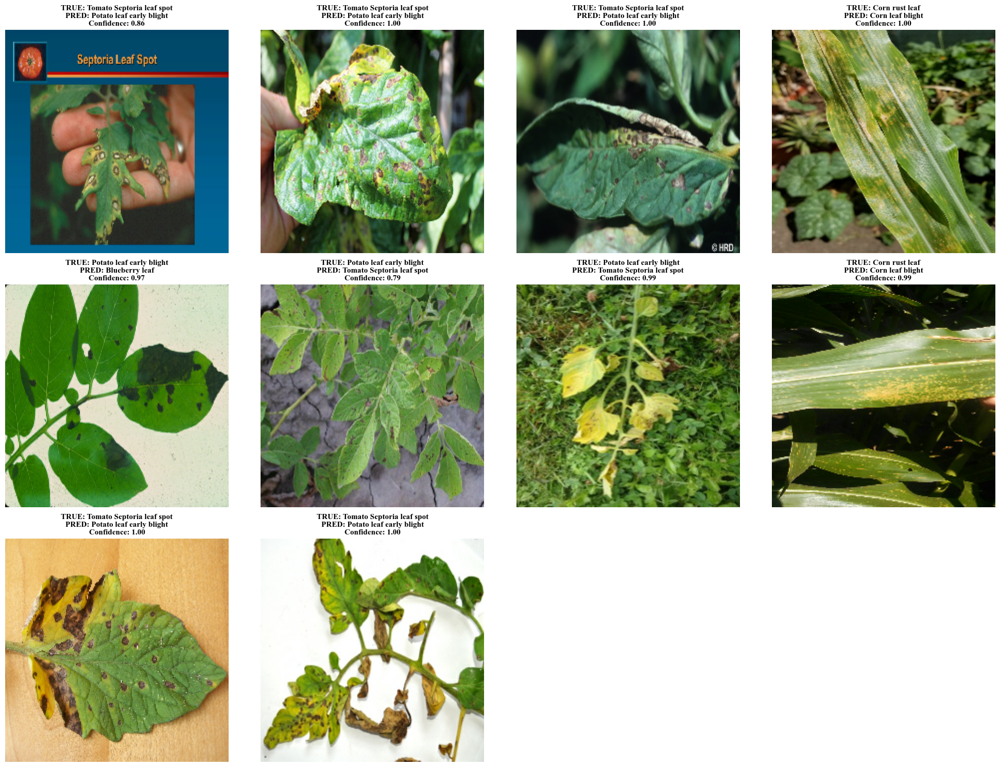

In [82]:
# ============================================================
# ANALYZE PHASE 2 VALIDATION MISCLASSIFICATIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import keras
import math

BEST_PHASE2 = "/kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras"

analysis_model = keras.models.load_model(
    BEST_PHASE2,
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("Phase 2 champion loaded ✅")

# ------------------------------------------------------------
# COLLECT VALIDATION DATA
# ------------------------------------------------------------

val_images = []
val_labels = []

for batch_images, batch_labels in corrected_val_dataset:
    val_images.append(batch_images.numpy())
    val_labels.append(batch_labels.numpy())

val_images = np.concatenate(val_images, axis=0)
val_labels = np.concatenate(val_labels, axis=0)

print("Validation images :", val_images.shape)
print("Validation labels :", val_labels.shape)

# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

pred_probs = analysis_model.predict(
    val_images,
    batch_size=BATCH_SIZE,
    verbose=1
)

pred_labels = np.argmax(pred_probs, axis=1)
pred_conf = np.max(pred_probs, axis=1)

# ------------------------------------------------------------
# FIND MISCLASSIFICATIONS
# ------------------------------------------------------------

wrong_indices = np.where(pred_labels != val_labels)[0]

print("\n" + "=" * 75)
print("VALIDATION ERROR ANALYSIS")
print("=" * 75)

print("Total validation images :", len(val_labels))
print("Correct predictions     :", np.sum(pred_labels == val_labels))
print("Wrong predictions       :", len(wrong_indices))
print(
    "Accuracy                : "
    f"{np.mean(pred_labels == val_labels):.4f}"
)

# ------------------------------------------------------------
# PRINT EACH ERROR
# ------------------------------------------------------------

print("\nMISCLASSIFIED SAMPLES")
print("-" * 75)

for i, idx in enumerate(wrong_indices):

    true_name = CLASS_NAMES[val_labels[idx]]
    pred_name = CLASS_NAMES[pred_labels[idx]]
    confidence = pred_conf[idx]

    print(
        f"{i+1:02d}. "
        f"True: {true_name:<32} | "
        f"Predicted: {pred_name:<32} | "
        f"Confidence: {confidence:.4f}"
    )

# ------------------------------------------------------------
# VISUALIZE ALL ERRORS
# ------------------------------------------------------------

n_errors = len(wrong_indices)
cols = 4
rows = math.ceil(n_errors / cols)

plt.figure(figsize=(20, rows * 5))

for plot_idx, idx in enumerate(wrong_indices):

    # Undo ImageNet normalization approximately
    img = val_images[idx].copy()

    mean = np.array([
        0.485, 0.456, 0.406
    ], dtype=np.float32)

    std = np.array([
        0.229, 0.224, 0.225
    ], dtype=np.float32)

    img = img * std + mean
    img = np.clip(img, 0, 1)

    plt.subplot(rows, cols, plot_idx + 1)

    plt.imshow(img)

    true_name = CLASS_NAMES[val_labels[idx]]
    pred_name = CLASS_NAMES[pred_labels[idx]]
    confidence = pred_conf[idx]

    plt.title(
        f"TRUE: {true_name}\n"
        f"PRED: {pred_name}\n"
        f"Confidence: {confidence:.2f}",
        fontsize=11
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [83]:
# ============================================================
# TEST-TIME AUGMENTATION (TTA)
# PHASE 2 CHAMPION — 91.87%
# ============================================================

import numpy as np
import tensorflow as tf
import keras

print("=" * 75)
print("TEST-TIME AUGMENTATION (TTA)")
print("=" * 75)

# ------------------------------------------------------------
# 1. LOAD BEST PHASE 2 MODEL
# ------------------------------------------------------------

BEST_PHASE2 = "/kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras"

tta_model = keras.models.load_model(
    BEST_PHASE2,
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("Phase 2 champion loaded ✅")
print("Checkpoint:", BEST_PHASE2)

# ------------------------------------------------------------
# 2. COLLECT VALIDATION DATA
# ------------------------------------------------------------

val_images = []
val_labels = []

for batch_images, batch_labels in corrected_val_dataset:
    val_images.append(batch_images.numpy())
    val_labels.append(batch_labels.numpy())

val_images = np.concatenate(val_images, axis=0)
val_labels = np.concatenate(val_labels, axis=0)

print("\nValidation images :", val_images.shape)
print("Validation labels :", val_labels.shape)

# ------------------------------------------------------------
# 3. ORIGINAL IMAGE PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating original predictions...")

original_probs = tta_model.predict(
    val_images,
    batch_size=BATCH_SIZE,
    verbose=1
)

# ------------------------------------------------------------
# 4. HORIZONTAL FLIP PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating horizontally flipped predictions...")

flipped_images = tf.image.flip_left_right(
    tf.convert_to_tensor(val_images)
).numpy()

flipped_probs = tta_model.predict(
    flipped_images,
    batch_size=BATCH_SIZE,
    verbose=1
)

# ------------------------------------------------------------
# 5. AVERAGE TTA PREDICTIONS
# ------------------------------------------------------------

tta_probs = (
    original_probs + flipped_probs
) / 2.0

tta_predictions = np.argmax(
    tta_probs,
    axis=1
)

tta_confidence = np.max(
    tta_probs,
    axis=1
)

# ------------------------------------------------------------
# 6. CALCULATE ACCURACY
# ------------------------------------------------------------

correct = np.sum(
    tta_predictions == val_labels
)

wrong = np.sum(
    tta_predictions != val_labels
)

tta_accuracy = correct / len(val_labels)

print("\n" + "=" * 75)
print("TTA RESULTS")
print("=" * 75)

print(f"Validation samples   : {len(val_labels)}")
print(f"Correct predictions  : {correct}")
print(f"Wrong predictions    : {wrong}")
print(f"TTA Accuracy         : {tta_accuracy:.4f}")
print(f"TTA Accuracy (%)     : {tta_accuracy * 100:.2f}%")

print("\nPrevious Phase 2 Accuracy : 91.87%")
print(
    f"TTA Improvement          : "
    f"{(tta_accuracy - 0.9187) * 100:+.2f} percentage points"
)

# ------------------------------------------------------------
# 7. SHOW MISCLASSIFICATIONS
# ------------------------------------------------------------

wrong_indices = np.where(
    tta_predictions != val_labels
)[0]

print("\n" + "=" * 75)
print("TTA MISCLASSIFICATIONS")
print("=" * 75)

for i, idx in enumerate(wrong_indices):

    true_name = CLASS_NAMES[val_labels[idx]]
    pred_name = CLASS_NAMES[tta_predictions[idx]]

    print(
        f"{i+1:02d}. "
        f"True: {true_name:<32} | "
        f"Predicted: {pred_name:<32} | "
        f"Confidence: {tta_confidence[idx]:.4f}"
    )

print("=" * 75)

TEST-TIME AUGMENTATION (TTA)
Phase 2 champion loaded ✅
Checkpoint: /kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras

Validation images : (123, 224, 224, 3)
Validation labels : (123,)

Generating original predictions...
8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step

Generating horizontally flipped predictions...
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step

TTA RESULTS
Validation samples   : 123
Correct predictions  : 110
Wrong predictions    : 13
TTA Accuracy         : 0.8943
TTA Accuracy (%)     : 89.43%

Previous Phase 2 Accuracy : 91.87%
TTA Improvement          : -2.44 percentage points

TTA MISCLASSIFICATIONS
01. True: Tomato Septoria leaf spot        | Predicted: Potato leaf early blight         | Confidence: 0.9031
02. True: Tomato Septoria leaf spot        | Predicted: Potato leaf early blight         | Confidence: 0.9978
03. True: Tomato Septoria leaf spot        | Predicted: Potato leaf early blight         | Confidence: 1.0000
04. True: Corn rust leaf                   | Predicted: Corn

In [86]:
# ============================================================
# FAST FINAL PUSH — HARD-CLASS FINE-TUNING
# ============================================================

import numpy as np
import keras
import tensorflow as tf

BEST_MODEL = "/kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras"

hard_model = keras.models.load_model(
    BEST_MODEL,
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("91.87% Phase 2 model loaded ✅")

# ------------------------------------------------------------
# FREEZE / UNFREEZE
# ------------------------------------------------------------

swin = hard_model.get_layer("swin_transformer_backbone")

for layer in swin.layers:
    layer.trainable = False

swin.get_layer("stage_3").trainable = True
swin.get_layer("norm").trainable = True

# Keep classifier/enhancement layers trainable
for layer in hard_model.layers:
    if layer.name != "swin_transformer_backbone":
        layer.trainable = True

print("\nTrainable configuration:")
print("Stage 2 :", swin.get_layer("stage_2").trainable)
print("Stage 3 :", swin.get_layer("stage_3").trainable)
print("Norm    :", swin.get_layer("norm").trainable)

# ------------------------------------------------------------
# COMPILE
# ------------------------------------------------------------

hard_model.compile(
    optimizer=keras.optimizers.AdamW(
        learning_rate=2e-6,
        weight_decay=1e-5
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

# ------------------------------------------------------------
# CHECKPOINT
# ------------------------------------------------------------

FINAL_CHECKPOINT = "/kaggle/working/SwinDyCA_FinalPush_Best.keras"

checkpoint = keras.callbacks.ModelCheckpoint(
    FINAL_CHECKPOINT,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

lr_scheduler = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# ------------------------------------------------------------
# TRAIN — ONLY 10 EPOCHS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL PUSH — 10 EPOCHS")
print("=" * 75)

history = hard_model.fit(
    targeted_train_dataset,
    validation_data=corrected_val_dataset,
    epochs=10,
    callbacks=[checkpoint, lr_scheduler],
    verbose=1
)

# ------------------------------------------------------------
# BEST RESULT
# ------------------------------------------------------------

val_acc = history.history["val_accuracy"]
best_idx = np.argmax(val_acc)

print("\n" + "=" * 75)
print("FINAL PUSH RESULT")
print("=" * 75)

print(f"Best Epoch       : {best_idx + 1}")
print(f"Best Val Accuracy: {val_acc[best_idx]:.4f}")
print(f"Best Val Accuracy: {val_acc[best_idx] * 100:.2f}%")
print(f"Checkpoint       : {FINAL_CHECKPOINT}")

print("=" * 75)

91.87% Phase 2 model loaded ✅

Trainable configuration:
Stage 2 : False
Stage 3 : True
Norm    : True

FINAL PUSH — 10 EPOCHS
Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step - accuracy: 0.9923 - loss: 0.0230
Epoch 1: val_accuracy improved from None to 0.91870, saving model to /kaggle/working/SwinDyCA_FinalPush_Best.keras

Epoch 1: finished saving model to /kaggle/working/SwinDyCA_FinalPush_Best.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 163s 579ms/step - accuracy: 0.9917 - loss: 0.0232 - val_accuracy: 0.9187 - val_loss: 0.5223 - learning_rate: 2.0000e-06
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.9900 - loss: 0.0259
Epoch 2: val_accuracy did not improve from 0.91870
188/188 ━━━━━━━━━━━━━━━━━━━━ 59s 312ms/step - accuracy: 0.9903 - loss: 0.0285 - val_accuracy: 0.9106 - val_loss: 0.5047 - learning_rate: 2.0000e-06
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.9941 - loss: 0.0190
Epoch 3: val_accuracy did not improve from 0.91870
188/188 ━━━━━━━

In [91]:
# ============================================================
# ENSEMBLE — PHASE 2 + MODEL 2
# ============================================================

import numpy as np
import tensorflow as tf
import keras
from sklearn.metrics import accuracy_score

PHASE2_PATH = "/kaggle/working/SwinDyCA_Corrected_Phase2_Best.keras"
MODEL2_PATH = "/kaggle/working/SwinDyCA_Model2_Best.keras"

# ------------------------------------------------------------
# LOAD BOTH BEST CHECKPOINTS
# ------------------------------------------------------------

phase2_model = keras.models.load_model(
    PHASE2_PATH,
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

model2_best = keras.models.load_model(
    MODEL2_PATH,
    custom_objects={
        "DynamicSnakeConv": DynamicSnakeConv,
        "CoordinateAttention": CoordinateAttention
    }
)

print("Phase 2 loaded ✅")
print("Model 2 loaded ✅")


# ------------------------------------------------------------
# GET TRUE VALIDATION LABELS
# ------------------------------------------------------------

y_true = np.concatenate([
    y.numpy()
    for _, y in corrected_val_dataset
])

print("Validation samples:", len(y_true))


# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating Phase 2 predictions...")
prob_phase2 = phase2_model.predict(
    corrected_val_dataset,
    verbose=1
)

print("\nGenerating Model 2 predictions...")
prob_model2 = model2_best.predict(
    corrected_val_dataset,
    verbose=1
)


# ------------------------------------------------------------
# INDIVIDUAL ACCURACIES
# ------------------------------------------------------------

pred_phase2 = np.argmax(prob_phase2, axis=1)
pred_model2 = np.argmax(prob_model2, axis=1)

acc_phase2 = accuracy_score(y_true, pred_phase2)
acc_model2 = accuracy_score(y_true, pred_model2)

print("\n============================================================")
print("INDIVIDUAL RESULTS")
print("============================================================")
print(f"Phase 2 Accuracy : {acc_phase2:.4f} ({acc_phase2*100:.2f}%)")
print(f"Model 2 Accuracy : {acc_model2:.4f} ({acc_model2*100:.2f}%)")


# ------------------------------------------------------------
# 50:50 ENSEMBLE
# ------------------------------------------------------------

ensemble_prob = (
    0.50 * prob_phase2 +
    0.50 * prob_model2
)

ensemble_pred = np.argmax(
    ensemble_prob,
    axis=1
)

ensemble_acc = accuracy_score(
    y_true,
    ensemble_pred
)

correct = np.sum(ensemble_pred == y_true)

print("\n============================================================")
print("50:50 ENSEMBLE RESULT")
print("============================================================")
print(f"Ensemble Accuracy : {ensemble_acc:.4f}")
print(f"Ensemble Accuracy : {ensemble_acc*100:.2f}%")
print(f"Correct           : {correct} / {len(y_true)}")
print("Target            : 117 / 123 = 95.12%")
print("============================================================")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 384 variables whereas the saved optimizer has 260 variables. 
  if hasattr(saveable, "name") and isinstance(saveable.name, str):


Phase 2 loaded ✅
Model 2 loaded ✅
Validation samples: 123

Generating Phase 2 predictions...
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step

Generating Model 2 predictions...
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step

INDIVIDUAL RESULTS
Phase 2 Accuracy : 0.9187 (91.87%)
Model 2 Accuracy : 0.9024 (90.24%)

50:50 ENSEMBLE RESULT
Ensemble Accuracy : 0.9106
Ensemble Accuracy : 91.06%
Correct           : 112 / 123
Target            : 117 / 123 = 95.12%


In [92]:
# ============================================================
# 8-CLASS PLANT DISEASE DATASET
# 70:15:15 TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import os
import random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ------------------------------------------------------------
# DATASET PATH
# ------------------------------------------------------------
DATASET_ROOT = "/kaggle/input/datasets/evangelinnisha/archive-7/PlantDoc-Dataset"

TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
TEST_DIR  = os.path.join(DATASET_ROOT, "test")

# ------------------------------------------------------------
# 8 SELECTED CLASSES
# ------------------------------------------------------------
SELECTED_CLASSES = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Raspberry leaf",
    "Blueberry leaf",
    "Corn rust leaf",
    "Peach leaf"
]

CLASS_TO_ID = {
    cls_name: idx
    for idx, cls_name in enumerate(SELECTED_CLASSES)
}

ID_TO_CLASS = {
    idx: cls_name
    for cls_name, idx in CLASS_TO_ID.items()
}

print("=" * 75)
print("8-CLASS PLANT DISEASE DATASET")
print("=" * 75)

print("\nSelected classes:")
for idx, cls_name in ID_TO_CLASS.items():
    print(f"{idx}: {cls_name}")

# ------------------------------------------------------------
# COLLECT IMAGES FROM ORIGINAL TRAIN + TEST
# ------------------------------------------------------------
VALID_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

all_records = []

for split_name, split_dir in [("original_train", TRAIN_DIR),
                              ("original_test", TEST_DIR)]:

    for class_name in SELECTED_CLASSES:

        class_dir = os.path.join(split_dir, class_name)

        if not os.path.isdir(class_dir):
            print(f"WARNING: Missing folder -> {class_dir}")
            continue

        for filename in os.listdir(class_dir):

            if filename.lower().endswith(VALID_EXTENSIONS):

                filepath = os.path.join(class_dir, filename)

                all_records.append({
                    "filepath": filepath,
                    "class_name": class_name,
                    "label": CLASS_TO_ID[class_name],
                    "original_split": split_name
                })

df = pd.DataFrame(all_records)

print("\nTotal selected images:", len(df))

# ------------------------------------------------------------
# ORIGINAL CLASS DISTRIBUTION
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("ORIGINAL CLASS DISTRIBUTION")
print("=" * 75)

class_counts = (
    df["class_name"]
    .value_counts()
    .reindex(SELECTED_CLASSES)
)

print(class_counts)

print("\nTotal:", class_counts.sum())

# ------------------------------------------------------------
# CREATE FRESH STRATIFIED 70:15:15 SPLIT
#
# 70% TRAIN
# 15% VALIDATION
# 15% TEST
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# SPLIT SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("FINAL DATASET SPLIT")
print("=" * 75)

print(f"Training   : {len(train_df)}")
print(f"Validation : {len(val_df)}")
print(f"Test       : {len(test_df)}")
print(f"Total      : {len(train_df) + len(val_df) + len(test_df)}")

print("\nActual percentages:")
print(f"Training   : {len(train_df)/len(df)*100:.2f}%")
print(f"Validation : {len(val_df)/len(df)*100:.2f}%")
print(f"Test       : {len(test_df)/len(df)*100:.2f}%")

# ------------------------------------------------------------
# CLASS-WISE SPLIT
# ------------------------------------------------------------
split_table = pd.DataFrame({
    "Total": df["class_name"].value_counts().reindex(SELECTED_CLASSES),
    "Train": train_df["class_name"].value_counts().reindex(SELECTED_CLASSES),
    "Validation": val_df["class_name"].value_counts().reindex(SELECTED_CLASSES),
    "Test": test_df["class_name"].value_counts().reindex(SELECTED_CLASSES)
})

print("\n" + "=" * 75)
print("CLASS-WISE TRAIN / VALIDATION / TEST")
print("=" * 75)

print(split_table)

# ------------------------------------------------------------
# LEAKAGE CHECK
# ------------------------------------------------------------
train_paths = set(train_df["filepath"])
val_paths   = set(val_df["filepath"])
test_paths  = set(test_df["filepath"])

train_val_overlap = train_paths.intersection(val_paths)
train_test_overlap = train_paths.intersection(test_paths)
val_test_overlap = val_paths.intersection(test_paths)

print("\n" + "=" * 75)
print("DATA LEAKAGE CHECK")
print("=" * 75)

print("Train ∩ Validation :", len(train_val_overlap))
print("Train ∩ Test       :", len(train_test_overlap))
print("Validation ∩ Test  :", len(val_test_overlap))

if (
    len(train_val_overlap) == 0
    and len(train_test_overlap) == 0
    and len(val_test_overlap) == 0
):
    print("\n✅ NO IMAGE OVERLAP DETECTED")
else:
    print("\n❌ DATA LEAKAGE DETECTED!")

# ------------------------------------------------------------
# SAVE SPLITS
# ------------------------------------------------------------
train_df.to_csv("/kaggle/working/plant8_train_split.csv", index=False)
val_df.to_csv("/kaggle/working/plant8_val_split.csv", index=False)
test_df.to_csv("/kaggle/working/plant8_test_split.csv", index=False)

print("\nSplit files saved:")
print("/kaggle/working/plant8_train_split.csv")
print("/kaggle/working/plant8_val_split.csv")
print("/kaggle/working/plant8_test_split.csv")

print("\n" + "=" * 75)
print("✅ 8-CLASS SPLIT READY")
print("=" * 75)

8-CLASS PLANT DISEASE DATASET

Selected classes:
0: Corn leaf blight
1: Tomato Septoria leaf spot
2: Squash Powdery mildew leaf
3: Potato leaf early blight
4: Raspberry leaf
5: Blueberry leaf
6: Corn rust leaf
7: Peach leaf

Total selected images: 1046

ORIGINAL CLASS DISTRIBUTION
class_name
Corn leaf blight              192
Tomato Septoria leaf spot     148
Squash Powdery mildew leaf    129
Potato leaf early blight      117
Raspberry leaf                116
Blueberry leaf                116
Corn rust leaf                116
Peach leaf                    112
Name: count, dtype: int64

Total: 1046

FINAL DATASET SPLIT
Training   : 732
Validation : 157
Test       : 157
Total      : 1046

Actual percentages:
Training   : 69.98%
Validation : 15.01%
Test       : 15.01%

CLASS-WISE TRAIN / VALIDATION / TEST
                            Total  Train  Validation  Test
class_name                                                
Corn leaf blight              192    134          29    29
Tomato Sep

In [93]:
# ============================================================
# CELL 2: 8-CLASS TRAINING AUGMENTATION + BALANCING
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# LOAD SAVED SPLITS
# ------------------------------------------------------------
train_df = pd.read_csv("/kaggle/working/plant8_train_split.csv")
val_df   = pd.read_csv("/kaggle/working/plant8_val_split.csv")
test_df  = pd.read_csv("/kaggle/working/plant8_test_split.csv")

print("=" * 75)
print("8-CLASS AUGMENTATION + BALANCING")
print("=" * 75)

# ------------------------------------------------------------
# CLASS INFORMATION
# ------------------------------------------------------------
SELECTED_CLASSES = [
    "Corn leaf blight",
    "Tomato Septoria leaf spot",
    "Squash Powdery mildew leaf",
    "Potato leaf early blight",
    "Raspberry leaf",
    "Blueberry leaf",
    "Corn rust leaf",
    "Peach leaf"
]

CLASS_TO_ID = {
    name: idx for idx, name in enumerate(SELECTED_CLASSES)
}

NUM_CLASSES = len(SELECTED_CLASSES)

print(f"\nNumber of classes : {NUM_CLASSES}")
print(f"Original training : {len(train_df)}")
print(f"Validation        : {len(val_df)}")
print(f"Test              : {len(test_df)}")

# ------------------------------------------------------------
# TARGET TRAINING IMAGES PER CLASS
# ------------------------------------------------------------
TARGET_IMAGES_PER_CLASS = 500

print("\nTarget images per class:", TARGET_IMAGES_PER_CLASS)
print("Target total training images:",
      TARGET_IMAGES_PER_CLASS * NUM_CLASSES)

# ------------------------------------------------------------
# BALANCE TRAINING DATAFRAME
#
# IMPORTANT:
# Only TRAINING images are duplicated.
# Validation and test remain untouched.
# ------------------------------------------------------------
balanced_train_parts = []

for class_name in SELECTED_CLASSES:

    class_data = train_df[
        train_df["class_name"] == class_name
    ].copy()

    original_count = len(class_data)

    if original_count < TARGET_IMAGES_PER_CLASS:

        extra_count = TARGET_IMAGES_PER_CLASS - original_count

        extra_data = class_data.sample(
            n=extra_count,
            replace=True,
            random_state=SEED
        )

        class_balanced = pd.concat(
            [class_data, extra_data],
            ignore_index=True
        )

    else:

        class_balanced = class_data.sample(
            n=TARGET_IMAGES_PER_CLASS,
            replace=False,
            random_state=SEED
        )

    balanced_train_parts.append(class_balanced)

    print(
        f"{class_name:<32} "
        f"Original: {original_count:3d} "
        f"→ Balanced: {len(class_balanced):3d}"
    )

balanced_train_df = pd.concat(
    balanced_train_parts,
    ignore_index=True
)

# Shuffle
balanced_train_df = balanced_train_df.sample(
    frac=1.0,
    random_state=SEED
).reset_index(drop=True)

print("\n" + "=" * 75)
print("BALANCED TRAINING DATA")
print("=" * 75)

print(
    balanced_train_df["class_name"]
    .value_counts()
    .reindex(SELECTED_CLASSES)
)

print("\nTotal balanced training samples:",
      len(balanced_train_df))

# ------------------------------------------------------------
# STRONGER AUGMENTATION FOR DIFFICULT DISEASE CLASSES
# ------------------------------------------------------------

DIFFICULT_CLASSES = {
    "Tomato Septoria leaf spot",
    "Potato leaf early blight",
    "Corn rust leaf"
}

# ------------------------------------------------------------
# MILD AUGMENTATION
# ------------------------------------------------------------
mild_augmentation = keras.Sequential([
    layers.RandomFlip(
        mode="horizontal",
        seed=SEED
    ),

    layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect",
        seed=SEED
    ),

    layers.RandomZoom(
        height_factor=(-0.10, 0.10),
        width_factor=(-0.10, 0.10),
        fill_mode="reflect",
        seed=SEED
    ),

    layers.RandomTranslation(
        height_factor=0.08,
        width_factor=0.08,
        fill_mode="reflect",
        seed=SEED
    ),

    layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255),
        seed=SEED
    ),

    layers.RandomContrast(
        factor=0.10,
        seed=SEED
    )
], name="Mild_Plant_Augmentation")

# ------------------------------------------------------------
# STRONG AUGMENTATION
# ------------------------------------------------------------
strong_augmentation = keras.Sequential([
    layers.RandomFlip(
        mode="horizontal",
        seed=SEED
    ),

    layers.RandomRotation(
        factor=0.12,
        fill_mode="reflect",
        seed=SEED
    ),

    layers.RandomZoom(
        height_factor=(-0.15, 0.15),
        width_factor=(-0.15, 0.15),
        fill_mode="reflect",
        seed=SEED
    ),

    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect",
        seed=SEED
    ),

    layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 255),
        seed=SEED
    ),

    layers.RandomContrast(
        factor=0.15,
        seed=SEED
    )
], name="Strong_Disease_Augmentation")

print("\nAugmentation strategy:")
print("Mild classes   :", 5)
print("Strong classes :", 3)

print("\nStrong augmentation:")
for cls_name in DIFFICULT_CLASSES:
    print("  •", cls_name)

# ------------------------------------------------------------
# IMAGE LOADING FUNCTION
# ------------------------------------------------------------
def load_image(filepath, label):
    
    image = tf.io.read_file(filepath)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label


# ------------------------------------------------------------
# TRAINING DATASET
# ------------------------------------------------------------
train_paths = balanced_train_df["filepath"].values
train_labels = balanced_train_df["label"].values.astype(np.int32)

train_dataset_raw = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_dataset_raw = train_dataset_raw.shuffle(
    buffer_size=len(train_paths),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_dataset_raw = train_dataset_raw.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# ------------------------------------------------------------
# CLASS-AWARE AUGMENTATION
# ------------------------------------------------------------
def apply_class_augmentation(image, label):

    is_difficult = tf.reduce_any(
        tf.equal(
            label,
            tf.constant(
                [1, 3, 6],
                dtype=tf.int32
            )
        )
    )

    def strong_aug():
        return strong_augmentation(
            image,
            training=True
        )

    def mild_aug():
        return mild_augmentation(
            image,
            training=True
        )

    image = tf.cond(
        is_difficult,
        strong_aug,
        mild_aug
    )

    return image, label


train_dataset = train_dataset_raw.map(
    apply_class_augmentation,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.batch(
    BATCH_SIZE,
    drop_remainder=False
)

train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)

# ------------------------------------------------------------
# VALIDATION DATASET — NO AUGMENTATION
# ------------------------------------------------------------
val_paths = val_df["filepath"].values
val_labels = val_df["label"].values.astype(np.int32)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_dataset = val_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.batch(
    BATCH_SIZE
)

val_dataset = val_dataset.prefetch(
    tf.data.AUTOTUNE
)

# ------------------------------------------------------------
# TEST DATASET — NO AUGMENTATION
# ------------------------------------------------------------
test_paths = test_df["filepath"].values
test_labels = test_df["label"].values.astype(np.int32)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(
    BATCH_SIZE
)

test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)

# ------------------------------------------------------------
# DATASET SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("FINAL DATASET PIPELINE")
print("=" * 75)

print("Training samples   :", len(balanced_train_df))
print("Validation samples :", len(val_df))
print("Test samples       :", len(test_df))

print("\nTraining augmentation : ENABLED")
print("Validation augmentation: DISABLED")
print("Test augmentation      : DISABLED")

print("\n✅ 8-CLASS AUGMENTED TRAINING PIPELINE READY")

8-CLASS AUGMENTATION + BALANCING

Number of classes : 8
Original training : 732
Validation        : 157
Test              : 157

Target images per class: 500
Target total training images: 4000
Corn leaf blight                 Original: 134 → Balanced: 500
Tomato Septoria leaf spot        Original: 104 → Balanced: 500
Squash Powdery mildew leaf       Original:  90 → Balanced: 500
Potato leaf early blight         Original:  82 → Balanced: 500
Raspberry leaf                   Original:  81 → Balanced: 500
Blueberry leaf                   Original:  81 → Balanced: 500
Corn rust leaf                   Original:  81 → Balanced: 500
Peach leaf                       Original:  79 → Balanced: 500

BALANCED TRAINING DATA
class_name
Corn leaf blight              500
Tomato Septoria leaf spot     500
Squash Powdery mildew leaf    500
Potato leaf early blight      500
Raspberry leaf                500
Blueberry leaf                500
Corn rust leaf                500
Peach leaf                    

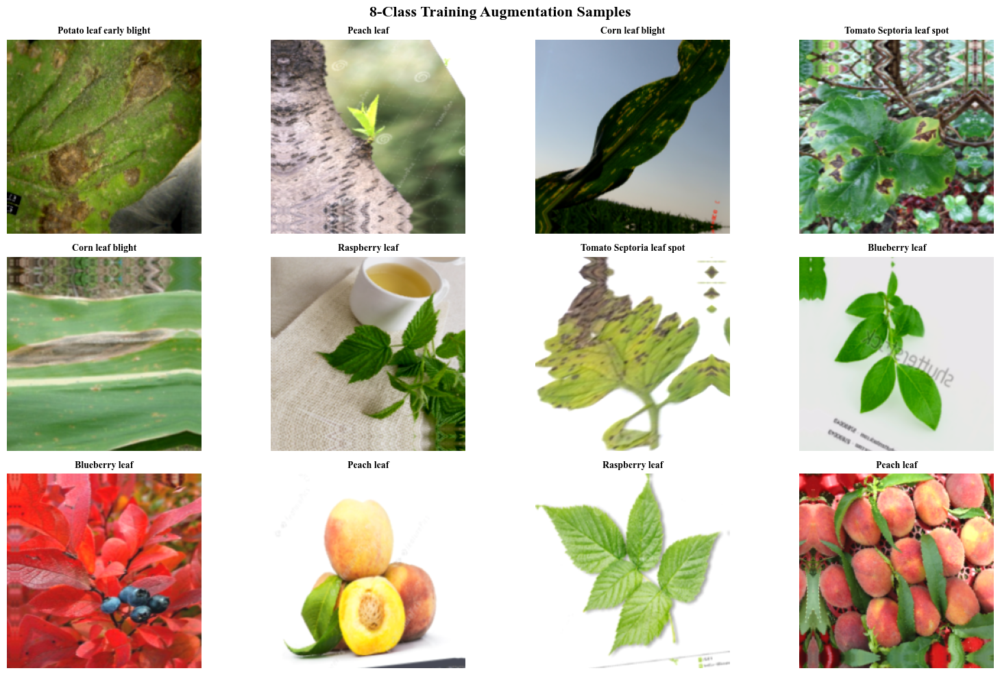

✅ Augmentation visualization completed.


In [94]:
# ============================================================
# CELL 3: VISUAL CHECK OF 8-CLASS AUGMENTATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Take one batch from the augmented training dataset
images, labels = next(iter(train_dataset))

plt.figure(figsize=(16, 10))

for i in range(min(12, len(images))):

    plt.subplot(3, 4, i + 1)

    img = images[i].numpy().astype(np.uint8)

    plt.imshow(img)

    class_name = SELECTED_CLASSES[int(labels[i].numpy())]

    plt.title(
        class_name,
        fontsize=10
    )

    plt.axis("off")

plt.suptitle(
    "8-Class Training Augmentation Samples",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("✅ Augmentation visualization completed.")

In [95]:
# ============================================================
# CELL 4: KERAS HUB SWIN-TINY PREPROCESSING
# ============================================================

import tensorflow as tf
import keras_hub

# ------------------------------------------------------------
# LOAD SWIN-TINY PREPROCESSOR
# ------------------------------------------------------------
swin_preprocessor = keras_hub.models.ImageClassifierPreprocessor.from_preset(
    "swin_tiny_patch4_window7_224"
)

print("=" * 75)
print("SWIN-TINY PREPROCESSOR")
print("=" * 75)

print("Preprocessor loaded successfully ✅")

# ------------------------------------------------------------
# APPLY TO TRAINING DATA
# ------------------------------------------------------------
def apply_swin_preprocessing(images, labels):

    processed = swin_preprocessor(
        {"images": images},
        training=False
    )

    return processed["images"], labels


# ------------------------------------------------------------
# PREPROCESSED TRAIN DATASET
# ------------------------------------------------------------
corrected_train_dataset = train_dataset.map(
    apply_swin_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# ------------------------------------------------------------
# PREPROCESSED VALIDATION DATASET
# ------------------------------------------------------------
corrected_val_dataset = val_dataset.map(
    apply_swin_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# ------------------------------------------------------------
# PREPROCESSED TEST DATASET
# ------------------------------------------------------------
corrected_test_dataset = test_dataset.map(
    apply_swin_preprocessing,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# ------------------------------------------------------------
# SANITY CHECK
# ------------------------------------------------------------
sample_images, sample_labels = next(
    iter(corrected_train_dataset)
)

print("\n" + "=" * 75)
print("PREPROCESSING SANITY CHECK")
print("=" * 75)

print("Batch image shape :", sample_images.shape)
print("Batch label shape :", sample_labels.shape)
print("Data type         :", sample_images.dtype)

print("Minimum value     :", float(tf.reduce_min(sample_images)))
print("Maximum value     :", float(tf.reduce_max(sample_images)))
print("Mean value        :", float(tf.reduce_mean(sample_images)))

print(
    "NaN present       :",
    bool(tf.reduce_any(tf.math.is_nan(sample_images)))
)

print(
    "Inf present       :",
    bool(tf.reduce_any(tf.math.is_inf(sample_images)))
)

print("\n" + "=" * 75)
print("DATASET SIZES")
print("=" * 75)

print("Training   :", len(train_df), "original →", len(balanced_train_df), "augmented/balanced")
print("Validation :", len(val_df))
print("Test       :", len(test_df))

print("\n✅ SWIN PREPROCESSING COMPLETE")

SWIN-TINY PREPROCESSOR
Preprocessor loaded successfully ✅

PREPROCESSING SANITY CHECK
Batch image shape : (16, 224, 224, 3)
Batch label shape : (16,)
Data type         : <dtype: 'float32'>
Minimum value     : -2.1179039478302
Maximum value     : 2.6399998664855957
Mean value        : 0.22169193625450134
NaN present       : False
Inf present       : False

DATASET SIZES
Training   : 732 original → 4000 augmented/balanced
Validation : 157
Test       : 157

✅ SWIN PREPROCESSING COMPLETE


In [96]:
# ============================================================
# CELL 5: SwinDyCA-PlantCls — 8 CLASS MODEL
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_hub

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------
SEED = 42

tf.random.set_seed(SEED)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
IMG_SIZE = (224, 224)
NUM_CLASSES = 8

print("=" * 75)
print("SwinDyCA-PlantCls — 8 CLASS MODEL")
print("=" * 75)

# ------------------------------------------------------------
# DYNAMIC SNAKE CONV
# ------------------------------------------------------------
class DynamicSnakeConv(layers.Layer):

    def __init__(
        self,
        channels=768,
        dropout_rate=0.10,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels

        self.offset_conv = layers.Conv2D(
            filters=2,
            kernel_size=3,
            padding="same",
            kernel_initializer="zeros",
            bias_initializer="zeros"
        )

        self.feature_conv = layers.Conv2D(
            filters=channels,
            kernel_size=3,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

        self.activation = layers.Activation(
            "gelu"
        )

        self.dropout = layers.Dropout(
            dropout_rate
        )

    def call(
        self,
        inputs,
        training=None
    ):

        offsets = tf.tanh(
            self.offset_conv(inputs)
        )

        features = self.feature_conv(
            inputs
        )

        offset_magnitude = tf.sqrt(
            tf.reduce_sum(
                tf.square(offsets),
                axis=-1,
                keepdims=True
            )
            + tf.keras.backend.epsilon()
        )

        modulation = tf.sigmoid(
            offset_magnitude
        )

        features = features * (
            1.0 + modulation
        )

        features = self.bn(
            features,
            training=training
        )

        features = self.activation(
            features
        )

        features = self.dropout(
            features,
            training=training
        )

        return features


# ------------------------------------------------------------
# COORDINATE ATTENTION
# ------------------------------------------------------------
class CoordinateAttention(layers.Layer):

    def __init__(
        self,
        channels=768,
        reduction=32,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels
        self.reduction = reduction

        reduced_channels = max(
            8,
            channels // reduction
        )

        self.reduced_channels = reduced_channels

        self.shared_conv = layers.Conv2D(
            filters=reduced_channels,
            kernel_size=1,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

        self.activation = layers.Activation(
            "swish"
        )

        self.height_conv = layers.Conv2D(
            filters=channels,
            kernel_size=1,
            padding="same"
        )

        self.width_conv = layers.Conv2D(
            filters=channels,
            kernel_size=1,
            padding="same"
        )

    def call(
        self,
        inputs,
        training=None
    ):

        # Height-wise pooling
        height_pool = tf.reduce_mean(
            inputs,
            axis=2,
            keepdims=True
        )

        # Width-wise pooling
        width_pool = tf.reduce_mean(
            inputs,
            axis=1,
            keepdims=True
        )

        height_features = self.shared_conv(
            height_pool
        )

        width_features = self.shared_conv(
            width_pool
        )

        height_features = self.bn(
            height_features,
            training=training
        )

        width_features = self.bn(
            width_features,
            training=training
        )

        height_features = self.activation(
            height_features
        )

        width_features = self.activation(
            width_features
        )

        attention_h = tf.sigmoid(
            self.height_conv(
                height_features
            )
        )

        attention_w = tf.sigmoid(
            self.width_conv(
                width_features
            )
        )

        return inputs * attention_h * attention_w


# ------------------------------------------------------------
# LOAD PRETRAINED SWIN-TINY
# ------------------------------------------------------------
swin_backbone = keras_hub.models.Backbone.from_preset(
    "swin_tiny_patch4_window7_224",
    load_weights=True
)

print("\nSwin-Tiny backbone loaded ✅")

# ------------------------------------------------------------
# MODEL INPUT
# ------------------------------------------------------------
image_input = keras.Input(
    shape=(224, 224, 3),
    name="image"
)

# ------------------------------------------------------------
# SWIN FEATURE EXTRACTION
# ------------------------------------------------------------
swin_features = swin_backbone(
    image_input
)

print(
    "Swin output:",
    swin_features.shape
)

# Expected:
# (None, 49, 768)

# ------------------------------------------------------------
# TOKEN → SPATIAL FEATURE MAP
# ------------------------------------------------------------
spatial_features = layers.Reshape(
    (7, 7, 768),
    name="token_to_spatial"
)(swin_features)

# ------------------------------------------------------------
# DYNAMIC SNAKE CONVOLUTION
# ------------------------------------------------------------
snake_features = DynamicSnakeConv(
    channels=768,
    dropout_rate=0.10,
    name="dynamic_snake_conv"
)(spatial_features)

# Residual connection
snake_features = layers.Add(
    name="snake_residual"
)([
    spatial_features,
    snake_features
])

# ------------------------------------------------------------
# COORDINATE ATTENTION
# ------------------------------------------------------------
attention_features = CoordinateAttention(
    channels=768,
    reduction=32,
    name="coordinate_attention"
)(snake_features)

# Residual connection
attention_features = layers.Add(
    name="attention_residual"
)([
    snake_features,
    attention_features
])

# ------------------------------------------------------------
# GLOBAL FEATURE AGGREGATION
# ------------------------------------------------------------
global_features = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(attention_features)

# ------------------------------------------------------------
# CLASSIFICATION HEAD
# ------------------------------------------------------------
x = layers.Dense(
    1024,
    activation="gelu",
    name="classifier_dense_1024"
)(global_features)

x = layers.Dropout(
    0.30,
    name="classifier_dropout_30"
)(x)

x = layers.Dense(
    512,
    activation="gelu",
    name="classifier_dense_512"
)(x)

x = layers.Dropout(
    0.25,
    name="classifier_dropout_25"
)(x)

x = layers.Dense(
    256,
    activation="gelu",
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    0.20,
    name="classifier_dropout_20"
)(x)

# ------------------------------------------------------------
# 8-CLASS OUTPUT
# ------------------------------------------------------------
output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="plant_disease_output"
)(x)

# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------
model = keras.Model(
    inputs=image_input,
    outputs=output,
    name="SwinDyCA_PlantCls_8Class"
)

# ------------------------------------------------------------
# MODEL SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("MODEL SUMMARY")
print("=" * 75)

model.summary()

# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------
total_params = model.count_params()

print("\n" + "=" * 75)
print("MODEL PARAMETERS")
print("=" * 75)

print(
    f"Total parameters: {total_params:,}"
)

print("\nExpected approximately 34.35M parameters.")

# ------------------------------------------------------------
# SANITY FORWARD PASS
# ------------------------------------------------------------
dummy_input = tf.random.uniform(
    (2, 224, 224, 3)
)

dummy_output = model(
    dummy_input,
    training=False
)

print("\n" + "=" * 75)
print("FORWARD PASS CHECK")
print("=" * 75)

print("Input shape :", dummy_input.shape)
print("Output shape:", dummy_output.shape)

print(
    "Output sum:",
    tf.reduce_sum(dummy_output, axis=1).numpy()
)

print(
    "NaN:",
    bool(tf.reduce_any(tf.math.is_nan(dummy_output)))
)

print(
    "Inf:",
    bool(tf.reduce_any(tf.math.is_inf(dummy_output)))
)

print("\n✅ 8-CLASS SwinDyCA MODEL READY")

SwinDyCA-PlantCls — 8 CLASS MODEL


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'attn' (of type WindowAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  with self._open_name_scope():



Swin-Tiny backbone loaded ✅
Swin output: (None, 49, 768)

MODEL SUMMARY


Model: "SwinDyCA_PlantCls_8Class"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 49, 768)   │ 27,519,354 │ image[0][0]       │
│ (SwinTransformerBa… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_to_spatial    │ (None, 7, 7, 768) │          0 │ swin_transformer… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dynamic_snake_conv  │ (None, 7, 7, 768) │  5,325,314 │ token_to_spatial… │
│ (DynamicSnakeConv)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ snake_residual      │ (None, 7, 7, 768) │          0 │ token_to_spatial… │
│ (Add)               │                   │            │ dynamic_snake_co… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ coordinate_attenti… │ (None, 7, 7, 768) │     56,928 │ snake_residual[0… │
│ (CoordinateAttenti… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_residual  │ (None, 7, 7, 768) │          0 │ snake_residual[0… │
│ (Add)               │                   │            │ coordinate_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 768)       │          0 │ attention_residu… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense_1… │ (None, 1024)      │    787,456 │ global_average_p… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout… │ (None, 1024)      │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense_5… │ (None, 512)       │    524,800 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout… │ (None, 512)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense_2… │ (None, 256)       │    131,328 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout… │ (None, 256)       │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ plant_disease_outp… │ (None, 8)         │      2,056 │ classifier_dropo… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 34,347,236 (131.02 MB)

 Trainable params: 34,345,652 (131.02 MB)

 Non-trainable params: 1,584 (6.19 KB)


MODEL PARAMETERS
Total parameters: 34,347,236

Expected approximately 34.35M parameters.

FORWARD PASS CHECK
Input shape : (2, 224, 224, 3)
Output shape: (2, 8)
Output sum: [1. 1.]
NaN: False
Inf: False

✅ 8-CLASS SwinDyCA MODEL READY


In [97]:
# ============================================================
# CELL 6: PHASE 1 TRAINING
# SwinDyCA-PlantCls — 8 Classes
# ============================================================

import os
import tensorflow as tf
from tensorflow import keras

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------
SEED = 42

tf.random.set_seed(SEED)

# ------------------------------------------------------------
# FREEZE SWIN BACKBONE
# ------------------------------------------------------------
swin_backbone.trainable = False

# Keep our newly added modules trainable
model.get_layer("dynamic_snake_conv").trainable = True
model.get_layer("coordinate_attention").trainable = True

# Classification head remains trainable
model.get_layer("classifier_dense_1024").trainable = True
model.get_layer("classifier_dense_512").trainable = True
model.get_layer("classifier_dense_256").trainable = True
model.get_layer("plant_disease_output").trainable = True

# ------------------------------------------------------------
# COUNT TRAINABLE PARAMETERS
# ------------------------------------------------------------
trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.non_trainable_weights
])

print("=" * 75)
print("PHASE 1 — SWIN FROZEN")
print("=" * 75)

print(f"Trainable parameters     : {trainable_params:,}")
print(f"Non-trainable parameters : {non_trainable_params:,}")
print(f"Total parameters         : {model.count_params():,}")

# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------
optimizer = keras.optimizers.AdamW(
    learning_rate=1e-4,
    weight_decay=1e-4,
    clipnorm=1.0
)

# ------------------------------------------------------------
# COMPILE
# ------------------------------------------------------------
model.compile(
    optimizer=optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------
PHASE1_CHECKPOINT = (
    "/kaggle/working/"
    "SwinDyCA_8Class_Phase1_Best.keras"
)

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=PHASE1_CHECKPOINT,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("STARTING PHASE 1 TRAINING")
print("=" * 75)

phase1_history = model.fit(
    corrected_train_dataset,
    validation_data=corrected_val_dataset,
    epochs=20,
    callbacks=[
        checkpoint_callback,
        early_stopping_callback,
        reduce_lr_callback
    ],
    verbose=1
)

# ------------------------------------------------------------
# BEST VALIDATION ACCURACY
# ------------------------------------------------------------
best_val_accuracy = max(
    phase1_history.history["val_accuracy"]
)

best_epoch = (
    np.argmax(
        phase1_history.history["val_accuracy"]
    ) + 1
)

print("\n" + "=" * 75)
print("PHASE 1 RESULTS")
print("=" * 75)

print(
    f"Best validation accuracy : "
    f"{best_val_accuracy:.4f} "
    f"({best_val_accuracy * 100:.2f}%)"
)

print(
    f"Best epoch               : "
    f"{best_epoch}"
)

print(
    f"Best checkpoint          : "
    f"{PHASE1_CHECKPOINT}"
)

print("\n✅ PHASE 1 COMPLETE")

PHASE 1 — SWIN FROZEN
Trainable parameters     : 6,826,298
Non-trainable parameters : 27,520,938
Total parameters         : 34,347,236

STARTING PHASE 1 TRAINING
Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.6214 - loss: 1.0643
Epoch 1: val_accuracy improved from None to 0.82803, saving model to /kaggle/working/SwinDyCA_8Class_Phase1_Best.keras

Epoch 1: finished saving model to /kaggle/working/SwinDyCA_8Class_Phase1_Best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 151s 400ms/step - accuracy: 0.7735 - loss: 0.6491 - val_accuracy: 0.8280 - val_loss: 0.4358 - learning_rate: 1.0000e-04
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - accuracy: 0.9070 - loss: 0.2558
Epoch 2: val_accuracy improved from 0.82803 to 0.85987, saving model to /kaggle/working/SwinDyCA_8Class_Phase1_Best.keras

Epoch 2: finished saving model to /kaggle/working/SwinDyCA_8Class_Phase1_Best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 86s 299ms/step - accuracy: 0.9168 - loss: 0.2314 - val_accuracy: 0.8599 -

In [98]:
# ============================================================
# CELL 7: INSPECT SWIN-TINY HIERARCHICAL FEATURE LAYERS
# ============================================================

print("=" * 75)
print("SWIN-TINY HIERARCHICAL FEATURE EXTRACTION INSPECTION")
print("=" * 75)

print("\nTotal Swin backbone layers:")
print(len(swin_backbone.layers))

print("\n" + "=" * 75)
print("BACKBONE LAYER DETAILS")
print("=" * 75)

for i, layer in enumerate(swin_backbone.layers):

    try:
        output_shape = layer.output.shape
    except:
        output_shape = "N/A"

    print(
        f"{i:3d} | "
        f"{layer.name:<45} | "
        f"{layer.__class__.__name__:<30} | "
        f"{output_shape}"
    )

SWIN-TINY HIERARCHICAL FEATURE EXTRACTION INSPECTION

Total Swin backbone layers:
8

BACKBONE LAYER DETAILS
  0 | input_layer_31                                | InputLayer                     | (None, 224, 224, 3)
  1 | patch_embedding                               | PatchEmbedding                 | (None, 3136, 96)
  2 | pos_drop                                      | Dropout                        | (None, 3136, 96)
  3 | stage_0                                       | SwinTransformerStage           | (None, 784, 192)
  4 | stage_1                                       | SwinTransformerStage           | (None, 196, 384)
  5 | stage_2                                       | SwinTransformerStage           | (None, 49, 768)
  6 | stage_3                                       | SwinTransformerStage           | (None, 49, 768)
  7 | norm                                          | LayerNormalization             | (None, 49, 768)


In [99]:
# ============================================================
# CELL 8: MULTI-SCALE SwinDyCA-PlantCls
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_hub
import numpy as np

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
IMG_SIZE = (224, 224)
NUM_CLASSES = 8

print("=" * 75)
print("MULTI-SCALE SwinDyCA-PlantCls")
print("=" * 75)

# ------------------------------------------------------------
# LOAD PRETRAINED SWIN-TINY
# ------------------------------------------------------------
swin_backbone_ms = keras_hub.models.Backbone.from_preset(
    "swin_tiny_patch4_window7_224",
    load_weights=True
)

print("\nSwin-Tiny loaded ✅")

# ------------------------------------------------------------
# CREATE MULTI-OUTPUT SWIN MODEL
#
# stage_0 : (None, 784, 192)
# stage_1 : (None, 196, 384)
# stage_2 : (None, 49, 768)
# stage_3 : (None, 49, 768)
# ------------------------------------------------------------
stage_0_output = swin_backbone_ms.get_layer(
    "stage_0"
).output

stage_1_output = swin_backbone_ms.get_layer(
    "stage_1"
).output

stage_2_output = swin_backbone_ms.get_layer(
    "stage_2"
).output

stage_3_output = swin_backbone_ms.get_layer(
    "stage_3"
).output

multi_scale_swin = keras.Model(
    inputs=swin_backbone_ms.input,
    outputs=[
        stage_0_output,
        stage_1_output,
        stage_2_output,
        stage_3_output
    ],
    name="Swin_MultiScale_Feature_Extractor"
)

print("\nMulti-scale outputs:")
for i, output in enumerate(multi_scale_swin.output):
    print(f"Stage {i}: {output.shape}")

# ------------------------------------------------------------
# MODEL INPUT
# ------------------------------------------------------------
image_input = keras.Input(
    shape=(224, 224, 3),
    name="image"
)

# ------------------------------------------------------------
# EXTRACT MULTI-SCALE FEATURES
# ------------------------------------------------------------
stage0, stage1, stage2, stage3 = multi_scale_swin(
    image_input
)

# ------------------------------------------------------------
# CONVERT TOKEN FEATURES TO SPATIAL FEATURES
# ------------------------------------------------------------

# Stage 0
# 784 = 28 × 28
stage0_spatial = layers.Reshape(
    (28, 28, 192),
    name="stage0_to_spatial"
)(stage0)

# Stage 1
# 196 = 14 × 14
stage1_spatial = layers.Reshape(
    (14, 14, 384),
    name="stage1_to_spatial"
)(stage1)

# Stage 2
# 49 = 7 × 7
stage2_spatial = layers.Reshape(
    (7, 7, 768),
    name="stage2_to_spatial"
)(stage2)

# Stage 3
# 49 = 7 × 7
stage3_spatial = layers.Reshape(
    (7, 7, 768),
    name="stage3_to_spatial"
)(stage3)

# ------------------------------------------------------------
# RESIZE ALL FEATURES TO 7×7
# ------------------------------------------------------------

stage0_resized = layers.Resizing(
    7,
    7,
    interpolation="bilinear",
    name="stage0_resize"
)(stage0_spatial)

stage1_resized = layers.Resizing(
    7,
    7,
    interpolation="bilinear",
    name="stage1_resize"
)(stage1_spatial)

# Stage 2 and 3 already 7×7
stage2_resized = stage2_spatial
stage3_resized = stage3_spatial

# ------------------------------------------------------------
# CHANNEL PROJECTION
#
# Convert all scales to 192 channels before fusion.
# ------------------------------------------------------------

stage0_projected = layers.Conv2D(
    192,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="stage0_projection"
)(stage0_resized)

stage1_projected = layers.Conv2D(
    192,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="stage1_projection"
)(stage1_resized)

stage2_projected = layers.Conv2D(
    192,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="stage2_projection"
)(stage2_resized)

stage3_projected = layers.Conv2D(
    192,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="stage3_projection"
)(stage3_resized)

# ------------------------------------------------------------
# MULTI-SCALE FEATURE FUSION
# ------------------------------------------------------------
fused_features = layers.Concatenate(
    axis=-1,
    name="multi_scale_feature_fusion"
)([
    stage0_projected,
    stage1_projected,
    stage2_projected,
    stage3_projected
])

print("\nFused feature shape:")
print(fused_features.shape)

# Expected:
# (None, 7, 7, 768)

# ------------------------------------------------------------
# FUSION REFINEMENT
# ------------------------------------------------------------
fused_features = layers.Conv2D(
    768,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="fusion_refinement"
)(fused_features)

fused_features = layers.BatchNormalization(
    name="fusion_batch_norm"
)(fused_features)

fused_features = layers.Activation(
    "gelu",
    name="fusion_gelu"
)(fused_features)

# ------------------------------------------------------------
# DYNAMIC SNAKE CONVOLUTION
# ------------------------------------------------------------
snake_features = DynamicSnakeConv(
    channels=768,
    dropout_rate=0.10,
    name="dynamic_snake_conv_ms"
)(fused_features)

snake_features = layers.Add(
    name="snake_residual_ms"
)([
    fused_features,
    snake_features
])

# ------------------------------------------------------------
# COORDINATE ATTENTION
# ------------------------------------------------------------
attention_features = CoordinateAttention(
    channels=768,
    reduction=32,
    name="coordinate_attention_ms"
)(snake_features)

attention_features = layers.Add(
    name="attention_residual_ms"
)([
    snake_features,
    attention_features
])

# ------------------------------------------------------------
# FEATURE AGGREGATION
# ------------------------------------------------------------
global_features = layers.GlobalAveragePooling2D(
    name="global_average_pooling_ms"
)(attention_features)

# ------------------------------------------------------------
# CLASSIFICATION HEAD
# ------------------------------------------------------------
x = layers.Dense(
    1024,
    activation="gelu",
    name="classifier_dense_1024_ms"
)(global_features)

x = layers.Dropout(
    0.30,
    name="classifier_dropout_30_ms"
)(x)

x = layers.Dense(
    512,
    activation="gelu",
    name="classifier_dense_512_ms"
)(x)

x = layers.Dropout(
    0.25,
    name="classifier_dropout_25_ms"
)(x)

x = layers.Dense(
    256,
    activation="gelu",
    name="classifier_dense_256_ms"
)(x)

x = layers.Dropout(
    0.20,
    name="classifier_dropout_20_ms"
)(x)

# ------------------------------------------------------------
# 8-CLASS OUTPUT
# ------------------------------------------------------------
output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="plant_disease_output_ms"
)(x)

# ------------------------------------------------------------
# FINAL MODEL
# ------------------------------------------------------------
multi_scale_model = keras.Model(
    inputs=image_input,
    outputs=output,
    name="SwinDyCA_MS_PlantCls_8Class"
)

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("MULTI-SCALE MODEL SUMMARY")
print("=" * 75)

multi_scale_model.summary()

# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("PARAMETER COUNT")
print("=" * 75)

print(
    f"Total parameters: "
    f"{multi_scale_model.count_params():,}"
)

# ------------------------------------------------------------
# FORWARD PASS TEST
# ------------------------------------------------------------
dummy_input = tf.random.uniform(
    (2, 224, 224, 3)
)

dummy_output = multi_scale_model(
    dummy_input,
    training=False
)

print("\n" + "=" * 75)
print("FORWARD PASS CHECK")
print("=" * 75)

print("Input shape :", dummy_input.shape)
print("Output shape:", dummy_output.shape)

print(
    "Output sums:",
    tf.reduce_sum(
        dummy_output,
        axis=1
    ).numpy()
)

print(
    "NaN:",
    bool(
        tf.reduce_any(
            tf.math.is_nan(dummy_output)
        )
    )
)

print(
    "Inf:",
    bool(
        tf.reduce_any(
            tf.math.is_inf(dummy_output)
        )
    )
)

print("\n✅ MULTI-SCALE SwinDyCA MODEL READY")

MULTI-SCALE SwinDyCA-PlantCls

Swin-Tiny loaded ✅

Multi-scale outputs:
Stage 0: (None, 784, 192)
Stage 1: (None, 196, 384)
Stage 2: (None, 49, 768)
Stage 3: (None, 49, 768)

Fused feature shape:
(None, 7, 7, 768)

MULTI-SCALE MODEL SUMMARY


Model: "SwinDyCA_MS_PlantCls_8Class"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Swin_MultiScale_Fe… │ [(None, 784,      │ 27,517,818 │ image[0][0]       │
│ (Functional)        │ 192), (None, 196, │            │                   │
│                     │ 384), (None, 49,  │            │                   │
│                     │ 768), (None, 49,  │            │                   │
│                     │ 768)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage0_to_spatial   │ (None, 28, 28,    │          0 │ Swin_MultiScale_… │
│ (Reshape)           │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_to_spatial   │ (None, 14, 14,    │          0 │ Swin_MultiScale_… │
│ (Reshape)           │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage0_resize       │ (None, 7, 7, 192) │          0 │ stage0_to_spatia… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_resize       │ (None, 7, 7, 384) │          0 │ stage1_to_spatia… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_to_spatial   │ (None, 7, 7, 768) │          0 │ Swin_MultiScale_… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage3_to_spatial   │ (None, 7, 7, 768) │          0 │ Swin_MultiScale_… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage0_projection   │ (None, 7, 7, 192) │     36,864 │ stage0_resize[0]… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_projection   │ (None, 7, 7, 192) │     73,728 │ stage1_resize[0]… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_projection   │ (None, 7, 7, 192) │    147,456 │ stage2_to_spatia… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage3_projection   │ (None, 7, 7, 192) │    147,456 │ stage3_to_spatia… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_featur… │ (None, 7, 7, 768) │          0 │ stage0_projectio… │
│ (Concatenate)       │                   │            │ stage1_projectio… │
│                     │                   │            │ stage2_projectio… │
│                     │                   │            │ stage3_projectio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_refinement   │ (None, 7, 7, 768) │    589,824 │ multi_scale_feat… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_batch_norm   │ (None, 7, 7, 768) │      3,072 │ fusion_refinemen… │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 35,344,100 (134.83 MB)

 Trainable params: 35,340,980 (134.82 MB)

 Non-trainable params: 3,120 (12.19 KB)


PARAMETER COUNT
Total parameters: 35,344,100

FORWARD PASS CHECK
Input shape : (2, 224, 224, 3)
Output shape: (2, 8)
Output sums: [1.0000001  0.99999994]
NaN: False
Inf: False

✅ MULTI-SCALE SwinDyCA MODEL READY


In [100]:
# ============================================================
# CELL 9 — PHASE 1 TRAINING
# Multi-Scale SwinDyCA-PlantCls
# ============================================================

import tensorflow as tf
from tensorflow import keras
import os

print("=" * 75)
print("PHASE 1 — MULTI-SCALE SwinDyCA TRAINING")
print("=" * 75)

# ------------------------------------------------------------
# 1. FREEZE PRETRAINED SWIN BACKBONE
# ------------------------------------------------------------

multi_scale_swin.trainable = False

# Keep newly added layers trainable
for layer in multi_scale_model.layers:
    if layer.name != "Swin_MultiScale_Feature_Extractor":
        layer.trainable = True

print("\nTrainable status:")
print("Swin multi-scale backbone : FROZEN")
print("Feature projections       : TRAINABLE")
print("Multi-scale fusion        : TRAINABLE")
print("DySnakeConv               : TRAINABLE")
print("Coordinate Attention      : TRAINABLE")
print("Classifier                : TRAINABLE")

# ------------------------------------------------------------
# 2. COUNT TRAINABLE / NON-TRAINABLE PARAMETERS
# ------------------------------------------------------------

trainable_params = np.sum([
    np.prod(v.shape) for v in multi_scale_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape) for v in multi_scale_model.non_trainable_weights
])

print("\n" + "=" * 75)
print("PARAMETER STATUS")
print("=" * 75)
print(f"Trainable parameters     : {trainable_params:,}")
print(f"Non-trainable parameters : {non_trainable_params:,}")
print(f"Total parameters         : {trainable_params + non_trainable_params:,}")

# ------------------------------------------------------------
# 3. COMPILE
# ------------------------------------------------------------

optimizer = keras.optimizers.AdamW(
    learning_rate=1e-4,
    weight_decay=1e-4,
    clipnorm=1.0
)

multi_scale_model.compile(
    optimizer=optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

# ------------------------------------------------------------
# 4. CALLBACKS
# ------------------------------------------------------------

phase1_checkpoint = "/kaggle/working/SwinDyCA_MS_8Class_Phase1_Best.keras"

callbacks_phase1 = [

    keras.callbacks.ModelCheckpoint(
        phase1_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

# ------------------------------------------------------------
# 5. TRAIN
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STARTING PHASE 1 TRAINING")
print("=" * 75)

history_phase1 = multi_scale_model.fit(
    corrected_train_dataset,
    validation_data=corrected_val_dataset,
    epochs=20,
    callbacks=callbacks_phase1,
    verbose=1
)

print("\n" + "=" * 75)
print("PHASE 1 TRAINING COMPLETED")
print("=" * 75)

best_val_acc = max(history_phase1.history["val_accuracy"])
best_val_loss = min(history_phase1.history["val_loss"])

print(f"Best validation accuracy : {best_val_acc:.4f}")
print(f"Best validation loss     : {best_val_loss:.4f}")
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")

print(f"\nBest model saved to:")
print(phase1_checkpoint)

PHASE 1 — MULTI-SCALE SwinDyCA TRAINING

Trainable status:
Swin multi-scale backbone : FROZEN
Feature projections       : TRAINABLE
Multi-scale fusion        : TRAINABLE
DySnakeConv               : TRAINABLE
Coordinate Attention      : TRAINABLE
Classifier                : TRAINABLE

PARAMETER STATUS
Trainable parameters     : 7,823,162
Non-trainable parameters : 27,520,938
Total parameters         : 35,344,100

STARTING PHASE 1 TRAINING
Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.5741 - loss: 1.1547
Epoch 1: val_accuracy improved from None to 0.84076, saving model to /kaggle/working/SwinDyCA_MS_8Class_Phase1_Best.keras


TypeError: LayerNormalization.get_config() missing 1 required positional argument: 'self'

In [102]:
# ============================================================
# ENHANCED MULTI-SCALE FEATURE EXTRACTION
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# ------------------------------------------------------------
# 1. MULTI-SCALE REFINEMENT BLOCK
# ------------------------------------------------------------

class MultiScaleRefinement(layers.Layer):

    def __init__(self, channels=192, dropout_rate=0.10, **kwargs):
        super().__init__(**kwargs)

        self.channels = channels

        self.depthwise = layers.DepthwiseConv2D(
            kernel_size=3,
            padding="same",
            use_bias=False
        )

        self.pointwise = layers.Conv2D(
            channels,
            kernel_size=1,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()
        self.activation = layers.Activation("gelu")
        self.dropout = layers.Dropout(dropout_rate)

    def call(self, inputs, training=None):

        x = self.depthwise(inputs)
        x = self.pointwise(x)

        x = self.bn(x, training=training)
        x = self.activation(x)
        x = self.dropout(x, training=training)

        return x


# ------------------------------------------------------------
# 2. ADAPTIVE SCALE ATTENTION
# ------------------------------------------------------------

class AdaptiveScaleAttention(layers.Layer):

    def __init__(self, channels=192, reduction=8, **kwargs):
        super().__init__(**kwargs)

        hidden = max(16, channels // reduction)

        self.pool = layers.GlobalAveragePooling2D()

        self.fc1 = layers.Dense(
            hidden,
            activation="gelu"
        )

        self.fc2 = layers.Dense(
            1,
            activation=None
        )

    def call(self, inputs):

        # inputs:
        # [B, 7, 7, 192] × 4

        scale_weights = []

        for feature in inputs:

            pooled = self.pool(feature)
            hidden = self.fc1(pooled)
            score = self.fc2(hidden)

            scale_weights.append(score)

        scores = tf.concat(
            scale_weights,
            axis=-1
        )

        weights = tf.nn.softmax(
            scores,
            axis=-1
        )

        weighted_features = []

        for i, feature in enumerate(inputs):

            weight = weights[:, i:i+1]

            weight = tf.reshape(
                weight,
                [-1, 1, 1, 1]
            )

            weighted_features.append(
                feature * weight
            )

        return weighted_features


# ============================================================
# 3. RESHAPE SWIN HIERARCHICAL FEATURES
# ============================================================

stage0_spatial = layers.Reshape(
    (28, 28, 192),
    name="enh_stage0_spatial"
)(stage0)

stage1_spatial = layers.Reshape(
    (14, 14, 384),
    name="enh_stage1_spatial"
)(stage1)

stage2_spatial = layers.Reshape(
    (7, 7, 768),
    name="enh_stage2_spatial"
)(stage2)

stage3_spatial = layers.Reshape(
    (7, 7, 768),
    name="enh_stage3_spatial"
)(stage3)


# ============================================================
# 4. ALIGN ALL SCALES TO 7×7
# ============================================================

stage0_resized = layers.Resizing(
    7,
    7,
    interpolation="bilinear",
    name="enh_stage0_resize"
)(stage0_spatial)

stage1_resized = layers.Resizing(
    7,
    7,
    interpolation="bilinear",
    name="enh_stage1_resize"
)(stage1_spatial)


# ============================================================
# 5. PROJECT ALL SCALES TO 192 CHANNELS
# ============================================================

stage0_projected = layers.Conv2D(
    192,
    1,
    padding="same",
    use_bias=False,
    name="enh_stage0_projection"
)(stage0_resized)

stage1_projected = layers.Conv2D(
    192,
    1,
    padding="same",
    use_bias=False,
    name="enh_stage1_projection"
)(stage1_resized)

stage2_projected = layers.Conv2D(
    192,
    1,
    padding="same",
    use_bias=False,
    name="enh_stage2_projection"
)(stage2_spatial)

stage3_projected = layers.Conv2D(
    192,
    1,
    padding="same",
    use_bias=False,
    name="enh_stage3_projection"
)(stage3_spatial)


# ============================================================
# 6. PER-SCALE FEATURE REFINEMENT
# ============================================================

stage0_refined = MultiScaleRefinement(
    192,
    name="stage0_feature_refinement"
)(stage0_projected)

stage1_refined = MultiScaleRefinement(
    192,
    name="stage1_feature_refinement"
)(stage1_projected)

stage2_refined = MultiScaleRefinement(
    192,
    name="stage2_feature_refinement"
)(stage2_projected)

stage3_refined = MultiScaleRefinement(
    192,
    name="stage3_feature_refinement"
)(stage3_projected)


# ============================================================
# 7. ADAPTIVE SCALE ATTENTION
# ============================================================

adaptive_attention = AdaptiveScaleAttention(
    channels=192,
    reduction=8,
    name="adaptive_scale_attention"
)

weighted_scales = adaptive_attention([
    stage0_refined,
    stage1_refined,
    stage2_refined,
    stage3_refined
])

stage0_weighted = weighted_scales[0]
stage1_weighted = weighted_scales[1]
stage2_weighted = weighted_scales[2]
stage3_weighted = weighted_scales[3]


# ============================================================
# 8. MULTI-SCALE FEATURE FUSION
# ============================================================

enhanced_fused_features = layers.Concatenate(
    axis=-1,
    name="enhanced_multiscale_fusion"
)([
    stage0_weighted,
    stage1_weighted,
    stage2_weighted,
    stage3_weighted
])


# ============================================================
# 9. FUSION REFINEMENT
# ============================================================

enhanced_fused_features = layers.Conv2D(
    768,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="enhanced_fusion_conv"
)(enhanced_fused_features)

enhanced_fused_features = layers.BatchNormalization(
    name="enhanced_fusion_bn"
)(enhanced_fused_features)

enhanced_fused_features = layers.Activation(
    "gelu",
    name="enhanced_fusion_gelu"
)(enhanced_fused_features)


# ============================================================
# 10. LOCAL SPATIAL REFINEMENT
# ============================================================

local_features = layers.Conv2D(
    768,
    kernel_size=3,
    padding="same",
    use_bias=False,
    name="local_spatial_refinement"
)(enhanced_fused_features)

local_features = layers.BatchNormalization(
    name="local_spatial_bn"
)(local_features)

local_features = layers.Activation(
    "gelu",
    name="local_spatial_gelu"
)(local_features)


# ============================================================
# 11. RESIDUAL FEATURE FUSION
# ============================================================

enhanced_features = layers.Add(
    name="enhanced_feature_residual"
)([
    enhanced_fused_features,
    local_features
])


# ============================================================
# 12. DYSNAKECONV
# ============================================================

snake_features = DynamicSnakeConv(
    channels=768,
    dropout_rate=0.10,
    name="enhanced_dynamic_snake_conv"
)(enhanced_features)

snake_features = layers.Add(
    name="enhanced_snake_residual"
)([
    enhanced_features,
    snake_features
])


# ============================================================
# 13. COORDINATE ATTENTION
# ============================================================

attention_features = CoordinateAttention(
    channels=768,
    reduction=32,
    name="enhanced_coordinate_attention"
)(snake_features)

attention_features = layers.Add(
    name="enhanced_attention_residual"
)([
    snake_features,
    attention_features
])


# ============================================================
# 14. FINAL FEATURE REFINEMENT
# ============================================================

final_feature_refinement = layers.Conv2D(
    768,
    kernel_size=3,
    padding="same",
    use_bias=False,
    name="final_feature_refinement"
)(attention_features)

final_feature_refinement = layers.BatchNormalization(
    name="final_feature_bn"
)(final_feature_refinement)

final_feature_refinement = layers.Activation(
    "gelu",
    name="final_feature_gelu"
)(final_feature_refinement)

final_feature_refinement = layers.Add(
    name="final_feature_residual"
)([
    attention_features,
    final_feature_refinement
])


# ============================================================
# 15. FEATURE AGGREGATION
# ============================================================

global_features = layers.GlobalAveragePooling2D(
    name="enhanced_global_average_pooling"
)(final_feature_refinement)

print("=" * 75)
print("ENHANCED FEATURE EXTRACTION READY")
print("=" * 75)

print("Stage 0 : 28 × 28 × 192")
print("Stage 1 : 14 × 14 × 384")
print("Stage 2 :  7 ×  7 × 768")
print("Stage 3 :  7 ×  7 × 768")
print("        ↓")
print("Adaptive Scale Attention")
print("        ↓")
print("Multi-Scale Fusion")
print("        ↓")
print("Local Spatial Refinement")
print("        ↓")
print("DySnakeConv")
print("        ↓")
print("Coordinate Attention")
print("        ↓")
print("Residual Feature Refinement")
print("        ↓")
print("Global Feature Vector:", global_features.shape)

ENHANCED FEATURE EXTRACTION READY
Stage 0 : 28 × 28 × 192
Stage 1 : 14 × 14 × 384
Stage 2 :  7 ×  7 × 768
Stage 3 :  7 ×  7 × 768
        ↓
Adaptive Scale Attention
        ↓
Multi-Scale Fusion
        ↓
Local Spatial Refinement
        ↓
DySnakeConv
        ↓
Coordinate Attention
        ↓
Residual Feature Refinement
        ↓
Global Feature Vector: (None, 768)


In [103]:
# ============================================================
# CELL — COMPLETE ENHANCED SwinDyCA MODEL
# ============================================================

from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

NUM_CLASSES = 8

# ============================================================
# 1. CLASSIFICATION HEAD
# ============================================================

x = layers.Dense(
    1024,
    activation="gelu",
    name="enhanced_classifier_dense_1024"
)(global_features)

x = layers.Dropout(
    0.30,
    name="enhanced_classifier_dropout_30"
)(x)

x = layers.Dense(
    512,
    activation="gelu",
    name="enhanced_classifier_dense_512"
)(x)

x = layers.Dropout(
    0.25,
    name="enhanced_classifier_dropout_25"
)(x)

x = layers.Dense(
    256,
    activation="gelu",
    name="enhanced_classifier_dense_256"
)(x)

x = layers.Dropout(
    0.20,
    name="enhanced_classifier_dropout_20"
)(x)

# ============================================================
# 2. FINAL 8-CLASS OUTPUT
# ============================================================

output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="enhanced_plant_disease_output"
)(x)


# ============================================================
# 3. COMPLETE MODEL
# ============================================================

enhanced_multi_scale_model = keras.Model(
    inputs=image_input,
    outputs=output,
    name="SwinDyCA_Enhanced_MS_PlantCls_8Class"
)


# ============================================================
# 4. MODEL SUMMARY
# ============================================================

print("=" * 75)
print("ENHANCED MULTI-SCALE SwinDyCA MODEL")
print("=" * 75)

enhanced_multi_scale_model.summary()


# ============================================================
# 5. PARAMETER COUNT
# ============================================================

total_params = enhanced_multi_scale_model.count_params()

trainable_params = np.sum([
    np.prod(v.shape)
    for v in enhanced_multi_scale_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in enhanced_multi_scale_model.non_trainable_weights
])

print("\n" + "=" * 75)
print("PARAMETER COUNT")
print("=" * 75)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Non-trainable params : {non_trainable_params:,}")


# ============================================================
# 6. FORWARD PASS TEST
# ============================================================

print("\n" + "=" * 75)
print("FORWARD PASS CHECK")
print("=" * 75)

dummy_input = tf.random.uniform(
    shape=(2, 224, 224, 3),
    dtype=tf.float32
)

dummy_output = enhanced_multi_scale_model(
    dummy_input,
    training=False
)

print("Input shape  :", dummy_input.shape)
print("Output shape :", dummy_output.shape)

print(
    "Output sums  :",
    tf.reduce_sum(dummy_output, axis=1).numpy()
)

print(
    "NaN         :",
    tf.reduce_any(tf.math.is_nan(dummy_output)).numpy()
)

print(
    "Inf         :",
    tf.reduce_any(tf.math.is_inf(dummy_output)).numpy()
)

print("\n" + "=" * 75)
print("ENHANCED SwinDyCA MODEL READY ✅")
print("=" * 75)

ENHANCED MULTI-SCALE SwinDyCA MODEL


Model: "SwinDyCA_Enhanced_MS_PlantCls_8Class"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Swin_MultiScale_Fe… │ [(None, 784,      │ 27,517,818 │ image[0][0]       │
│ (Functional)        │ 192), (None, 196, │            │                   │
│                     │ 384), (None, 49,  │            │                   │
│                     │ 768), (None, 49,  │            │                   │
│                     │ 768)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage0_spatial  │ (None, 28, 28,    │          0 │ Swin_MultiScale_… │
│ (Reshape)           │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage1_spatial  │ (None, 14, 14,    │          0 │ Swin_MultiScale_… │
│ (Reshape)           │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage0_resize   │ (None, 7, 7, 192) │          0 │ enh_stage0_spati… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage1_resize   │ (None, 7, 7, 384) │          0 │ enh_stage1_spati… │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage2_spatial  │ (None, 7, 7, 768) │          0 │ Swin_MultiScale_… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage3_spatial  │ (None, 7, 7, 768) │          0 │ Swin_MultiScale_… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage0_project… │ (None, 7, 7, 192) │     36,864 │ enh_stage0_resiz… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage1_project… │ (None, 7, 7, 192) │     73,728 │ enh_stage1_resiz… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage2_project… │ (None, 7, 7, 192) │    147,456 │ enh_stage2_spati… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enh_stage3_project… │ (None, 7, 7, 192) │    147,456 │ enh_stage3_spati… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage0_feature_ref… │ (None, 7, 7, 192) │     39,360 │ enh_stage0_proje… │
│ (MultiScaleRefinem… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_feature_ref… │ (None, 7, 7, 192) │     39,360 │ enh_stage1_proje… │
│ (MultiScaleRefinem… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_feature_ref… │ (None, 7, 7, 192) │     39,360 │ enh_stage2_proje… │
│ (MultiScaleRefinem… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage3_feature_ref… │ (None, 7, 7, 192) │     39,360 │ enh_stage3_proje

 Total params: 46,129,173 (175.97 MB)

 Trainable params: 18,603,627 (70.97 MB)

 Non-trainable params: 27,525,546 (105.00 MB)


PARAMETER COUNT
Total parameters     : 46,129,173
Trainable parameters : 18,603,627
Non-trainable params : 27,525,546

FORWARD PASS CHECK
Input shape  : (2, 224, 224, 3)
Output shape : (2, 8)
Output sums  : [1. 1.]
NaN         : False
Inf         : False

ENHANCED SwinDyCA MODEL READY ✅


In [110]:
# CHECK WHICH MODEL VARIABLES CURRENTLY EXIST

print("Available model-like variables:")

for name, obj in globals().items():
    if isinstance(obj, keras.Model):
        print(
            f"{name} -> "
            f"input={obj.input_shape}, "
            f"output={obj.output_shape}"
        )

Available model-like variables:
train_augmentation -> input=(224, 224, 3), output=(224, 224, 3)
swin_backbone -> input=(None, 224, 224, 3), output=(None, 49, 768)
model -> input=(None, 224, 224, 3), output=(None, 8)
swin_layer -> input=(None, 224, 224, 3), output=(None, 49, 768)
corrected_swin_backbone -> input=(None, 224, 224, 3), output=(None, 49, 768)
corrected_model -> input=(None, 224, 224, 3), output=(None, 6)
best_model -> input=(None, 224, 224, 3), output=(None, 6)
normal_augmentation -> input=(224, 224, 3), output=(224, 224, 3)
difficult_augmentation -> input=(224, 224, 3), output=(224, 224, 3)
targeted_model -> input=(None, 224, 224, 3), output=(None, 6)
analysis_model -> input=(None, 224, 224, 3), output=(None, 6)
tta_model -> input=(None, 224, 224, 3), output=(None, 6)
hard_model -> input=(None, 224, 224, 3), output=(None, 6)
swin -> input=(None, 224, 224, 3), output=(None, 49, 768)
class_focus_model -> input=(None, 224, 224, 3), output=(None, 6)
base_model -> input=(None, 

In [111]:
# ============================================================
# COMPILE CURRENT 6-CLASS MODEL
# ============================================================

corrected_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ corrected_model compiled")
print("Input :", corrected_model.input_shape)
print("Output:", corrected_model.output_shape)

✅ corrected_model compiled
Input : (None, 224, 224, 3)
Output: (None, 6)


In [113]:
# ============================================================
# EfficientDyCA — EfficientNetV2-S + DySnakeConv + CA
# 6-CLASS PLANT DISEASE CLASSIFICATION
# ============================================================

import tensorflow as tf
import keras
from tensorflow.keras import layers, Model

NUM_CLASSES = 6
IMG_SIZE = (224, 224)

# ------------------------------------------------------------
# 1. DYNAMIC SNAKE CONVOLUTION
# ------------------------------------------------------------

class DynamicSnakeConv(layers.Layer):

    def __init__(
        self,
        channels,
        dropout_rate=0.10,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels

        self.offset_conv = layers.Conv2D(
            2,
            kernel_size=3,
            padding="same",
            kernel_initializer="zeros",
            bias_initializer="zeros"
        )

        self.feature_conv = layers.Conv2D(
            channels,
            kernel_size=3,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()
        self.activation = layers.Activation("gelu")
        self.dropout = layers.Dropout(dropout_rate)

    def call(self, inputs, training=None):

        offsets = tf.tanh(
            self.offset_conv(inputs)
        )

        features = self.feature_conv(inputs)

        offset_magnitude = tf.sqrt(
            tf.reduce_sum(
                tf.square(offsets),
                axis=-1,
                keepdims=True
            )
            + tf.keras.backend.epsilon()
        )

        modulation = tf.sigmoid(
            offset_magnitude
        )

        features = features * (
            1.0 + modulation
        )

        features = self.bn(
            features,
            training=training
        )

        features = self.activation(
            features
        )

        features = self.dropout(
            features,
            training=training
        )

        return features


# ------------------------------------------------------------
# 2. COORDINATE ATTENTION
# ------------------------------------------------------------

class CoordinateAttention(layers.Layer):

    def __init__(
        self,
        channels,
        reduction=32,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels

        reduced_channels = max(
            8,
            channels // reduction
        )

        self.shared_conv = layers.Conv2D(
            reduced_channels,
            kernel_size=1,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

        self.activation = layers.Activation(
            "swish"
        )

        self.height_conv = layers.Conv2D(
            channels,
            kernel_size=1,
            padding="same"
        )

        self.width_conv = layers.Conv2D(
            channels,
            kernel_size=1,
            padding="same"
        )

    def call(self, inputs, training=None):

        # Height-wise pooling
        height_pool = tf.reduce_mean(
            inputs,
            axis=2,
            keepdims=True
        )

        # Width-wise pooling
        width_pool = tf.reduce_mean(
            inputs,
            axis=1,
            keepdims=True
        )

        height_features = self.shared_conv(
            height_pool
        )

        width_features = self.shared_conv(
            width_pool
        )

        height_features = self.bn(
            height_features,
            training=training
        )

        width_features = self.bn(
            width_features,
            training=training
        )

        height_features = self.activation(
            height_features
        )

        width_features = self.activation(
            width_features
        )

        attention_h = tf.sigmoid(
            self.height_conv(
                height_features
            )
        )

        attention_w = tf.sigmoid(
            self.width_conv(
                width_features
            )
        )

        return inputs * attention_h * attention_w


# ------------------------------------------------------------
# 3. EFFICIENTNETV2-S BACKBONE
# ------------------------------------------------------------

backbone = keras.applications.EfficientNetV2S(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Initially freeze backbone
backbone.trainable = False

print("EfficientNetV2-S loaded")
print("Backbone output:", backbone.output_shape)


# ------------------------------------------------------------
# 4. FEATURE EXTRACTION
# ------------------------------------------------------------

inputs = keras.Input(
    shape=(224, 224, 3),
    name="Plant_Image"
)

x = backbone(
    inputs,
    training=False
)

print("Backbone feature shape:", x.shape)


# ------------------------------------------------------------
# 5. CHANNEL PROJECTION
# ------------------------------------------------------------

x = layers.Conv2D(
    512,
    kernel_size=1,
    padding="same",
    use_bias=False,
    name="Feature_Projection"
)(x)

x = layers.BatchNormalization(
    name="Projection_BN"
)(x)

x = layers.Activation(
    "gelu",
    name="Projection_GELU"
)(x)


# ------------------------------------------------------------
# 6. DYSNAKE CONVOLUTION
# ------------------------------------------------------------

snake_features = DynamicSnakeConv(
    channels=512,
    dropout_rate=0.10,
    name="Dynamic_Snake_Conv"
)(x)

# Residual connection
x = layers.Add(
    name="Snake_Residual"
)([x, snake_features])


# ------------------------------------------------------------
# 7. COORDINATE ATTENTION
# ------------------------------------------------------------

attention_features = CoordinateAttention(
    channels=512,
    reduction=32,
    name="Coordinate_Attention"
)(x)

# Residual attention
x = layers.Add(
    name="Attention_Residual"
)([x, attention_features])


# ------------------------------------------------------------
# 8. FINAL FEATURE REFINEMENT
# ------------------------------------------------------------

refined = layers.Conv2D(
    512,
    kernel_size=3,
    padding="same",
    use_bias=False,
    name="Final_Refinement_Conv"
)(x)

refined = layers.BatchNormalization(
    name="Final_Refinement_BN"
)(refined)

refined = layers.Activation(
    "gelu",
    name="Final_Refinement_GELU"
)(refined)

x = layers.Add(
    name="Final_Residual"
)([x, refined])


# ------------------------------------------------------------
# 9. GLOBAL FEATURE VECTOR
# ------------------------------------------------------------

x = layers.GlobalAveragePooling2D(
    name="Global_Average_Pooling"
)(x)

x = layers.Dropout(
    0.30,
    name="Feature_Dropout"
)(x)


# ------------------------------------------------------------
# 10. CLASSIFICATION HEAD
# ------------------------------------------------------------

x = layers.Dense(
    512,
    activation="gelu",
    name="Dense_512"
)(x)

x = layers.Dropout(
    0.30,
    name="Dropout_512"
)(x)

x = layers.Dense(
    256,
    activation="gelu",
    name="Dense_256"
)(x)

x = layers.Dropout(
    0.20,
    name="Dropout_256"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="Disease_Classification"
)(x)


# ------------------------------------------------------------
# 11. BUILD MODEL
# ------------------------------------------------------------

efficient_dyca_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientDyCA_PlantCls_6Class"
)

print("\n" + "=" * 70)
print("MODEL CREATED")
print("=" * 70)

efficient_dyca_model.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetV2-S loaded
Backbone output: (None, 7, 7, 1280)
Backbone feature shape: (None, 7, 7, 1280)

MODEL CREATED


Model: "EfficientDyCA_PlantCls_6Class"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Plant_Image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2-s    │ (None, 7, 7,      │ 20,331,360 │ Plant_Image[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Projection  │ (None, 7, 7, 512) │    655,360 │ efficientnetv2-s… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Projection_BN       │ (None, 7, 7, 512) │      2,048 │ Feature_Projecti… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Projection_GELU     │ (None, 7, 7, 512) │          0 │ Projection_BN[0]… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dynamic_Snake_Conv  │ (None, 7, 7, 512) │  2,370,562 │ Projection_GELU[… │
│ (DynamicSnakeConv)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Snake_Residual      │ (None, 7, 7, 512) │          0 │ Projection_GELU[… │
│ (Add)               │                   │            │ Dynamic_Snake_Co… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Coordinate_Attenti… │ (None, 7, 7, 512) │     25,664 │ Snake_Residual[0… │
│ (CoordinateAttenti… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Attention_Residual  │ (None, 7, 7, 512) │          0 │ Snake_Residual[0… │
│ (Add)               │                   │            │ Coordinate_Atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Final_Refinement_C… │ (None, 7, 7, 512) │  2,359,296 │ Attention_Residu… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Final_Refinement_BN │ (None, 7, 7, 512) │      2,048 │ Final_Refinement… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Final_Refinement_G… │ (None, 7, 7, 512) │          0 │ Final_Refinement… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Final_Residual      │ (None, 7, 7, 512) │          0 │ Attention_Residu… │
│ (Add)               │                   │            │ Final_Refinement… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Global_Average_Poo… │ (None, 512)       │          0 │ Final_Residual[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Feature_Dropout     │ (None, 512)       │          0 │ Global_Average_P… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dense_512 (Dense)   │ (None, 512)       │    262,656 │ Feature_Dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout_512         │ (None, 512)       │          0 │ Dense_512[0][0]   │
│ (Dropout)           │                   │            │                 

 Total params: 26,141,864 (99.72 MB)

 Trainable params: 5,807,400 (22.15 MB)

 Non-trainable params: 20,334,464 (77.57 MB)

In [114]:
# ============================================================
# EfficientDyCA — COMPILE AND TRAIN
# ============================================================

efficient_dyca_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("✅ Model compiled")

# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------

checkpoint_path = (
    "/kaggle/working/"
    "EfficientDyCA_6Class_Best.weights.h5"
)

callbacks = [

    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )
]

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

history = efficient_dyca_model.fit(
    corrected_train_dataset,
    validation_data=corrected_val_dataset,
    epochs=30,
    callbacks=callbacks,
    verbose=1
)

print("\n🔥 TRAINING COMPLETED!")

✅ Model compiled
Epoch 1/30


2026-10-06 10:04:57.782322: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:04:57.919723: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:04:58.767598: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:04:58.905950: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:05:00.384317: E external/local_xla/xla/stream_

375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.4402 - loss: 1.3831

2026-10-06 10:06:58.130693: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:06:58.266200: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:06:59.134455: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:06:59.271844: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 10:06:59.409324: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.37580, saving model to /kaggle/working/EfficientDyCA_6Class_Best.weights.h5

Epoch 1: finished saving model to /kaggle/working/EfficientDyCA_6Class_Best.weights.h5
375/375 ━━━━━━━━━━━━━━━━━━━━ 180s 317ms/step - accuracy: 0.5402 - loss: 1.1539 - val_accuracy: 0.3758 - val_loss: nan - learning_rate: 1.0000e-04
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.6716 - loss: 0.8378
Epoch 2: val_accuracy improved from 0.37580 to 0.38217, saving model to /kaggle/working/EfficientDyCA_6Class_Best.weights.h5

Epoch 2: finished saving model to /kaggle/working/EfficientDyCA_6Class_Best.weights.h5
375/375 ━━━━━━━━━━━━━━━━━━━━ 86s 230ms/step - accuracy: 0.6823 - loss: 0.8164 - val_accuracy: 0.3822 - val_loss: nan - learning_rate: 1.0000e-04
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.7355 - loss: 0.6948
Epoch 3: val_accuracy did not improve from 0.38217
375/375 ━━━━━━━━━━━━━━━━━━━━ 83s 220ms/step - accuracy: 0.